# FarmTech Solutions — Visão computacional: vaca × trator

**FIAP · Inteligência Artificial · Fase 6 · PBL**

Este notebook reúne as duas entregas obrigatórias da fase:

| Seção | Conteúdo |
|---|---|
| **Entrega 1** | Dataset próprio (40 vacas + 40 tratores), rotulação no Make Sense, treino, validação e teste de um **YOLOv5 customizado** com **30 e 60 épocas** e comparação entre as simulações |
| **Entrega 2** | Comparação crítica entre **YOLO customizado**, **YOLO tradicional (COCO)** e **CNN treinada do zero** em facilidade de uso, precisão, tempo de treino e tempo de inferência |

**Como executar:** no Colab, ative a GPU (*Ambiente de execução › Alterar o tipo de ambiente › GPU*) e use *Executar tudo*. O dataset deve estar em `MyDrive/fiap_fase6/dataset` (veja o README do repositório). Fora do Colab o notebook usa a pasta `dataset/` local.

Convenção: cada célula de código é precedida por uma célula de texto que explica o que ela faz.

# Entrega 1 — Detector YOLOv5 customizado: vaca × trator

A **FarmTech Solutions** passou a oferecer visão computacional para o agronegócio. Esta entrega mostra, de ponta a ponta, como treinar um detector de objetos **YOLOv5** para reconhecer duas classes de interesse no campo:

| id | classe | imagens | treino | validação | teste |
|---|---|---|---|---|---|
| 0 | `vaca` | 40 | 32 | 4 | 4 |
| 1 | `trator` | 40 | 32 | 4 | 4 |

A divisão acima é o planejamento do dataset; a seção 1.3 confere os números reais nos arquivos, incluindo a quantidade de **objetos** (caixas), que é o que as métricas de detecção contam.

**Como o dataset foi rotulado.** As imagens vêm do Wikimedia Commons (créditos em `dataset/CREDITS.md`). Para agilizar o trabalho, as caixas foram **pré-geradas automaticamente**: YOLO11 para `vaca`, que é uma classe do COCO, e YOLO-World, um detector de vocabulário aberto, para `trator`. Em seguida, todas foram **revisadas e ajustadas manualmente no Make Sense** e exportadas no formato YOLO (`classe x_centro y_centro largura altura`, normalizados entre 0 e 1). O resultado está organizado em `dataset/images/{train,val,test}` e `dataset/labels/{train,val,test}`.

Roteiro:
1. Configuração do ambiente (Colab + Google Drive ou execução local) e conferência do dataset.
2. Treinamento de duas simulações com épocas bem diferentes: **30** e **60**.
3. Curvas de erro (*losses*), de acurácia e de taxa de aprendizado por época, com leitura de convergência.
4. Validação e teste de cada modelo com o `val.py`.
5. Comparação de acurácia, erro e desempenho, escolha do modelo e diagnósticos do próprio YOLOv5.
6. Detecção nas imagens de teste (`yolov5/runs/detect/expX`), **análise de erros objeto a objeto** e comparação 30 × 60 com incerteza estatística.
7. Conclusões, pontos fortes, limitações e o resumo executivo que aparece logo abaixo.

### Bibliotecas e constantes de ambiente
Importamos aqui as **bibliotecas comuns** do notebook (a Entrega 2 importa as suas próprias na seção 8) e definimos em um só lugar os caminhos que mudam entre o **Google Colab** (Drive montado em `/content/drive`) e a execução local. Para detectar o Colab, verificamos se o módulo `google.colab` está carregado.

In [1]:
import contextlib
import io
import json
import logging
import os
import re
import shutil
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from IPython.display import Markdown, display
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

IN_COLAB = "google.colab" in sys.modules
DRIVE_MOUNT = Path("/content/drive")
DRIVE_DATA_ROOT = DRIVE_MOUNT / "MyDrive" / "fiap_fase6" / "dataset"
COLAB_YOLO_DIR = Path("/content/yolov5")
YOLO_REPO = "https://github.com/ultralytics/yolov5"
YOLO_COMMIT = "f9578796b8a64889aa9e66dc06914d19f40d338e"
ULTRALYTICS_PIN = "ultralytics==8.4.175"
DATASET_FOLDER = "dataset"
YOLO_FOLDER = "yolov5"
CLASS_FILE = "classes.txt"
SPLITS = ("train", "val", "test")
IMAGE_SUFFIX = ".jpg"

print(f"Colab: {IN_COLAB} | PyTorch {torch.__version__} | CUDA disponível: {torch.cuda.is_available()}")

Colab: False | PyTorch 2.14.1+cu126 | CUDA disponível: True


## Resumo executivo

Esta é a síntese para o cliente: modelo recomendado, quantos objetos ele encontra nas imagens de teste, onde erra, quanto custa e quão confiáveis são os números. Ela só pode ser escrita depois de treinar e avaliar os modelos, então a célula abaixo reserva este espaço e a seção 7.9, no fim da Entrega 1, o preenche com os resultados da execução atual. Todos os números do resumo vêm dos dados.

In [2]:
SUMMARY_PLACEHOLDER = ("_O resumo é preenchido automaticamente pela seção 7.9, ao fim da Entrega 1. "
                       "Se esta mensagem continua aqui, execute o notebook até o fim._")
SUMMARY_DISPLAY = display(Markdown(SUMMARY_PLACEHOLDER), display_id=True)

#### Resumo executivo — Entrega 1
- **Recomendação: modelo `e60`** (YOLOv5s, 60 épocas), escolhido pela métrica mais exigente na validação (mAP50-95 0,534)
- Nas 8 fotos de teste, nunca vistas no treino, o modelo encontrou **11 de 16 objetos** (69 %) e gerou 1 alarme falso (precisão de 92 %). Por classe: `vaca` 7 de 11, `trator` 4 de 5
- Onde erra: os objetos perdidos ocupam em mediana 3,3 % da foto, contra 58,5 % dos encontrados, ou seja, o modelo perde sobretudo **objetos pequenos ou ao fundo**; trator e vaca nunca são confundidos
- Custo: cerca de 13 ms por foto em GPU (~79 fotos/s) e 3,0 min de treino
- 30 × 60 épocas: mAP50-95 de validação 0,515 × 0,534. Nas mesmas fotos de teste, com *bootstrap* pareado, F1: sem diferença detectável (IC 95 % da diferença de -0,060 a +0,000); IoU médio dos acertos: `e60` melhor (IC 95 % da diferença de +0,011 a +0,077)
- Confiabilidade: os números provam a viabilidade, não o desempenho em produção. O próximo passo é avaliar com algumas centenas de fotos das câmeras reais do cliente, incluindo rebanhos densos e cenas sem objetos

## 1. Configuração do ambiente

### 1.1 Conexão com o Google Drive e localização dos dados
No Colab, montamos o Google Drive e apontamos `DATA_ROOT` para `MyDrive/fiap_fase6/dataset`. Se o dataset não estiver lá, a célula para com uma mensagem explicando onde colocá-lo. Localmente, subimos a partir da pasta atual até encontrar o diretório `dataset/` do projeto. `PROJECT_DIR` é a pasta que contém o dataset: no Colab é a pasta do projeto no Drive, onde também gravamos figuras e resultados. O YOLOv5 fica em `/content/yolov5` (Colab) ou em `yolov5/` na raiz do projeto.

In [3]:
def find_project_root(start: Path) -> Path:
    for folder in (start, *start.parents):
        if (folder / DATASET_FOLDER).is_dir():
            return folder
    raise FileNotFoundError(f"Pasta {DATASET_FOLDER}/ não encontrada acima de {start}")


def resolve_paths() -> tuple[Path, Path]:
    if IN_COLAB:
        from google.colab import drive
        drive.mount(str(DRIVE_MOUNT))
        if not (DRIVE_DATA_ROOT / CLASS_FILE).exists():
            raise FileNotFoundError(
                f"Dataset não encontrado em {DRIVE_DATA_ROOT}. Copie a pasta dataset/ do projeto "
                f"(com images/, labels/ e {CLASS_FILE}) para MyDrive/fiap_fase6/ no Google Drive e execute de novo."
            )
        return DRIVE_DATA_ROOT, COLAB_YOLO_DIR
    root = find_project_root(Path.cwd().resolve())
    return root / DATASET_FOLDER, root / YOLO_FOLDER


DATA_ROOT, YOLO_DIR = resolve_paths()
PROJECT_DIR = DATA_ROOT.parent
RUNS_DIR = YOLO_DIR / "runs"
print(f"PROJECT_DIR = {PROJECT_DIR}\nDATA_ROOT   = {DATA_ROOT}\nYOLO_DIR    = {YOLO_DIR}")

PROJECT_DIR = C:\Users\leelt\fiap-fase6
DATA_ROOT   = C:\Users\leelt\fiap-fase6\dataset
YOLO_DIR    = C:\Users\leelt\fiap-fase6\yolov5


### 1.2 Repositório YOLOv5 (versão fixa)
Clonamos o repositório oficial da Ultralytics somente se ele ainda não existir e fixamos o *commit* `f9578796`, a versão usada para gerar os resultados, para que uma atualização futura do YOLOv5 não mude o comportamento do notebook. No Colab, primeiro fixamos o pacote `ultralytics` na versão 8.4.175, porque esse *commit* do YOLOv5 importa funções internas dele. Depois instalamos o `requirements.txt` em modo silencioso e **sem** `--upgrade`: o `pip` só instala o que estiver faltando e preserva as versões do Colab (numpy, torch), sem exigir reinício do ambiente. Por fim, o treino usa a GPU `0` quando disponível.

In [4]:
def ensure_yolov5(yolo_dir: Path) -> None:
    if not yolo_dir.exists():
        subprocess.run(["git", "clone", "--quiet", YOLO_REPO, str(yolo_dir)], check=True)
        subprocess.run(["git", "-C", str(yolo_dir), "checkout", "--quiet", YOLO_COMMIT], check=True)
    if IN_COLAB:
        pip = [sys.executable, "-m", "pip", "install", "-q"]
        subprocess.run([*pip, ULTRALYTICS_PIN], check=True)
        subprocess.run([*pip, "-r", str(yolo_dir / "requirements.txt")], check=True)


ensure_yolov5(YOLO_DIR)
DEVICE = "0" if torch.cuda.is_available() else "cpu"
print(f"Dispositivo: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else DEVICE}")

Dispositivo: NVIDIA GeForce RTX 4070 Laptop GPU


### 1.3 Inventário e conferência dos rótulos
Antes de treinar, conferimos cada split. Para cada imagem deve existir um `.txt` com linhas `classe x y largura altura`, classe válida e coordenadas normalizadas entre 0 e 1. Se algo estiver errado, a célula **para com a lista dos problemas**, em vez de deixar o YOLOv5 descartar imagens em silêncio. Os nomes das classes vêm de `classes.txt`, exportado pelo Make Sense.

Contamos **imagens e objetos**. A diferença importa: as métricas de detecção são calculadas por objeto, e uma foto de rebanho pode ter vários.

Esta célula também define funções usadas no resto do notebook:
- `class_from_name`: lê a classe da foto pelo nome do arquivo (`vaca_001.jpg` → `vaca`);
- `read_label_rows`: lê um arquivo de rótulos no formato YOLO, tanto os do dataset quanto os gerados pelo `detect.py`;
- `fmt_num`, `fmt_pct` e `plural`: formatam números com vírgula decimal e concordância;
- `show_markdown`: exibe uma lista de frases geradas a partir dos dados como Markdown.

In [5]:
CLASS_NAMES = [line.strip() for line in (DATA_ROOT / CLASS_FILE).read_text(encoding="utf-8").splitlines() if line.strip()]
LABEL_FIELDS = 5


def class_from_name(path: Path) -> str:
    return Path(path).stem.rsplit("_", 1)[0]


def fmt_num(value: float, digits: int = 3, signed: bool = False) -> str:
    return f"{value:{'+' if signed else ''}.{digits}f}".replace(".", ",")


def fmt_pct(value: float, digits: int = 0) -> str:
    return f"{fmt_num(100 * value, digits)} %"


def plural(count: int, singular: str, plural_form: str) -> str:
    return f"{count} {singular if count == 1 else plural_form}"


def markdown_text(lines: list[str], title: str = "") -> str:
    heading = [f"#### {title}"] if title else []
    return "\n".join([*heading, *(f"- {line}" for line in lines)])


def show_markdown(lines: list[str], title: str = "") -> None:
    display(Markdown(markdown_text(lines, title)))


def split_images(split: str) -> list[Path]:
    return sorted((DATA_ROOT / "images" / split).glob(f"*{IMAGE_SUFFIX}"))


def label_path(split: str, stem: str) -> Path:
    return DATA_ROOT / "labels" / split / f"{stem}.txt"


def read_label_rows(label_file: Path) -> list[list[float]]:
    if not label_file.exists():
        return []
    lines = label_file.read_text(encoding="utf-8").splitlines()
    return [[float(field) for field in line.split()] for line in lines if line.strip()]


def is_valid_row(row: list[float]) -> bool:
    return len(row) == LABEL_FIELDS and int(row[0]) in range(len(CLASS_NAMES)) and all(0 <= value <= 1 for value in row[1:])


def label_problems(split: str) -> list[str]:
    problems = []
    for image in split_images(split):
        label_file = label_path(split, image.stem)
        if not label_file.exists():
            problems.append(f"{split}/{image.name}: sem arquivo de rótulo")
            continue
        problems += [f"{split}/{image.name}: linha inválida {row}" for row in read_label_rows(label_file) if not is_valid_row(row)]
    return problems


def count_split(split: str) -> dict[str, object]:
    images = split_images(split)
    classes = [int(row[0]) for image in images for row in read_label_rows(label_path(split, image.stem))]
    return {
        "split": split,
        **{f"imagens {name}": sum(class_from_name(image) == name for image in images) for name in CLASS_NAMES},
        "imagens": len(images),
        **{f"objetos {name}": classes.count(index) for index, name in enumerate(CLASS_NAMES)},
        "objetos": len(classes),
    }


def inventory_lines() -> list[str]:
    lines = [f"`{split}`: {row['imagens']} imagens, {row['objetos']} objetos ("
             + ", ".join(f"`{name}` {row[f'objetos {name}']}" for name in CLASS_NAMES) + ")"
             for split, row in INVENTORY.iterrows()]
    train = INVENTORY.loc["train"]
    density = {name: train[f"objetos {name}"] / train[f"imagens {name}"] for name in CLASS_NAMES}
    lines.append("Objetos por imagem no treino: " + ", ".join(f"`{name}` {fmt_num(value, 1)}" for name, value in density.items())
                 + f". Fotos de `{max(density, key=density.get)}` têm mais objetos por cena, o que tende a gerar objetos menores e sobrepostos")
    lines.append(f"Rótulos conferidos: todas as imagens têm `.txt`, classes entre 0 e {len(CLASS_NAMES) - 1} e coordenadas entre 0 e 1")
    return lines


PROBLEMS = [problem for split in SPLITS for problem in label_problems(split)]
if PROBLEMS:
    raise ValueError("Rótulos com problema:\n" + "\n".join(PROBLEMS))
INVENTORY = pd.DataFrame(map(count_split, SPLITS)).set_index("split")
print(f"Classes: {CLASS_NAMES}")
show_markdown(inventory_lines(), "Dataset")
INVENTORY

Classes: ['vaca', 'trator']


#### Dataset
- `train`: 64 imagens, 132 objetos (`vaca` 95, `trator` 37)
- `val`: 8 imagens, 20 objetos (`vaca` 16, `trator` 4)
- `test`: 8 imagens, 16 objetos (`vaca` 11, `trator` 5)
- Objetos por imagem no treino: `vaca` 3,0, `trator` 1,2. Fotos de `vaca` têm mais objetos por cena, o que tende a gerar objetos menores e sobrepostos
- Rótulos conferidos: todas as imagens têm `.txt`, classes entre 0 e 1 e coordenadas entre 0 e 1

,imagens vaca,imagens trator,imagens,objetos vaca,objetos trator,objetos
split,,,,,,
train,32,32,64,95,37,132
val,4,4,8,16,4,20
test,4,4,8,11,5,16


### 1.4 Arquivo de configuração do dataset (YAML)
O YOLOv5 lê um YAML com a raiz do dataset, os caminhos de treino, validação e teste, o número de classes (`nc`) e seus nomes. Gravamos esse arquivo em `yolov5/runs/e1/`, e assim o mesmo código funciona no Colab e localmente.

In [6]:
WORK_DIR = RUNS_DIR / "e1"
DATA_YAML = WORK_DIR / "farmtech.yaml"


def write_data_yaml(path: Path) -> Path:
    path.parent.mkdir(parents=True, exist_ok=True)
    config = {
        "path": DATA_ROOT.as_posix(),
        **{split: f"images/{split}" for split in SPLITS},
        "nc": len(CLASS_NAMES),
        "names": CLASS_NAMES,
    }
    path.write_text(yaml.safe_dump(config, allow_unicode=True, sort_keys=False), encoding="utf-8")
    return path


print(write_data_yaml(DATA_YAML).read_text(encoding="utf-8"))

path: C:/Users/leelt/fiap-fase6/dataset
train: images/train
val: images/val
test: images/test
nc: 2
names:
- vaca
- trator



### Evidências: organização no Drive e rotulação no Make Sense

| Pasta `fiap_fase6/dataset` no Drive | Divisão `train`, `val` e `test` |
|---|---|
| ![Drive: dataset](https://raw.githubusercontent.com/leticiael/leticiaeltermann-fiap-fase6-visao-computacional/main/docs/prints/01_drive_pastas.jpg) | ![Drive: train, val e test](https://raw.githubusercontent.com/leticiael/leticiaeltermann-fiap-fase6-visao-computacional/main/docs/prints/02_drive_train_val_test.jpg) |

| Projeto no Make Sense com as 80 imagens | Classes `vaca` e `trator` |
|---|---|
| ![Make Sense: 80 imagens](https://raw.githubusercontent.com/leticiael/leticiaeltermann-fiap-fase6-visao-computacional/main/docs/prints/03_makesense_80_imagens.jpg) | ![Make Sense: classes](https://raw.githubusercontent.com/leticiael/leticiaeltermann-fiap-fase6-visao-computacional/main/docs/prints/03b_makesense_classes.jpg) |

| Vacas rotuladas | Ajuste manual: caixa do segundo trator | Exportação em formato YOLO |
|---|---|---|
| ![Make Sense: vacas](https://raw.githubusercontent.com/leticiael/leticiaeltermann-fiap-fase6-visao-computacional/main/docs/prints/04_makesense_vaca.jpg) | ![Make Sense: ajuste manual](https://raw.githubusercontent.com/leticiael/leticiaeltermann-fiap-fase6-visao-computacional/main/docs/prints/05b_makesense_ajuste_manual.jpg) | ![Make Sense: exportação](https://raw.githubusercontent.com/leticiael/leticiaeltermann-fiap-fase6-visao-computacional/main/docs/prints/06_makesense_export_yolo.jpg) |

## 2. Treinamento

### 2.1 Hiperparâmetros e executor de scripts
Partimos do **`yolov5s.pt`**, pré-treinado no COCO (*transfer learning*). Com poucas dezenas de imagens por classe, é o reaproveitamento dos filtros já aprendidos que torna o treino viável. Fixamos o tamanho de imagem, o *batch* e a **semente**, para que as duas simulações difiram apenas no número de épocas. Os hiperparâmetros de otimização e de aumento de dados são os padrões do YOLOv5 (`data/hyps/hyp.scratch-low.yaml`), adequados ao *fine-tuning* de um modelo pequeno.

A função `run_yolo` chama os scripts do YOLOv5 com o mesmo Python do notebook (`subprocess`). Ela mede o tempo de parede e mostra as últimas linhas do log, sem os códigos de cor ANSI e sem as linhas de barra de progresso. Registramos dois tempos por treino em `TRAIN_TIMES`:
- o **total**, que inclui download de pesos, cache do dataset e validação final;
- o do **laço de épocas**, informado pelo próprio YOLOv5 em horas com 3 casas decimais. É a medida justa para comparar 30 × 60 épocas; a sua resolução fica em `LOOP_TIME_RESOLUTION_S`.

A pasta de cada treino é apagada antes de começar, porque o YOLOv5 acrescenta linhas a um `results.csv` já existente.

In [7]:
WEIGHTS = "yolov5s.pt"
IMG_SIZE = 640
BATCH = 16
SEED = 42
WORKERS = 2
EPOCH_PLAN = {"e30": 30, "e60": 60}
SHORT_RUN, LONG_RUN = sorted(EPOCH_PLAN, key=EPOCH_PLAN.get)
LOG_TAIL = 12
CHILD_ENV = {**os.environ, "PYTHONIOENCODING": "utf-8"}
ANSI_PATTERN = re.compile(r"\x1b\[[0-9;]*[A-Za-z]")
PROGRESS_PATTERN = re.compile(r"\d+%\s*[━─█|]")
EPOCH_LOOP_PATTERN = re.compile(r"epochs completed in ([\d.]+) hours")
SECONDS_PER_HOUR = 3600
LOOP_HOURS_DECIMALS = 3
LOOP_TIME_RESOLUTION_S = SECONDS_PER_HOUR * 10 ** -LOOP_HOURS_DECIMALS
TRAIN_TIMES: dict[str, dict[str, float]] = {}


def run_yolo(script: str, *args: object) -> tuple[str, float]:
    start = time.perf_counter()
    result = subprocess.run(
        [sys.executable, script, *map(str, args)],
        cwd=YOLO_DIR, env=CHILD_ENV, text=True, encoding="utf-8", errors="replace",
        stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
    )
    elapsed = time.perf_counter() - start
    log = ANSI_PATTERN.sub("", result.stdout)
    readable = [line for line in log.splitlines() if not PROGRESS_PATTERN.search(line)]
    print("\n".join(readable[-LOG_TAIL:]))
    result.check_returncode()
    return log, elapsed


def train(name: str) -> None:
    shutil.rmtree(RUNS_DIR / "train" / name, ignore_errors=True)
    log, seconds = run_yolo(
        "train.py", "--img", IMG_SIZE, "--batch", BATCH, "--epochs", EPOCH_PLAN[name],
        "--data", DATA_YAML, "--weights", WEIGHTS, "--seed", SEED, "--workers", WORKERS,
        "--device", DEVICE, "--project", RUNS_DIR / "train", "--name", name, "--exist-ok",
    )
    loop_seconds = float(EPOCH_LOOP_PATTERN.findall(log)[-1]) * SECONDS_PER_HOUR
    TRAIN_TIMES[name] = {"epochs": EPOCH_PLAN[name], "total_s": seconds, "epoch_loop_s": loop_seconds}
    print(f"\n{name}: total {seconds:.1f} s | laço de épocas {loop_seconds:.1f} s")

### 2.2 Simulação 1 — 30 épocas
O primeiro treino, mais curto. Os resultados ficam em `yolov5/runs/train/e30`: pesos `best.pt` e `last.pt`, `results.csv` e gráficos.

In [8]:
train("e30")

30 epochs completed in 0.018 hours.
Optimizer stripped from C:\Users\leelt\fiap-fase6\yolov5\runs\train\e30\weights\last.pt, 14.4MB
Optimizer stripped from C:\Users\leelt\fiap-fase6\yolov5\runs\train\e30\weights\best.pt, 14.4MB

Validating C:\Users\leelt\fiap-fase6\yolov5\runs\train\e30\weights\best.pt...
Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients

                   all          8         20      0.861      0.781      0.802      0.496
                  vaca          8         16      0.737      0.562      0.609      0.304
                trator          8          4      0.985          1      0.995      0.689
Results saved to C:\Users\leelt\fiap-fase6\yolov5\runs\train\e30

e30: total 162.0 s | laço de épocas 64.8 s


### 2.3 Simulação 2 — 60 épocas
A mesma configuração com o dobro de épocas, para medir se o treino mais longo compensa em acurácia. Os resultados ficam em `yolov5/runs/train/e60`.

In [9]:
train("e60")

60 epochs completed in 0.025 hours.
Optimizer stripped from C:\Users\leelt\fiap-fase6\yolov5\runs\train\e60\weights\last.pt, 14.4MB
Optimizer stripped from C:\Users\leelt\fiap-fase6\yolov5\runs\train\e60\weights\best.pt, 14.4MB

Validating C:\Users\leelt\fiap-fase6\yolov5\runs\train\e60\weights\best.pt...
Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients

                   all          8         20       0.79       0.75      0.794      0.544
                  vaca          8         16      0.607        0.5      0.593      0.377
                trator          8          4      0.974          1      0.995      0.711
Results saved to C:\Users\leelt\fiap-fase6\yolov5\runs\train\e60

e60: total 181.9 s | laço de épocas 90.0 s


### Evidências: execução no Google Colab conectado ao Drive

| Drive montado | GPU T4 ativa |
|---|---|
| ![Colab: Drive montado](https://raw.githubusercontent.com/leticiael/leticiaeltermann-fiap-fase6-visao-computacional/main/docs/prints/07_colab_drive_montado.jpg) | ![Colab: GPU](https://raw.githubusercontent.com/leticiael/leticiaeltermann-fiap-fase6-visao-computacional/main/docs/prints/08_colab_gpu.jpg) |

| Treino de 30 épocas concluído | Detecção salva em `runs/detect/exp` |
|---|---|
| ![Colab: treino](https://raw.githubusercontent.com/leticiael/leticiaeltermann-fiap-fase6-visao-computacional/main/docs/prints/09_colab_treino.jpg) | ![Colab: resultados](https://raw.githubusercontent.com/leticiael/leticiaeltermann-fiap-fase6-visao-computacional/main/docs/prints/10_colab_resultados.jpg) |

## 3. Curvas de treinamento

### 3.1 Leitura do histórico
Cada treino grava `results.csv` com uma linha por época. Ali estão as três *losses* de treino e de validação, as métricas de validação e a taxa de aprendizado:
- **box**: erro de localização da caixa;
- **obj**: erro na pergunta "há um objeto aqui?";
- **cls**: erro de classificação.

Os nomes das colunas vêm com espaços, que removemos. A função `render` exibe as figuras de forma explícita, porque o YOLOv5 troca o *backend* do matplotlib para `Agg` ao ser importado, e com isso `plt.show()` não mostraria nada.

In [10]:
LOSS_COLUMNS = ["train/box_loss", "train/obj_loss", "train/cls_loss", "val/box_loss", "val/obj_loss", "val/cls_loss"]
VAL_LOSS_COLUMNS = [column for column in LOSS_COLUMNS if column.startswith("val/")]
METRIC_COLUMNS = ["metrics/precision", "metrics/recall", "metrics/mAP_0.5", "metrics/mAP_0.5:0.95"]
MAP_HISTORY_COLUMN = "metrics/mAP_0.5:0.95"
LR_COLUMN = "x/lr1"
PANEL_TITLES = {
    "metrics/precision": "precisão (P)", "metrics/recall": "revocação (R)",
    "metrics/mAP_0.5": "mAP50", "metrics/mAP_0.5:0.95": "mAP50-95", LR_COLUMN: "taxa de aprendizado",
}
RUN_COLORS = {"e30": "#2a78d6", "e60": "#eb6834"}
PANEL_SIZE = (4.6, 3.2)
PANEL_COLUMNS = 3
LINE_WIDTH = 2
GRID_ALPHA = 0.3


def render(fig: plt.Figure) -> None:
    display(fig)
    plt.close(fig)


def style_axis(ax: plt.Axes, title: str) -> None:
    ax.set_title(title)
    ax.grid(alpha=GRID_ALPHA)
    ax.spines[["top", "right"]].set_visible(False)


def load_history(name: str) -> pd.DataFrame:
    history = pd.read_csv(RUNS_DIR / "train" / name / "results.csv")
    history.columns = history.columns.str.strip()
    return history


HISTORY = {name: load_history(name) for name in EPOCH_PLAN}
HISTORY[LONG_RUN].tail()

,epoch,train/box_loss,train/obj_loss,train/cls_loss,metrics/precision,metrics/recall,metrics/mAP_0.5,metrics/mAP_0.5:0.95,val/box_loss,val/obj_loss,val/cls_loss,x/lr0,x/lr1,x/lr2
55,55,0.036557,0.025713,0.001309,0.81124,0.75,0.78192,0.52816,0.052836,0.017220,0.001956,0.001090,0.001090,0.001090
56,56,0.034872,0.019448,0.001709,0.81275,0.75,0.78846,0.53213,0.052179,0.017220,0.001932,0.000925,0.000925,0.000925
57,57,0.035123,0.023268,0.001476,0.79334,0.75,0.78732,0.51737,0.051788,0.017212,0.001889,0.000760,0.000760,0.000760
58,58,0.034180,0.022856,0.001469,0.81048,0.75,0.78992,0.53023,0.052214,0.017151,0.001885,0.000595,0.000595,0.000595
59,59,0.028796,0.018440,0.001296,0.78981,0.75,0.79574,0.54439,0.053099,0.017111,0.001889,0.000430,0.000430,0.000430


### 3.2 Erro por época (30 × 60)
Sobrepomos as curvas das duas simulações em painéis com o mesmo eixo de épocas. Atenção a um detalhe que muda a leitura: **`e30` não é o `e60` interrompido na metade**. O YOLOv5 reduz a taxa de aprendizado de forma linear até o fim do número de épocas pedido, então `e30` faz esse decaimento em metade do tempo. Mesmo com a mesma semente, as curvas se separam logo após as primeiras épocas (o último painel da seção 3.3 mostra a taxa de aprendizado, e a seção 3.4 explica por que ela tem essa forma num dataset pequeno).

A *loss* de treino é calculada sobre imagens com aumento de dados (mosaico, escala, cores) e a de validação sobre imagens originais. Por isso a distância entre as duas não mede *overfitting* sozinha: o sinal confiável é a *loss* de validação **voltar a subir** enquanto a de treino continua caindo.

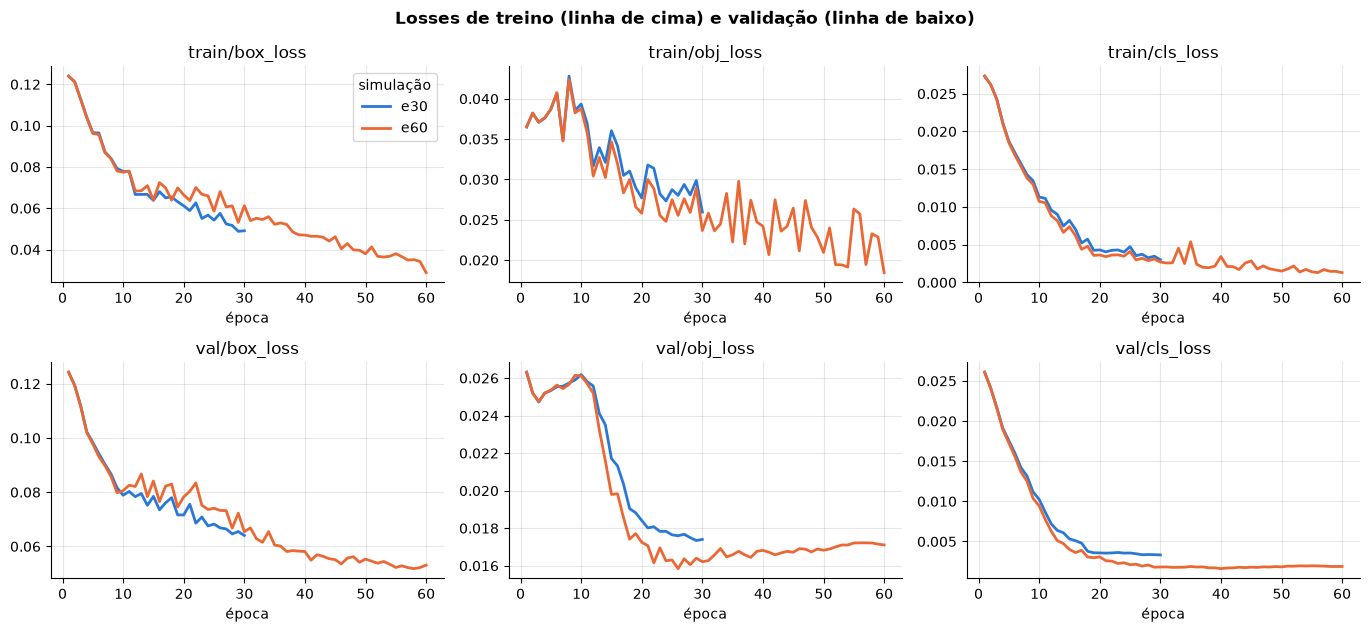

In [11]:
def plot_history(columns: list[str], title: str) -> None:
    rows = -(-len(columns) // PANEL_COLUMNS)
    fig, axes = plt.subplots(rows, PANEL_COLUMNS, figsize=(PANEL_SIZE[0] * PANEL_COLUMNS, PANEL_SIZE[1] * rows), squeeze=False)
    for ax in axes.flat[len(columns):]:
        ax.axis("off")
    for ax, column in zip(axes.flat, columns):
        for name, history in HISTORY.items():
            ax.plot(history["epoch"] + 1, history[column], color=RUN_COLORS[name], linewidth=LINE_WIDTH, label=name)
        style_axis(ax, PANEL_TITLES.get(column, column))
        ax.set_xlabel("época")
    axes.flat[0].legend(title="simulação")
    fig.suptitle(title, fontweight="bold")
    fig.tight_layout()
    render(fig)


plot_history(LOSS_COLUMNS, "Losses de treino (linha de cima) e validação (linha de baixo)")

### 3.3 Acurácia e taxa de aprendizado por época (30 × 60)
Quatro métricas, medidas no conjunto de validação ao fim de cada época, e a taxa de aprendizado:
- **precisão (P)**: fração das detecções que estão corretas (poucos alarmes falsos);
- **revocação/recall (R)**: fração dos objetos reais que foram encontrados (poucos objetos perdidos);
- **mAP50**: média, entre as classes, da área sob a curva precisão × revocação, contando como acerto a caixa com sobreposição (IoU) de pelo menos 0,5 com a caixa real;
- **mAP50-95**: a mesma média repetida para IoU de 0,50 a 0,95 em passos de 0,05. Exige caixas bem ajustadas, e não só "no lugar certo";
- **taxa de aprendizado**: sobe durante o aquecimento (*warmup*) e depois decai de forma linear até o fim de cada simulação.

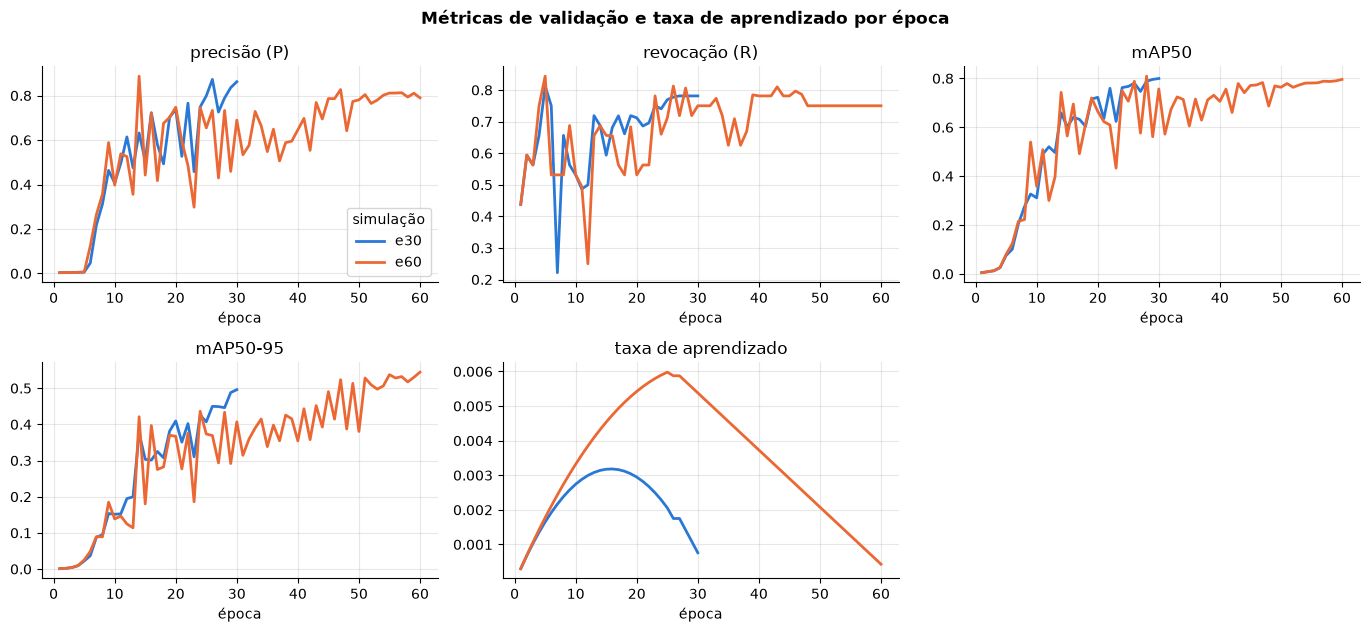

In [12]:
plot_history([*METRIC_COLUMNS, LR_COLUMN], "Métricas de validação e taxa de aprendizado por época")

### 3.4 Convergência e *overfitting*
Lemos as curvas com números em vez de só "a olho":
- **época do `best.pt`**: o YOLOv5 guarda o peso com maior *fitness* na validação, definido por ele como 0,1 × mAP50 + 0,9 × mAP50-95 (`FITNESS_WEIGHTS`);
- **época da menor *loss* de validação** (soma de box, obj e cls) e quanto a *loss* final ficou acima dela. Se a menor *loss* está nas últimas épocas, o modelo ainda estava aprendendo, sem *overfitting*;
- **oscilação** do mAP50-95 nas últimas épocas (desvio-padrão). Ela mede o ruído de uma validação pequena: diferenças entre modelos menores que essa oscilação não são conclusivas;
- **taxa de aprendizado e aquecimento**: o YOLOv5 aquece a taxa de aprendizado por `warmup_epochs` épocas, mas **no mínimo `MIN_WARMUP_ITERATIONS` iterações** (`train.py`), e acumula gradientes até um *batch* nominal de `NOMINAL_BATCH` imagens antes de cada atualização de pesos. Com poucas imagens, cada época tem poucas iterações, e essas duas regras pesam muito: calculamos quanto de cada treino foi gasto em aquecimento.

In [13]:
FITNESS_WEIGHTS = {"metrics/mAP_0.5": 0.1, "metrics/mAP_0.5:0.95": 0.9}
STABILITY_WINDOW = 5
LOSS_TIE_TOLERANCE = 0.05
LR_DIGITS = 4
MIN_WARMUP_ITERATIONS = 100
NOMINAL_BATCH = 64
BEST_EPOCH, MIN_LOSS_EPOCH = "época do best.pt", "época da menor loss de validação"
LOSS_RATIO, MAP_STD = "loss de validação final / mínima", "oscilação do mAP50-95 (desvio)"


def fitness(history: pd.DataFrame) -> pd.Series:
    return sum(history[column] * weight for column, weight in FITNESS_WEIGHTS.items())


def convergence_summary(name: str) -> dict[str, object]:
    history = HISTORY[name]
    val_loss = history[VAL_LOSS_COLUMNS].sum(axis=1)
    return {
        "modelo": name, "épocas": EPOCH_PLAN[name],
        BEST_EPOCH: int(fitness(history).idxmax()) + 1,
        MIN_LOSS_EPOCH: int(val_loss.idxmin()) + 1,
        LOSS_RATIO: val_loss.iloc[-1] / val_loss.min(),
        MAP_STD: history[MAP_HISTORY_COLUMN].tail(STABILITY_WINDOW).std(),
    }


def still_learning(name: str) -> bool:
    row = CONVERGENCE.loc[name]
    return row[MIN_LOSS_EPOCH] > EPOCH_PLAN[name] - STABILITY_WINDOW or row[LOSS_RATIO] <= 1 + LOSS_TIE_TOLERANCE


def convergence_line(name: str) -> str:
    row = CONVERGENCE.loc[name]
    verdict = ("a loss de validação termina no mínimo ou perto dele: sem sinal de *overfitting*" if still_learning(name) else
               f"a loss de validação terminou {fmt_pct(row[LOSS_RATIO] - 1, 1)} acima da mínima: sinal de *overfitting*")
    return (f"`{name}`: `best.pt` na época {int(row[BEST_EPOCH])} de {EPOCH_PLAN[name]}, menor loss de validação na época "
            f"{int(row[MIN_LOSS_EPOCH])}; {verdict}; mAP50-95 oscilou ±{fmt_num(row[MAP_STD])} nas últimas {STABILITY_WINDOW} épocas")


def train_iterations() -> int:
    return -(-INVENTORY.loc["train", "imagens"] // BATCH)


def warmup_epochs(name: str) -> float:
    hyp = yaml.safe_load((RUNS_DIR / "train" / name / "hyp.yaml").read_text(encoding="utf-8"))
    iterations = train_iterations()
    return max(round(hyp["warmup_epochs"] * iterations), MIN_WARMUP_ITERATIONS) / iterations


def warmup_line() -> str:
    shares = " e ".join(f"{fmt_pct(min(warmup_epochs(name) / EPOCH_PLAN[name], 1))} do treino de `{name}`" for name in EPOCH_PLAN)
    return (f"Com {train_iterations()} iterações por época, o aquecimento mínimo de {MIN_WARMUP_ITERATIONS} iterações dura "
            f"{fmt_num(warmup_epochs(LONG_RUN), 0)} épocas, ou seja, ocupa {shares}. Além disso, os gradientes são acumulados "
            f"até {NOMINAL_BATCH} imagens, uma atualização de pesos a cada {NOMINAL_BATCH // BATCH} iterações. Em datasets pequenos, "
            f"dobrar as épocas dá ao modelo muito mais treino efetivo depois do aquecimento")


def learning_rate_line() -> str:
    epoch = EPOCH_PLAN[SHORT_RUN]
    rates = {name: HISTORY[name][LR_COLUMN].iloc[epoch - 1] for name in EPOCH_PLAN}
    return (f"Na época {epoch}, a taxa de aprendizado de `{SHORT_RUN}` já tinha caído a {fmt_num(rates[SHORT_RUN], LR_DIGITS)}, "
            f"enquanto a de `{LONG_RUN}` ainda era {fmt_num(rates[LONG_RUN], LR_DIGITS)} ({fmt_num(rates[LONG_RUN] / rates[SHORT_RUN], 0)}×): "
            f"`{LONG_RUN}` passa mais épocas aprendendo com passos grandes e só depois faz o ajuste fino")


CONVERGENCE = pd.DataFrame(map(convergence_summary, EPOCH_PLAN)).set_index("modelo")
show_markdown([*map(convergence_line, EPOCH_PLAN), warmup_line(), learning_rate_line()], "Convergência")
CONVERGENCE.round(4)

#### Convergência
- `e30`: `best.pt` na época 30 de 30, menor loss de validação na época 30; a loss de validação termina no mínimo ou perto dele: sem sinal de *overfitting*; mAP50-95 oscilou ±0,024 nas últimas 5 épocas
- `e60`: `best.pt` na época 60 de 60, menor loss de validação na época 58; a loss de validação termina no mínimo ou perto dele: sem sinal de *overfitting*; mAP50-95 oscilou ±0,010 nas últimas 5 épocas
- Com 4 iterações por época, o aquecimento mínimo de 100 iterações dura 25 épocas, ou seja, ocupa 83 % do treino de `e30` e 42 % do treino de `e60`. Além disso, os gradientes são acumulados até 64 imagens, uma atualização de pesos a cada 4 iterações. Em datasets pequenos, dobrar as épocas dá ao modelo muito mais treino efetivo depois do aquecimento
- Na época 30, a taxa de aprendizado de `e30` já tinha caído a 0,0008, enquanto a de `e60` ainda era 0,0054 (7×): `e60` passa mais épocas aprendendo com passos grandes e só depois faz o ajuste fino

,épocas,época do best.pt,época da menor loss de validação,loss de validação final / mínima,oscilação do mAP50-95 (desvio)
modelo,,,,,
e30,30,30,30,1.0000,0.0241
e60,60,60,58,1.0171,0.0097


## 4. Validação e teste

### 4.1 Avaliação com `val.py`
Avaliamos o melhor peso (`best.pt`) de cada simulação em dois splits:
- **validação**: as mesmas imagens que escolheram o `best.pt`, portanto levemente otimista;
- **teste** (`task="test"`): imagens que não foram usadas no treino nem na escolha do `best.pt`. É a estimativa honesta do desempenho em fotos novas.

Importamos o `val.py` do YOLOv5 e chamamos `val.run`, que devolve as métricas diretamente. O *logger* e as barras de progresso do YOLOv5 ficam silenciados durante a avaliação (`quiet_yolo`), e só imprimimos um resumo por avaliação. Usamos *batch* 1 para que o tempo de inferência informado seja **por imagem**. Com *batch* 1, o *letterbox* de cada imagem é diferente do usado na validação final do `train.py` (*batch* 32), então os números diferem um pouco daquele resumo; os desta seção são os de referência. Os relatórios completos, com os gráficos de diagnóstico da seção 5.4, ficam em `yolov5/runs/val/<modelo>_<split>`.

In [14]:
EVAL_TASKS = ("val", "test")
EVAL_BATCH = 1
EVAL_WORKERS = 0
PRECISION, RECALL = "precisão (P)", "revocação (R)"
HEADLINE_METRICS = [PRECISION, RECALL, "mAP50", "mAP50-95"]

if str(YOLO_DIR) not in sys.path:
    sys.path.insert(0, str(YOLO_DIR))
import val as yolo_val
from utils.general import LOGGER as YOLO_LOGGER


@contextlib.contextmanager
def quiet_yolo():
    level = YOLO_LOGGER.level
    YOLO_LOGGER.setLevel(logging.ERROR)
    try:
        with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
            yield
    finally:
        YOLO_LOGGER.setLevel(level)


def best_weights(name: str) -> Path:
    return RUNS_DIR / "train" / name / "weights" / "best.pt"


def evaluate(name: str, task: str) -> dict[str, object]:
    with quiet_yolo():
        (precision, recall, map50, map50_95, *_), per_class, speed = yolo_val.run(
            data=DATA_YAML, weights=best_weights(name), batch_size=EVAL_BATCH, imgsz=IMG_SIZE, task=task,
            device=DEVICE, workers=EVAL_WORKERS, project=RUNS_DIR / "val", name=f"{name}_{task}", exist_ok=True,
        )
    print(f"{name} | {task}: P={fmt_num(precision)} R={fmt_num(recall)} mAP50={fmt_num(map50)} "
          f"mAP50-95={fmt_num(map50_95)} -> runs/val/{name}_{task}")
    return {
        "modelo": name, "split": task, PRECISION: precision, RECALL: recall,
        "mAP50": map50, "mAP50-95": map50_95,
        **{f"mAP50-95 {cls}": per_class[index] for index, cls in enumerate(CLASS_NAMES)},
        "inferência (ms/img)": speed[1],
    }


EVALUATION = pd.DataFrame([evaluate(name, task) for name in EPOCH_PLAN for task in EVAL_TASKS])
EVALUATION.round(3)

e30 | val: P=0,868 R=0,781 mAP50=0,800 mAP50-95=0,515 -> runs/val/e30_val


e30 | test: P=0,777 R=0,730 mAP50=0,785 mAP50-95=0,467 -> runs/val/e30_test


e60 | val: P=0,790 R=0,750 mAP50=0,791 mAP50-95=0,534 -> runs/val/e60_val


e60 | test: P=0,984 R=0,764 mAP50=0,809 mAP50-95=0,513 -> runs/val/e60_test


,modelo,split,precisão (P),revocação (R),mAP50,mAP50-95,mAP50-95 vaca,mAP50-95 trator,inferência (ms/img)
0,e30,val,0.868,0.781,0.800,0.515,0.341,0.689,18.451
1,e30,test,0.777,0.730,0.785,0.467,0.420,0.514,20.365
2,e60,val,0.790,0.750,0.791,0.534,0.358,0.711,18.547
3,e60,test,0.984,0.764,0.809,0.513,0.392,0.634,17.941


## 5. Comparação entre as simulações

### 5.1 Tabela consolidada
Juntamos, para cada modelo:
- **desempenho**: tempo total de treino, tempo do laço de épocas, segundos por época e tempo de inferência por imagem no `val.py`;
- **erro**: *losses* finais de treino e de validação, da última época do `results.csv`;
- **acurácia** no teste.

In [15]:
def training_summary(name: str) -> dict[str, object]:
    last = HISTORY[name].iloc[-1]
    return {
        "modelo": name, "épocas": EPOCH_PLAN[name],
        "treino total (s)": TRAIN_TIMES[name]["total_s"], "laço de épocas (s)": TRAIN_TIMES[name]["epoch_loop_s"],
        "s/época": TRAIN_TIMES[name]["epoch_loop_s"] / EPOCH_PLAN[name],
        **{column: last[column] for column in LOSS_COLUMNS},
    }


TRAINING = pd.DataFrame(map(training_summary, EPOCH_PLAN)).set_index("modelo")
TEST_METRICS = EVALUATION.query("split == 'test'").drop(columns="split").set_index("modelo")
COMPARISON = TRAINING.join(TEST_METRICS.add_prefix("teste "))
COMPARISON.T.round(4)

modelo,e30,e60
épocas,30.0000,60.0000
treino total (s),162.0113,181.8644
laço de épocas (s),64.8000,90.0000
s/época,2.1600,1.5000
train/box_loss,0.0491,0.0288
train/obj_loss,0.0260,0.0184
train/cls_loss,0.0030,0.0013
val/box_loss,0.0640,0.0531
val/obj_loss,0.0174,0.0171
val/cls_loss,0.0033,0.0019


### 5.2 Acurácia lado a lado
Barras agrupadas com as quatro métricas principais, em validação e teste, para os dois modelos. Todas estão na mesma escala, de 0 a 1.

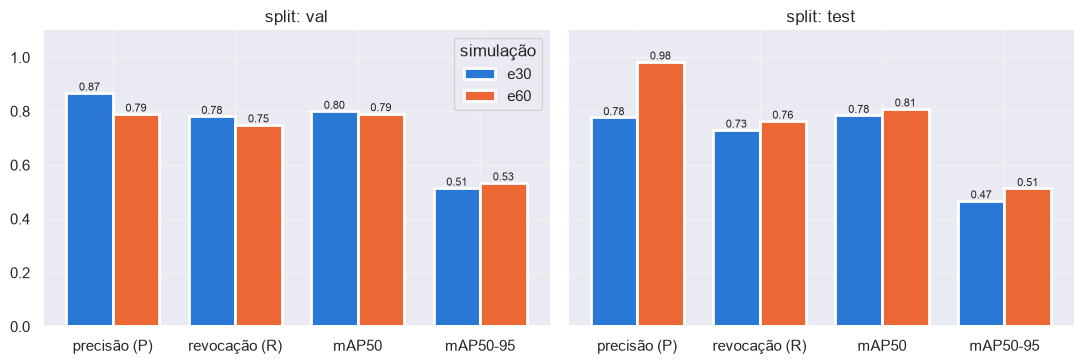

In [16]:
BAR_WIDTH = 0.38
ACCURACY_FIGSIZE = (11.0, 3.8)
SCORE_AXIS_TOP = 1.1
BAR_LABEL_SIZE = 8


def plot_accuracy() -> None:
    fig, axes = plt.subplots(1, len(EVAL_TASKS), figsize=ACCURACY_FIGSIZE, sharey=True)
    positions = range(len(HEADLINE_METRICS))
    for ax, task in zip(axes, EVAL_TASKS):
        scores = EVALUATION.query("split == @task").set_index("modelo")[HEADLINE_METRICS]
        for offset, name in enumerate(EPOCH_PLAN):
            bars = ax.bar([p + offset * BAR_WIDTH for p in positions], scores.loc[name], BAR_WIDTH,
                          color=RUN_COLORS[name], edgecolor="white", linewidth=LINE_WIDTH, label=name)
            ax.bar_label(bars, fmt="%.2f", fontsize=BAR_LABEL_SIZE)
        ax.set_xticks([p + BAR_WIDTH / 2 for p in positions], HEADLINE_METRICS)
        ax.set_ylim(0, SCORE_AXIS_TOP)
        style_axis(ax, f"split: {task}")
    axes[0].legend(title="simulação")
    fig.tight_layout()
    render(fig)


plot_accuracy()

### 5.3 Escolha do melhor modelo
**Critério: mAP50-95 na validação.** Por quê:
- é a métrica principal do COCO e quase toda a *fitness* que o próprio YOLOv5 usa para escolher o `best.pt`;
- resume, num só número, precisão e revocação em todos os limiares de confiança, e ainda cobra caixas bem ajustadas. P e R isolados dependem do limiar escolhido e podem trocar um pelo outro;
- é medida na **validação**, e não no teste. Escolher pelo teste faria do teste parte do ajuste e deixaria a estimativa final otimista. O teste fica reservado para confirmar a escolha.

Em caso de empate, decide o teste e, por fim, o modelo mais barato de treinar.

In [17]:
SCORE_TABLE = EVALUATION.set_index(["split", "modelo"])
SCORES = EVALUATION.pivot(index="modelo", columns="split", values="mAP50-95").join(TRAINING["épocas"])
BEST = SCORES.sort_values(["val", "test", "épocas"], ascending=[False, False, True]).index[0]
OTHER = next(name for name in EPOCH_PLAN if name != BEST)
print(f"Melhor modelo: {BEST}")
SCORES.round(4)

Melhor modelo: e60


,test,val,épocas
modelo,,,
e30,0.4673,0.5149,30
e60,0.5133,0.5342,60


### 5.4 Diagnósticos do YOLOv5 para o modelo escolhido
O `train.py` e o `val.py` gravam gráficos de diagnóstico. Mostramos os quatro mais informativos do modelo escolhido; o `results.png` não entra porque repete as curvas das seções 3.2 e 3.3, já sobrepostas para os dois modelos.
- **`labels.jpg` (treino)**: quantidade de caixas por classe e distribuição de posição e tamanho. Caixas pequenas concentradas perto da origem do gráfico de largura × altura indicam objetos pequenos, os mais difíceis para o detector.
- **Matriz de confusão (teste)**: colunas são a classe real e linhas a prevista, normalizadas por coluna. A linha `background` mostra objetos reais **não detectados**; a coluna `background` mostra **alarmes falsos**. Fora da diagonal entre `vaca` e `trator` estaria a troca de classe.
- **Curva PR (teste)**: precisão × revocação ao variar o limiar de confiança; a área sob cada curva é o AP50 da classe. Curva colada no canto superior direito = classe fácil.
- **Curva F1 × confiança (teste)**: mostra em que limiar de confiança o equilíbrio entre precisão e revocação é melhor. A seção 6.7 confere o limiar usado na detecção.

Com poucas imagens de teste, essas curvas têm degraus grandes: cada degrau é um objeto. A seção 6.5 reproduz a matriz de confusão em **contagens absolutas**, mais fáceis de ler com uma amostra pequena.

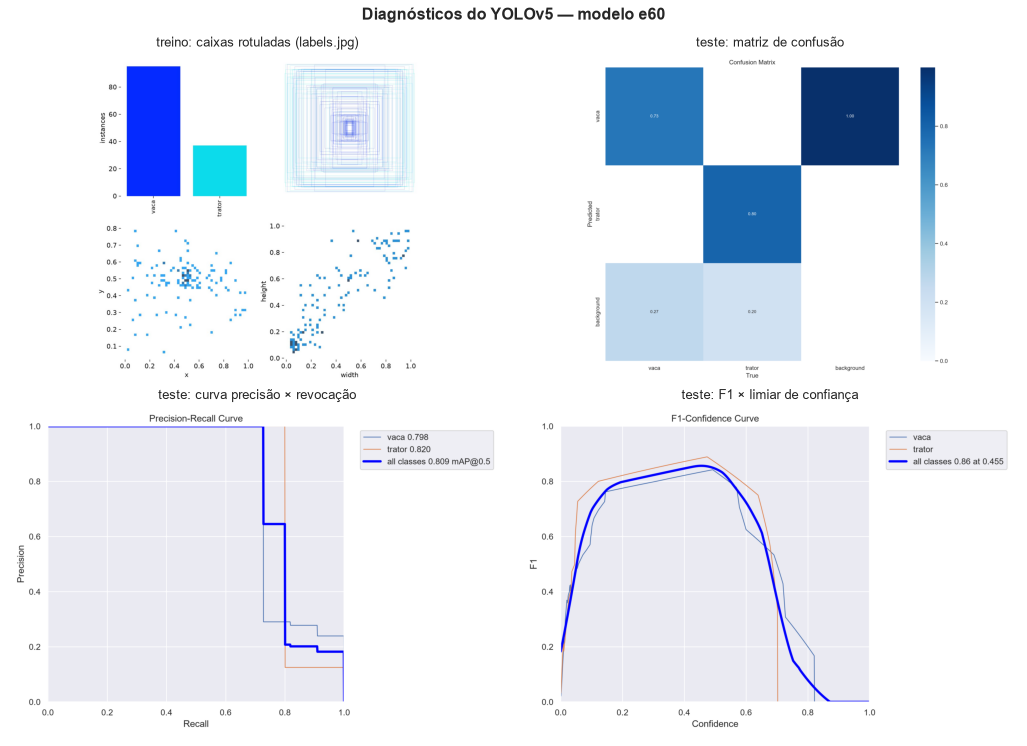

#### Leitura dos diagnósticos (e60)
- mAP50-95 por classe no teste: `vaca` 0,392, `trator` 0,634. `vaca` é a classe difícil (95 caixas de treino contra 37 de `trator`), mesmo tendo mais caixas de treino: o problema não é falta de exemplos, e sim cenas densas com objetos menores e sobrepostos
- Precisão 0,984 e revocação 0,764 no teste: o erro dominante é **deixar de encontrar** objetos (linha `background` da matriz)

In [18]:
DIAGNOSTIC_GRID = (2, 2)
DIAGNOSTIC_FIGSIZE = (13.0, 9.5)
DIAGNOSTIC_DPI = 80


def diagnostic_files(name: str) -> dict[str, Path]:
    test_dir = RUNS_DIR / "val" / f"{name}_test"
    return {
        "treino: caixas rotuladas (labels.jpg)": RUNS_DIR / "train" / name / "labels.jpg",
        "teste: matriz de confusão": test_dir / "confusion_matrix.png",
        "teste: curva precisão × revocação": test_dir / "PR_curve.png",
        "teste: F1 × limiar de confiança": test_dir / "F1_curve.png",
    }


def show_diagnostics(name: str) -> None:
    files = diagnostic_files(name)
    missing = [path.name for path in files.values() if not path.exists()]
    if missing:
        print(f"Gráficos não encontrados: {missing}")
    fig, axes = plt.subplots(*DIAGNOSTIC_GRID, figsize=DIAGNOSTIC_FIGSIZE, dpi=DIAGNOSTIC_DPI)
    for ax in axes.flat:
        ax.axis("off")
    for ax, (title, path) in zip(axes.flat, ((title, path) for title, path in files.items() if path.exists())):
        ax.imshow(mpimg.imread(path))
        ax.set_title(title)
    fig.suptitle(f"Diagnósticos do YOLOv5 — modelo {name}", fontweight="bold")
    fig.tight_layout()
    render(fig)


def diagnostic_lines(name: str) -> list[str]:
    test = SCORE_TABLE.loc[("test", name)]
    per_class = {cls: test[f"mAP50-95 {cls}"] for cls in CLASS_NAMES}
    hardest, easiest = min(per_class, key=per_class.get), max(per_class, key=per_class.get)
    boxes = {cls: INVENTORY.loc["train", f"objetos {cls}"] for cls in (hardest, easiest)}
    cause = ("mesmo tendo mais caixas de treino: o problema não é falta de exemplos, e sim cenas densas com objetos menores e sobrepostos"
             if boxes[hardest] >= boxes[easiest] else "e também tem menos caixas de treino")
    return [
        "mAP50-95 por classe no teste: " + ", ".join(f"`{cls}` {fmt_num(value)}" for cls, value in per_class.items())
        + f". `{hardest}` é a classe difícil ({boxes[hardest]} caixas de treino contra {boxes[easiest]} de `{easiest}`), {cause}",
        f"Precisão {fmt_num(test[PRECISION])} e revocação {fmt_num(test[RECALL])} no teste: o erro dominante é "
        + ("**deixar de encontrar** objetos (linha `background` da matriz)" if test[RECALL] < test[PRECISION] else
           "**alarme falso** (coluna `background` da matriz)"),
    ]


show_diagnostics(BEST)
show_markdown(diagnostic_lines(BEST), f"Leitura dos diagnósticos ({BEST})")

## 6. Detecção nas imagens de teste

### 6.1 `detect.py` com os dois modelos
Rodamos o `detect.py` sobre `dataset/images/test` com cada `best.pt`, com confiança mínima `CONF_THRES` (0,25, o padrão do YOLOv5). Cada execução cria uma nova pasta `yolov5/runs/detect/expX`, que identificamos comparando as pastas antes e depois. Também guardamos as caixas previstas (`--save-txt --save-conf`), usadas na análise de erros, e o tempo de inferência por imagem relatado pelo próprio script.

In [19]:
DETECT_DIR = RUNS_DIR / "detect"
CONF_THRES = 0.25
SPEED_PATTERN = re.compile(r"([\d.]+)ms inference")
TEST_IMAGES = DATA_ROOT / "images" / "test"


def detect(name: str) -> dict[str, object]:
    before = set(DETECT_DIR.glob("exp*"))
    log, _ = run_yolo(
        "detect.py", "--weights", best_weights(name), "--source", TEST_IMAGES, "--img", IMG_SIZE,
        "--conf-thres", CONF_THRES, "--device", DEVICE, "--project", DETECT_DIR, "--save-txt", "--save-conf",
    )
    (folder,) = set(DETECT_DIR.glob("exp*")) - before
    return {"modelo": name, "pasta": folder, "detect.py inferência (ms/img)": float(SPEED_PATTERN.findall(log)[-1])}


DETECTIONS = pd.DataFrame(map(detect, EPOCH_PLAN)).set_index("modelo")
for name, folder in DETECTIONS["pasta"].items():
    print(f"{name}: resultados salvos em {folder}")
DETECTIONS

Model summary: 68 layers, 7,015,519 parameters, 0 gradients
image 1/8 C:\Users\leelt\fiap-fase6\dataset\images\test\trator_037.jpg: 480x640 1 trator, 14.1ms
image 2/8 C:\Users\leelt\fiap-fase6\dataset\images\test\trator_038.jpg: 448x640 1 trator, 13.2ms
image 3/8 C:\Users\leelt\fiap-fase6\dataset\images\test\trator_039.jpg: 448x640 1 trator, 9.5ms
image 4/8 C:\Users\leelt\fiap-fase6\dataset\images\test\trator_040.jpg: 480x640 1 trator, 8.6ms
image 5/8 C:\Users\leelt\fiap-fase6\dataset\images\test\vaca_037.jpg: 448x640 1 vaca, 11.5ms
image 6/8 C:\Users\leelt\fiap-fase6\dataset\images\test\vaca_038.jpg: 512x640 1 vaca, 15.5ms
image 7/8 C:\Users\leelt\fiap-fase6\dataset\images\test\vaca_039.jpg: 640x448 2 vacas, 17.6ms
image 8/8 C:\Users\leelt\fiap-fase6\dataset\images\test\vaca_040.jpg: 448x640 3 vacas, 10.5ms
Speed: 0.6ms pre-process, 12.6ms inference, 13.6ms NMS per image at shape (1, 3, 640, 640)
Results saved to C:\Users\leelt\fiap-fase6\yolov5\runs\detect\exp
8 labels saved to C:\Us

Model summary: 68 layers, 7,015,519 parameters, 0 gradients
image 1/8 C:\Users\leelt\fiap-fase6\dataset\images\test\trator_037.jpg: 480x640 1 trator, 19.7ms
image 2/8 C:\Users\leelt\fiap-fase6\dataset\images\test\trator_038.jpg: 448x640 1 trator, 10.6ms
image 3/8 C:\Users\leelt\fiap-fase6\dataset\images\test\trator_039.jpg: 448x640 1 trator, 8.8ms
image 4/8 C:\Users\leelt\fiap-fase6\dataset\images\test\trator_040.jpg: 480x640 1 trator, 10.2ms
image 5/8 C:\Users\leelt\fiap-fase6\dataset\images\test\vaca_037.jpg: 448x640 1 vaca, 10.2ms
image 6/8 C:\Users\leelt\fiap-fase6\dataset\images\test\vaca_038.jpg: 512x640 1 vaca, 18.2ms
image 7/8 C:\Users\leelt\fiap-fase6\dataset\images\test\vaca_039.jpg: 640x448 2 vacas, 15.6ms
image 8/8 C:\Users\leelt\fiap-fase6\dataset\images\test\vaca_040.jpg: 448x640 4 vacas, 8.4ms
Speed: 0.6ms pre-process, 12.7ms inference, 12.2ms NMS per image at shape (1, 3, 640, 640)
Results saved to C:\Users\leelt\fiap-fase6\yolov5\runs\detect\exp2
8 labels saved to C:\U

,pasta,detect.py inferência (ms/img)
modelo,,
e30,C:\Users\leelt\fiap-fase6\yolov5\runs\detect\exp,12.6
e60,C:\Users\leelt\fiap-fase6\yolov5\runs\detect\exp2,12.7


### 6.2 Imagens de teste processadas pelo melhor modelo
Exibimos em grade as imagens anotadas pelo `detect.py` (caixa, classe e confiança) do melhor modelo. É o material para apresentar ao cliente. A mesma grade é gravada em `docs/figuras/teste_melhor_modelo.png`, em resolução menor no notebook para mantê-lo leve. A legenda credita as fotos.

Figura salva em C:\Users\leelt\fiap-fase6\docs\figuras\teste_melhor_modelo.png (692 KB)


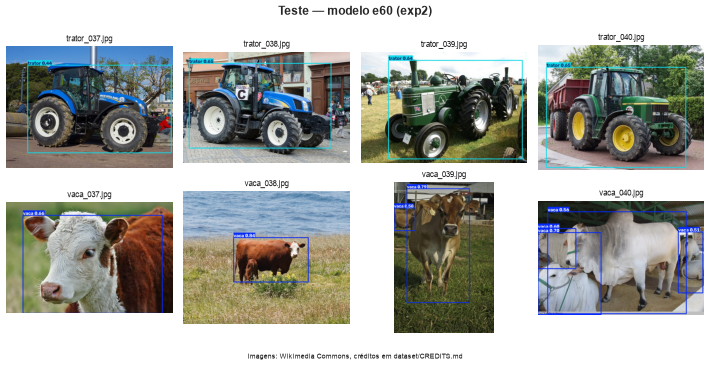

In [20]:
GRID_COLUMNS = 4
GRID_CELL = 3.0
GRID_DPI = 60
SAVED_GRID_DPI = 85
GRID_TITLE_SIZE = 9
CAPTION_SIZE = 8
CAPTION_MARGIN = 0.04
IMAGE_CAPTION = "Imagens: Wikimedia Commons, créditos em dataset/CREDITS.md"
FIGURES_DIR = PROJECT_DIR / "docs" / "figuras"
BEST_GRID_FILE = FIGURES_DIR / "teste_melhor_modelo.png"


def save_figure(fig: plt.Figure, save_to: Path) -> None:
    save_to.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(save_to, dpi=SAVED_GRID_DPI, bbox_inches="tight")
    print(f"Figura salva em {save_to} ({save_to.stat().st_size // 1024} KB)")


def show_grid(folder: Path, title: str, save_to: Path | None = None) -> None:
    images = sorted(folder.glob(f"*{IMAGE_SUFFIX}"))
    rows = -(-len(images) // GRID_COLUMNS)
    fig, axes = plt.subplots(rows, GRID_COLUMNS, figsize=(GRID_CELL * GRID_COLUMNS, GRID_CELL * rows), dpi=GRID_DPI, squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, image in zip(axes.flat, images):
        ax.imshow(mpimg.imread(image))
        ax.set_title(image.name, fontsize=GRID_TITLE_SIZE)
    fig.suptitle(title, fontweight="bold")
    fig.text(0.5, 0, IMAGE_CAPTION, ha="center", fontsize=CAPTION_SIZE)
    fig.tight_layout(rect=(0, CAPTION_MARGIN, 1, 1))
    if save_to is not None:
        save_figure(fig, save_to)
    render(fig)


show_grid(DETECTIONS.loc[BEST, "pasta"], f"Teste — modelo {BEST} ({DETECTIONS.loc[BEST, 'pasta'].name})", BEST_GRID_FILE)

### 6.3 Mesmas imagens com o outro modelo
Para a comparação visual, a mesma grade com a outra simulação.

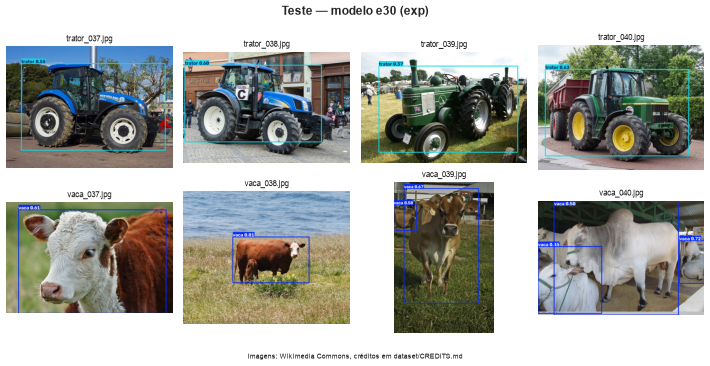

In [21]:
show_grid(DETECTIONS.loc[OTHER, "pasta"], f"Teste — modelo {OTHER} ({DETECTIONS.loc[OTHER, 'pasta'].name})")

### 6.4 Análise de erros: cada caixa prevista contra cada caixa real
Acertar "a classe da foto" não basta: uma foto de rebanho com cinco vacas em que o modelo marca três tem a classe certa e, mesmo assim, perdeu dois animais. Por isso comparamos as caixas do `detect.py` com as caixas rotuladas, **objeto a objeto**:
1. as previsões de cada imagem são percorridas da maior para a menor confiança;
2. cada previsão é casada com a caixa real ainda livre de maior **IoU** (interseção ÷ união das duas caixas);
3. com IoU ≥ `MATCH_IOU` (0,5, o mesmo critério do mAP50) o par é um acerto (**VP**) se as classes coincidem, ou uma **troca** de classe se não;
4. previsão sem par é **alarme falso (FP)**; caixa real sem par é **objeto perdido (FN)**.

Para cada alarme falso guardamos também o maior IoU com alguma caixa real: um FP com IoU entre `NEAR_MISS_IOU` e 0,5 é uma caixa **no lugar certo, mas mal ajustada** (por exemplo, uma caixa só cobrindo dois animais), e não um objeto inventado no fundo. A tabela mostra o resumo por imagem do melhor modelo.

In [22]:
MATCH_IOU = 0.5
NEAR_MISS_IOU = 0.1
BACKGROUND = "fundo"
TP, FP, FN, SWAP = "VP", "FP", "FN", "troca"
OUTCOMES = (TP, FP, FN, SWAP)
TEST_SPLIT = "test"


def corners(row: list[float]) -> tuple[float, float, float, float]:
    _, x_center, y_center, width, height = row[:LABEL_FIELDS]
    return x_center - width / 2, y_center - height / 2, x_center + width / 2, y_center + height / 2


def box_iou(first: list[float], second: list[float]) -> float:
    a, b = corners(first), corners(second)
    inter_w = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))
    inter_h = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = inter_w * inter_h
    union = first[3] * first[4] + second[3] * second[4] - inter
    return inter / union if union > 0 else 0.0


def outcome(truth: list[float] | None, prediction: list[float] | None) -> str:
    if truth is None:
        return FP
    if prediction is None:
        return FN
    return TP if int(truth[0]) == int(prediction[0]) else SWAP


def match_record(truth: list[float] | None, prediction: list[float] | None, overlap: float) -> dict[str, object]:
    return {
        "classe real": CLASS_NAMES[int(truth[0])] if truth is not None else BACKGROUND,
        "classe prevista": CLASS_NAMES[int(prediction[0])] if prediction is not None else BACKGROUND,
        "resultado": outcome(truth, prediction), "IoU": overlap,
        "confiança": prediction[-1] if prediction is not None else np.nan,
        "área relativa": truth[3] * truth[4] if truth is not None else np.nan,
        "caixa real": truth, "caixa prevista": prediction,
    }


def match_image(truths: list[list[float]], predictions: list[list[float]]) -> list[dict[str, object]]:
    free = set(range(len(truths)))
    records = []
    for prediction in sorted(predictions, key=lambda row: -row[-1]):
        overlaps = {index: box_iou(truths[index], prediction) for index in free}
        index = max(overlaps, key=overlaps.get, default=None)
        overlap = overlaps.get(index, 0.0)
        if overlap >= MATCH_IOU:
            free.discard(index)
            records.append(match_record(truths[index], prediction, overlap))
        else:
            best_any = max((box_iou(truth, prediction) for truth in truths), default=0.0)
            records.append(match_record(None, prediction, best_any))
    return records + [match_record(truths[index], None, 0.0) for index in sorted(free)]


def match_model(name: str, min_conf: float = CONF_THRES) -> pd.DataFrame:
    folder = DETECTIONS.loc[name, "pasta"] / "labels"
    rows = []
    for image in split_images(TEST_SPLIT):
        truths = read_label_rows(label_path(TEST_SPLIT, image.stem))
        predictions = [row for row in read_label_rows(folder / f"{image.stem}.txt") if row[-1] >= min_conf]
        rows += [{"imagem": image.name, **record} for record in match_image(truths, predictions)]
    return pd.DataFrame(rows)


def per_image_summary(matches: pd.DataFrame) -> pd.DataFrame:
    counts = pd.crosstab(matches["imagem"], matches["resultado"]).reindex(columns=list(OUTCOMES), fill_value=0)
    counts.insert(0, "objetos reais", counts[TP] + counts[FN] + counts[SWAP])
    counts["classe da foto"] = [class_from_name(image) for image in counts.index]
    counts["classe dominante prevista"] = (matches.dropna(subset=["confiança"]).sort_values("confiança", ascending=False)
                                           .groupby("imagem")["classe prevista"].first().reindex(counts.index, fill_value=BACKGROUND))
    return counts


MATCHES = {name: match_model(name) for name in EPOCH_PLAN}
PER_IMAGE = {name: per_image_summary(matches) for name, matches in MATCHES.items()}
PER_IMAGE[BEST]

resultado,objetos reais,VP,FP,FN,troca,classe da foto,classe dominante prevista
imagem,,,,,,,
trator_037.jpg,1,1,0,0,0,trator,trator
trator_038.jpg,1,1,0,0,0,trator,trator
trator_039.jpg,2,1,0,1,0,trator,trator
trator_040.jpg,1,1,0,0,0,trator,trator
vaca_037.jpg,2,1,0,1,0,vaca,vaca
vaca_038.jpg,2,1,0,1,0,vaca,vaca
vaca_039.jpg,2,2,0,0,0,vaca,vaca
vaca_040.jpg,5,3,1,2,0,vaca,vaca


### 6.5 Matriz de confusão em contagens e ponto de operação
Com o casamento da seção 6.4, montamos para os dois modelos:
- a **matriz de confusão em contagens** (linhas: classe real; colunas: classe prevista; `fundo` = nenhum objeto), equivalente à do YOLOv5 da seção 5.4. Pequenas diferenças são esperadas, porque o YOLOv5 usa IoU 0,45 no casamento e outro limiar de NMS na validação;
- as métricas no **ponto de operação** usado pelo cliente (confiança ≥ `CONF_THRES`, IoU ≥ 0,5): P, R e **F1** (média harmônica de P e R), além do **IoU médio dos acertos**, que mede o ajuste das caixas e explica diferenças de mAP50-95 quando o mAP50 empata.

Diferente do mAP, que varre todos os limiares, estas métricas descrevem exatamente o que o cliente vê nas imagens anotadas.

In [23]:
CONFUSION_LABELS = [*CLASS_NAMES, BACKGROUND]


def confusion_counts(matches: pd.DataFrame) -> pd.DataFrame:
    table = pd.crosstab(matches["classe real"], matches["classe prevista"])
    return table.reindex(index=CONFUSION_LABELS, columns=CONFUSION_LABELS, fill_value=0).rename_axis(
        index="real ↓ / prevista →", columns=None)


def outcome_counts(matches: pd.DataFrame) -> dict[str, float]:
    counts = matches["resultado"].value_counts()
    tp, fn_only, fp_only, swaps = (int(counts.get(key, 0)) for key in (TP, FN, FP, SWAP))
    return {"tp": tp, "fp": fp_only + swaps, "fn": fn_only + swaps,
            "iou_sum": matches.loc[matches["resultado"] == TP, "IoU"].sum()}


def operating_metrics(counts: dict[str, float]) -> dict[str, float]:
    tp, fp, fn = counts["tp"], counts["fp"], counts["fn"]
    return {
        PRECISION: tp / (tp + fp) if tp + fp else 0.0,
        RECALL: tp / (tp + fn) if tp + fn else 0.0,
        "F1": 2 * tp / (2 * tp + fp + fn) if tp + fp + fn else 0.0,
        "IoU médio dos acertos": counts["iou_sum"] / tp if tp else 0.0,
    }


def operating_point(name: str) -> dict[str, object]:
    matches = MATCHES[name]
    found = matches["resultado"].value_counts().reindex(list(OUTCOMES), fill_value=0)
    return {"modelo": name, "objetos reais": int(found[TP] + found[FN] + found[SWAP]), **found.to_dict(),
            **operating_metrics(outcome_counts(matches))}


OPERATING = pd.DataFrame(map(operating_point, EPOCH_PLAN)).set_index("modelo")
for name in EPOCH_PLAN:
    display(Markdown(f"**Matriz de confusão em contagens — `{name}`**"), confusion_counts(MATCHES[name]))
OPERATING.round(3)

**Matriz de confusão em contagens — `e30`**

,vaca,trator,fundo
real ↓ / prevista →,,,
vaca,7,0,4
trator,0,4,1
fundo,0,0,0


**Matriz de confusão em contagens — `e60`**

,vaca,trator,fundo
real ↓ / prevista →,,,
vaca,7,0,4
trator,0,4,1
fundo,1,0,0


,objetos reais,VP,FP,FN,troca,precisão (P),revocação (R),F1,IoU médio dos acertos
modelo,,,,,,,,,
e30,16,11,0,5,0,1.000,0.688,0.815,0.782
e60,16,11,1,5,0,0.917,0.688,0.786,0.823


### 6.6 Onde o modelo erra: casos em destaque
Desenhamos, sobre as fotos originais, as imagens de teste com erro do melhor modelo, das que têm mais erros para as que têm menos:
- **verde pontilhado**: caixa real encontrada;
- **laranja tracejado**: caixa real **perdida** (FN);
- **azul**: previsão correta (VP), com a confiança;
- **vermelho**: alarme falso ou troca de classe, com a confiança.

Abaixo da figura, a leitura para o cliente é gerada a partir dos números: tamanho dos objetos perdidos e natureza dos alarmes falsos. A figura também é gravada em `docs/figuras/erros_teste.png`.

Figura salva em C:\Users\leelt\fiap-fase6\docs\figuras\erros_teste.png (629 KB)


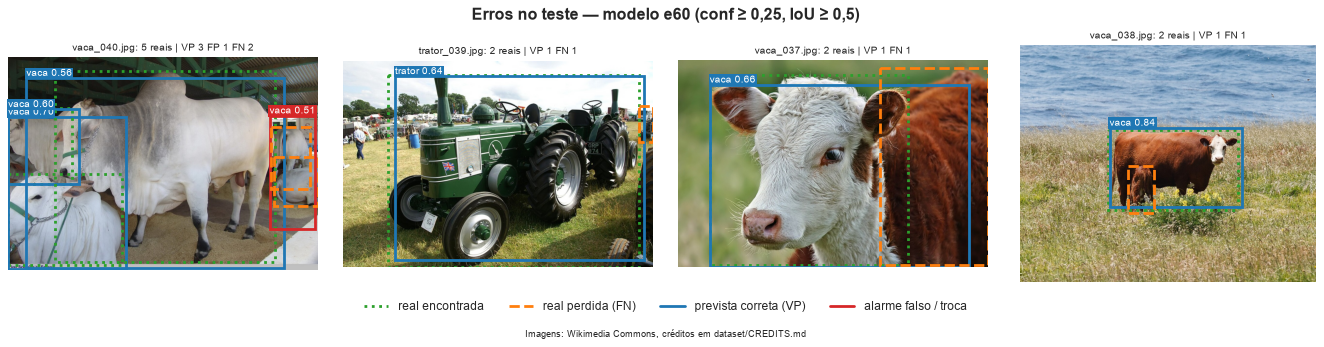

#### Leitura dos erros (e60)
- Objetos encontrados por classe: `vaca` 7 de 11, `trator` 4 de 5
- 5 objetos perdidos, em mediana com 3,3 % da área da imagem, contra 58,5 % dos encontrados: o modelo perde sobretudo **objetos pequenos ou ao fundo**. Imagens com perdas: `trator_039.jpg` (2 objetos), `vaca_037.jpg` (2 objetos), `vaca_038.jpg` (2 objetos), `vaca_040.jpg` (5 objetos)
- Alarmes falsos: 1; com sobreposição parcial a um objeto real (IoU entre 0,1 e 0,5): 1. São caixas no lugar certo mas mal ajustadas, por exemplo uma caixa só para animais lado a lado, e não objetos inventados no fundo
- Nenhuma troca entre `vaca` e `trator`: as duas classes nunca se confundem

In [24]:
MAX_ERROR_IMAGES = 4
ERROR_CELL = 4.2
ERROR_DPI = 80
ERROR_LINE_WIDTH = 2.5
ERROR_FONT_SIZE = 9
ERROR_FIGURE_FILE = FIGURES_DIR / "erros_teste.png"
BOX_STYLES = {
    "found": ("#2ca02c", ":"), "missed": ("#ff7f0e", "--"),
    "correct": ("#1f77b4", "-"), "wrong": ("#d62728", "-"),
}
LEGEND_LABELS = {"found": "real encontrada", "missed": "real perdida (FN)", "correct": "prevista correta (VP)", "wrong": "alarme falso / troca"}


def error_count(summary: pd.DataFrame) -> pd.Series:
    return summary[FP] + summary[FN] + summary[SWAP]


def draw_box(ax: plt.Axes, row: list[float], style: str, size: tuple[int, int], label: str = "") -> None:
    height, width = size
    x0, y0, x1, y1 = corners(row)
    color, line = BOX_STYLES[style]
    ax.add_patch(Rectangle((x0 * width, y0 * height), (x1 - x0) * width, (y1 - y0) * height,
                           fill=False, edgecolor=color, linestyle=line, linewidth=ERROR_LINE_WIDTH))
    if label:
        ax.text(x0 * width, y0 * height, label, color="white", fontsize=ERROR_FONT_SIZE, va="bottom",
                bbox={"facecolor": color, "edgecolor": "none", "pad": 1})


def draw_match(ax: plt.Axes, record: pd.Series, size: tuple[int, int]) -> None:
    if record["caixa real"] is not None:
        draw_box(ax, record["caixa real"], "missed" if record["resultado"] == FN else "found", size)
    if record["caixa prevista"] is not None:
        style = "correct" if record["resultado"] == TP else "wrong"
        draw_box(ax, record["caixa prevista"], style, size, f"{record['classe prevista']} {record['confiança']:.2f}")


def image_title(image: str, summary: pd.Series) -> str:
    return f"{image}: {summary['objetos reais']} reais | " + " ".join(f"{key} {summary[key]}" for key in OUTCOMES if summary[key])


def show_error_cases(name: str, save_to: Path) -> None:
    summary = PER_IMAGE[name]
    worst = error_count(summary).sort_values(ascending=False, kind="stable")
    worst = worst[worst > 0].index[:MAX_ERROR_IMAGES]
    if worst.empty:
        print(f"{name}: nenhum erro no teste com conf ≥ {fmt_num(CONF_THRES, 2)}")
        return
    fig, axes = plt.subplots(1, len(worst), figsize=(ERROR_CELL * len(worst), ERROR_CELL), dpi=ERROR_DPI, squeeze=False)
    for ax, image in zip(axes.flat, worst):
        picture = mpimg.imread(TEST_IMAGES / image)
        ax.imshow(picture)
        ax.axis("off")
        for _, record in MATCHES[name].query("imagem == @image").iterrows():
            draw_match(ax, record, picture.shape[:2])
        ax.set_title(image_title(image, summary.loc[image]), fontsize=ERROR_FONT_SIZE)
    handles = [Line2D([], [], color=color, linestyle=line, linewidth=ERROR_LINE_WIDTH) for color, line in BOX_STYLES.values()]
    fig.legend(handles, LEGEND_LABELS.values(), loc="lower center", bbox_to_anchor=(0.5, CAPTION_MARGIN), ncol=len(handles), frameon=False)
    fig.suptitle(f"Erros no teste — modelo {name} (conf ≥ {fmt_num(CONF_THRES, 2)}, IoU ≥ {fmt_num(MATCH_IOU, 1)})", fontweight="bold")
    fig.text(0.5, 0, IMAGE_CAPTION, ha="center", fontsize=CAPTION_SIZE)
    fig.tight_layout(rect=(0, 3 * CAPTION_MARGIN, 1, 1))
    save_figure(fig, save_to)
    render(fig)


def class_recall_text(matches: pd.DataFrame) -> str:
    real = matches[matches["classe real"] != BACKGROUND]
    found = real.assign(acerto=real["resultado"] == TP).groupby("classe real")["acerto"].agg(["sum", "size"])
    return ", ".join(f"`{cls}` {int(found.loc[cls, 'sum'])} de {int(found.loc[cls, 'size'])}" for cls in CLASS_NAMES if cls in found.index)


def class_recall_line(matches: pd.DataFrame) -> str:
    return f"Objetos encontrados por classe: {class_recall_text(matches)}"


def median_areas(matches: pd.DataFrame) -> pd.Series:
    return matches.groupby("resultado")["área relativa"].median()


def size_reading(areas: pd.Series) -> str:
    if areas.get(TP, 0) > areas[FN]:
        return "o modelo perde sobretudo **objetos pequenos ou ao fundo**"
    return "os objetos perdidos não são menores que os encontrados: o tamanho não explica as perdas"


def missed_size_line(matches: pd.DataFrame) -> str:
    areas = median_areas(matches)
    missed = matches.query("resultado == @FN")
    if missed.empty:
        return "Nenhum objeto real ficou sem detecção"
    images = per_image_summary(matches).loc[missed["imagem"].unique(), "objetos reais"]
    return (f"{plural(len(missed), 'objeto perdido', 'objetos perdidos')}, em mediana com {fmt_pct(areas[FN], 1)} da área da imagem, contra "
            f"{fmt_pct(areas.get(TP, 0), 1)} dos encontrados: {size_reading(areas)}. "
            f"Imagens com perdas: " + ", ".join(f"`{image}` ({count} objetos)" for image, count in images.items()))


def false_alarm_line(matches: pd.DataFrame) -> str:
    alarms = matches.query("resultado == @FP")
    if alarms.empty:
        return "Nenhum alarme falso no ponto de operação"
    near = int((alarms["IoU"] >= NEAR_MISS_IOU).sum())
    head = (f"Alarmes falsos: {len(alarms)}; com sobreposição parcial a um objeto real "
            f"(IoU entre {fmt_num(NEAR_MISS_IOU, 1)} e {fmt_num(MATCH_IOU, 1)}): {near}")
    if near == len(alarms):
        return (f"{head}. São caixas no lugar certo mas mal ajustadas, por exemplo uma caixa só para animais lado a lado, "
                f"e não objetos inventados no fundo")
    if near == 0:
        return f"{head}. São detecções em regiões sem objeto, que pedem mais imagens de fundo no treino"
    return f"{head}. Parte são caixas mal ajustadas e parte são detecções em regiões sem objeto"


def error_lines(name: str) -> list[str]:
    matches = MATCHES[name]
    swaps = int((matches["resultado"] == SWAP).sum())
    swap_line = ("Nenhuma troca entre `vaca` e `trator`: as duas classes nunca se confundem" if swaps == 0 else
                 f"{plural(swaps, 'troca', 'trocas')} entre `vaca` e `trator`")
    return [class_recall_line(matches), missed_size_line(matches), false_alarm_line(matches), swap_line]


show_error_cases(BEST, ERROR_FIGURE_FILE)
show_markdown(error_lines(BEST), f"Leitura dos erros ({BEST})")

### 6.7 O limiar de confiança está bem escolhido?
O limiar `CONF_THRES` é uma decisão de negócio: subir o limiar troca objetos perdidos por menos alarmes falsos. Como o `detect.py` gravou todas as caixas com confiança ≥ `CONF_THRES`, podemos refazer o casamento com limiares **mais altos** e ver como P, R e F1 mudam para o melhor modelo. Limiares abaixo de `CONF_THRES` exigiriam rodar a detecção de novo e ficam para a curva F1 da seção 5.4. O pico daquela curva pode cair em outro limiar, porque o YOLOv5 a suaviza e a calcula com o NMS da validação; a varredura abaixo usa exatamente as caixas que o cliente recebe.

In [25]:
CONF_SWEEP = (CONF_THRES, 0.35, 0.45, 0.55, 0.65, 0.75)


def threshold_sweep(name: str) -> pd.DataFrame:
    rows = [{"limiar de confiança": threshold, **operating_metrics(outcome_counts(match_model(name, threshold)))}
            for threshold in CONF_SWEEP]
    return pd.DataFrame(rows).set_index("limiar de confiança")


def threshold_line(sweep: pd.DataFrame) -> str:
    best = sweep["F1"].idxmax()
    current = sweep.loc[CONF_THRES]
    if np.isclose(sweep.loc[best, "F1"], current["F1"]):
        return (f"O limiar atual ({fmt_num(CONF_THRES, 2)}) já tem o maior F1 da varredura ({fmt_num(current['F1'])}); "
                f"subir o limiar perde mais objetos do que elimina alarmes falsos")
    return (f"F1 máximo com limiar {fmt_num(best, 2)} ({fmt_num(sweep.loc[best, 'F1'])} contra {fmt_num(current['F1'])} "
            f"no limiar atual): vale considerar esse limiar se alarmes falsos custarem mais que objetos perdidos")


SWEEP = threshold_sweep(BEST)
show_markdown([threshold_line(SWEEP)], f"Limiar ({BEST})")
SWEEP.round(3)

#### Limiar (e60)
- O limiar atual (0,25) já tem o maior F1 da varredura (0,786); subir o limiar perde mais objetos do que elimina alarmes falsos

,precisão (P),revocação (R),F1,IoU médio dos acertos
limiar de confiança,,,,
0.25,0.917,0.688,0.786,0.823
0.35,0.917,0.688,0.786,0.823
0.45,0.909,0.625,0.741,0.815
0.55,1.000,0.625,0.769,0.815
0.65,1.000,0.312,0.476,0.758
0.75,1.000,0.125,0.222,0.827


### 6.8 30 × 60 épocas com incerteza: *bootstrap* pareado
Com tão poucas imagens de teste, uma diferença de métrica entre os modelos pode ser só sorte na amostra. Para medir isso, usamos um ***bootstrap* pareado por imagem**:
1. sorteamos, com reposição, um conjunto de imagens de teste do mesmo tamanho do original;
2. calculamos F1 e IoU médio dos acertos dos **dois modelos nas mesmas imagens sorteadas** e guardamos a diferença `e60 − e30`;
3. repetimos `BOOTSTRAP_SAMPLES` vezes (semente `SEED`).

O intervalo de 95 % das diferenças mostra o quanto o resultado depende das imagens escolhidas. Se ele contém o zero, a amostra não permite afirmar que um modelo é melhor que o outro. Com poucas imagens, o intervalo é grosseiro e tende a subestimar a incerteza, porque as reamostragens só recombinam as mesmas poucas fotos: ele não cria precisão, apenas torna visível o quanto ela é limitada.

In [26]:
BOOTSTRAP_SAMPLES = 5000
CI_LEVEL = 0.95
COUNT_KEYS = ("tp", "fp", "fn", "iou_sum")


def image_count_matrix(name: str) -> np.ndarray:
    groups = MATCHES[name].groupby("imagem")
    return np.array([[outcome_counts(group)[key] for key in COUNT_KEYS] for _, group in groups])


def bootstrap_metrics(totals: np.ndarray) -> dict[str, np.ndarray]:
    tp, fp, fn, iou_sum = totals.T
    with np.errstate(divide="ignore", invalid="ignore"):
        return {"F1": 2 * tp / (2 * tp + fp + fn), "IoU médio dos acertos": iou_sum / tp}


def paired_bootstrap() -> pd.DataFrame:
    counts = {name: image_count_matrix(name) for name in EPOCH_PLAN}
    draws = np.random.default_rng(SEED).integers(0, len(counts[LONG_RUN]), size=(BOOTSTRAP_SAMPLES, len(counts[LONG_RUN])))
    resampled = {name: bootstrap_metrics(matrix[draws].sum(axis=1)) for name, matrix in counts.items()}
    observed = {name: bootstrap_metrics(matrix.sum(axis=0, keepdims=True)) for name, matrix in counts.items()}
    tail = 100 * (1 - CI_LEVEL) / 2
    rows = []
    for metric in resampled[LONG_RUN]:
        diff = resampled[LONG_RUN][metric] - resampled[SHORT_RUN][metric]
        rows.append({
            "métrica": metric, SHORT_RUN: observed[SHORT_RUN][metric][0], LONG_RUN: observed[LONG_RUN][metric][0],
            "diferença": observed[LONG_RUN][metric][0] - observed[SHORT_RUN][metric][0],
            "IC inferior": np.nanpercentile(diff, tail), "IC superior": np.nanpercentile(diff, 100 - tail),
            f"P({LONG_RUN} > {SHORT_RUN})": np.nanmean(diff > 0),
        })
    return pd.DataFrame(rows).set_index("métrica")


def bootstrap_verdict(row: pd.Series) -> str:
    if row["IC inferior"] > 0:
        return f"`{LONG_RUN}` melhor"
    if row["IC superior"] < 0:
        return f"`{SHORT_RUN}` melhor"
    return "sem diferença detectável"


def interval_text(row: pd.Series) -> str:
    return (f"IC {fmt_pct(CI_LEVEL)} da diferença de {fmt_num(row['IC inferior'], signed=True)} "
            f"a {fmt_num(row['IC superior'], signed=True)}")


def bootstrap_lines() -> list[str]:
    lines = [f"**{metric}**: `{LONG_RUN}` − `{SHORT_RUN}` = {fmt_num(row['diferença'], signed=True)} ({interval_text(row)}; "
             f"`{LONG_RUN}` à frente em {fmt_pct(row[f'P({LONG_RUN} > {SHORT_RUN})'])} das reamostragens) → **{bootstrap_verdict(row)}**"
             for metric, row in BOOTSTRAP.iterrows()]
    if ((BOOTSTRAP["IC inferior"] <= 0) & (BOOTSTRAP["IC superior"] >= 0)).any():
        lines.append(f"*Sem diferença detectável* significa que {INVENTORY.loc[TEST_SPLIT, 'imagens']} imagens de teste não bastam "
                     f"para separar os modelos nessa métrica, e não que eles sejam iguais")
    return lines


BOOTSTRAP = paired_bootstrap()
show_markdown(bootstrap_lines(), f"Bootstrap pareado ({BOOTSTRAP_SAMPLES} reamostragens)")
BOOTSTRAP.round(3)

#### Bootstrap pareado (5000 reamostragens)
- **F1**: `e60` − `e30` = -0,029 (IC 95 % da diferença de -0,060 a +0,000; `e60` à frente em 0 % das reamostragens) → **sem diferença detectável**
- **IoU médio dos acertos**: `e60` − `e30` = +0,041 (IC 95 % da diferença de +0,011 a +0,077; `e60` à frente em 100 % das reamostragens) → **`e60` melhor**
- *Sem diferença detectável* significa que 8 imagens de teste não bastam para separar os modelos nessa métrica, e não que eles sejam iguais

,e30,e60,diferença,IC inferior,IC superior,P(e60 > e30)
métrica,,,,,,
F1,0.815,0.786,-0.029,-0.060,0.000,0.000
IoU médio dos acertos,0.782,0.823,0.041,0.011,0.077,0.999


### 6.9 Persistência dos resultados no Google Drive
No Colab, a pasta `/content/yolov5` é apagada quando a sessão termina. Por isso, copiamos para `resultados_yolo/`, na pasta do projeto no Drive, o que é necessário para revisar a entrega depois:
- de cada treino: `results.csv`, gráficos `.png`/`.jpg` e `weights/best.pt`;
- de cada avaliação do `val.py`: os gráficos de diagnóstico (`val/<modelo>_<split>`);
- as pastas `detect/expX` com as imagens anotadas e as caixas previstas.

`annotated_folder` devolve a pasta definitiva das imagens anotadas de cada modelo: a cópia no Drive, no Colab, e `yolov5/runs/detect/expX`, localmente, onde `yolov5/runs` já é persistente.

In [27]:
PERSIST_DIR = PROJECT_DIR / "resultados_yolo"
TRAIN_ARTIFACTS = ("results.csv", "*.png", "*.jpg", "weights/best.pt")


def copy_matching(source: Path, target: Path, patterns: tuple[str, ...]) -> None:
    for pattern in patterns:
        for path in source.glob(pattern):
            destination = target / path.relative_to(source)
            destination.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(path, destination)


def persist_results() -> None:
    for name in EPOCH_PLAN:
        copy_matching(RUNS_DIR / "train" / name, PERSIST_DIR / "train" / name, TRAIN_ARTIFACTS)
        for task in EVAL_TASKS:
            folder = f"{name}_{task}"
            shutil.copytree(RUNS_DIR / "val" / folder, PERSIST_DIR / "val" / folder, dirs_exist_ok=True)
    for folder in DETECTIONS["pasta"]:
        shutil.copytree(folder, PERSIST_DIR / "detect" / folder.name, dirs_exist_ok=True)


def annotated_folder(name: str) -> Path:
    folder = DETECTIONS.loc[name, "pasta"]
    return PERSIST_DIR / "detect" / folder.name if IN_COLAB else folder


if IN_COLAB:
    persist_results()
    print(f"Resultados copiados para {PERSIST_DIR}")
else:
    print(f"Execução local: resultados já persistidos em {RUNS_DIR}")

Execução local: resultados já persistidos em C:\Users\leelt\fiap-fase6\yolov5\runs


## 7. Conclusões

Todos os números e comparações desta seção são **gerados a partir dos resultados da execução atual**. Assim, o texto continua correto se o notebook for executado de novo, por exemplo após revisar os rótulos no Make Sense. A interpretação qualitativa vem logo depois.

### 7.1 Funções do relatório e critério de empate
- `versus` compara uma métrica entre os dois modelos e escreve quem leva vantagem, ou "praticamente igual".
- **Empate em métricas de acurácia**: diferença menor ou igual ao peso de **um único objeto** no split, `1 / número de objetos`. É a menor mudança que um acerto ou erro a mais provoca na revocação; abaixo disso, a diferença pode ser um único objeto.
- **Empate em *losses***: diferença de até `LOSS_TIE_TOLERANCE` do maior valor.
- Os números usam vírgula decimal (`fmt_num`).

In [28]:
MS_PER_SECOND = 1000
SECONDS_PER_MINUTE = 60
LOSS_DIGITS = 4


def final_values(column: str) -> dict[str, float]:
    return {name: HISTORY[name][column].iloc[-1] for name in EPOCH_PLAN}


def split_values(split: str, metric: str) -> dict[str, float]:
    return SCORE_TABLE.loc[split][metric].to_dict()


def object_share(split: str) -> float:
    return 1 / INVENTORY.loc[split, "objetos"]


def loss_tolerance(values: dict[str, float]) -> float:
    return LOSS_TIE_TOLERANCE * max(map(abs, values.values()))


def is_tie(values: dict[str, float], tolerance: float) -> bool:
    return max(values.values()) - min(values.values()) <= tolerance


def versus(label: str, values: dict[str, float], tolerance: float, lower_is_better: bool = False, digits: int = 3) -> str:
    detail = " × ".join(f"`{name}` {fmt_num(value, digits)}" for name, value in values.items())
    if is_tie(values, tolerance):
        return f"**{label}**: praticamente igual nos dois modelos ({detail})"
    winner = (min if lower_is_better else max)(values, key=values.get)
    return f"**{label}**: vantagem de `{winner}` ({detail})"


def score_lines(split: str) -> list[str]:
    return [versus(metric, split_values(split, metric), object_share(split)) for metric in HEADLINE_METRICS]


show_markdown([f"Empate em `{split}`: diferença ≤ {fmt_num(object_share(split))} ({INVENTORY.loc[split, 'objetos']} objetos)"
               for split in EVAL_TASKS], "Critério de empate")

#### Critério de empate
- Empate em `val`: diferença ≤ 0,050 (20 objetos)
- Empate em `test`: diferença ≤ 0,062 (16 objetos)

### 7.2 Validação
O que comparamos entre os dois modelos na validação:
- acurácia: P, R, mAP50 e mAP50-95;
- erro: *losses* de validação da última época;
- convergência: em que época saiu o `best.pt` e se a *loss* de validação voltou a subir (seção 3.4);
- classe mais difícil.

In [29]:
def validation_lines() -> list[str]:
    lines = score_lines("val")
    lines += [versus(column, values, loss_tolerance(values), lower_is_better=True, digits=LOSS_DIGITS)
              for column in VAL_LOSS_COLUMNS for values in [final_values(column)]]
    lines += [convergence_line(name) for name in EPOCH_PLAN]
    class_columns = {f"mAP50-95 {cls}": cls for cls in CLASS_NAMES}
    class_scores = SCORE_TABLE.loc["val"][list(class_columns)].mean().rename(class_columns)
    lines.append(f"Classe mais difícil: **{class_scores.idxmin()}** (mAP50-95 médio {fmt_num(class_scores.min())}); "
                 f"mais fácil: **{class_scores.idxmax()}** ({fmt_num(class_scores.max())})")
    return lines


show_markdown(validation_lines(), "Validação")

#### Validação
- **precisão (P)**: vantagem de `e30` (`e30` 0,868 × `e60` 0,790)
- **revocação (R)**: praticamente igual nos dois modelos (`e30` 0,781 × `e60` 0,750)
- **mAP50**: praticamente igual nos dois modelos (`e30` 0,800 × `e60` 0,791)
- **mAP50-95**: praticamente igual nos dois modelos (`e30` 0,515 × `e60` 0,534)
- **val/box_loss**: vantagem de `e60` (`e30` 0,0640 × `e60` 0,0531)
- **val/obj_loss**: praticamente igual nos dois modelos (`e30` 0,0174 × `e60` 0,0171)
- **val/cls_loss**: vantagem de `e60` (`e30` 0,0033 × `e60` 0,0019)
- `e30`: `best.pt` na época 30 de 30, menor loss de validação na época 30; a loss de validação termina no mínimo ou perto dele: sem sinal de *overfitting*; mAP50-95 oscilou ±0,024 nas últimas 5 épocas
- `e60`: `best.pt` na época 60 de 60, menor loss de validação na época 58; a loss de validação termina no mínimo ou perto dele: sem sinal de *overfitting*; mAP50-95 oscilou ±0,010 nas últimas 5 épocas
- Classe mais difícil: **vaca** (mAP50-95 médio 0,349); mais fácil: **trator** (0,700)

### 7.3 Teste
O que reportamos no split de teste:
- as mesmas métricas de acurácia do `val.py`;
- o quanto o mAP50-95 mudou da validação para o teste (generalização);
- o resultado prático do `detect.py`, objeto a objeto: encontrados, perdidos e alarmes falsos (seção 6.5);
- as imagens em que os dois modelos diferem no número de acertos;
- o veredito do *bootstrap* pareado (seção 6.8).

In [30]:
def detection_line(name: str) -> str:
    row = OPERATING.loc[name]
    counts = {key: int(row[key]) for key in (*OUTCOMES, "objetos reais")}
    return (f"`{name}` (`{DETECTIONS.loc[name, 'pasta'].name}`): {counts[TP]} de {counts['objetos reais']} objetos encontrados; "
            f"perdidos: {counts[FN]}, alarmes falsos: {counts[FP]}, trocas de classe: {counts[SWAP]}; F1 {fmt_num(row['F1'])}, "
            f"IoU médio dos acertos {fmt_num(row['IoU médio dos acertos'])}")


def test_lines() -> list[str]:
    lines = score_lines("test")
    drift = {name: SCORE_TABLE.loc[("test", name), "mAP50-95"] - SCORE_TABLE.loc[("val", name), "mAP50-95"] for name in EPOCH_PLAN}
    lines.append("mAP50-95 teste − validação: " + ", ".join(f"`{name}` {fmt_num(value, signed=True)}" for name, value in drift.items()))
    lines += [detection_line(name) for name in EPOCH_PLAN]
    hits = pd.DataFrame({name: PER_IMAGE[name][TP] for name in EPOCH_PLAN})
    differing = hits.index[hits[SHORT_RUN] != hits[LONG_RUN]]
    lines.append("Imagens com número de acertos diferente entre os modelos: "
                 + (", ".join(f"`{image}` ({hits.loc[image, SHORT_RUN]} × {hits.loc[image, LONG_RUN]})" for image in differing) or "nenhuma"))
    lines += bootstrap_lines()
    return lines


show_markdown(test_lines(), "Teste")

#### Teste
- **precisão (P)**: vantagem de `e60` (`e30` 0,777 × `e60` 0,984)
- **revocação (R)**: praticamente igual nos dois modelos (`e30` 0,730 × `e60` 0,764)
- **mAP50**: praticamente igual nos dois modelos (`e30` 0,785 × `e60` 0,809)
- **mAP50-95**: praticamente igual nos dois modelos (`e30` 0,467 × `e60` 0,513)
- mAP50-95 teste − validação: `e30` -0,048, `e60` -0,021
- `e30` (`exp`): 11 de 16 objetos encontrados; perdidos: 5, alarmes falsos: 0, trocas de classe: 0; F1 0,815, IoU médio dos acertos 0,782
- `e60` (`exp2`): 11 de 16 objetos encontrados; perdidos: 5, alarmes falsos: 1, trocas de classe: 0; F1 0,786, IoU médio dos acertos 0,823
- Imagens com número de acertos diferente entre os modelos: nenhuma
- **F1**: `e60` − `e30` = -0,029 (IC 95 % da diferença de -0,060 a +0,000; `e60` à frente em 0 % das reamostragens) → **sem diferença detectável**
- **IoU médio dos acertos**: `e60` − `e30` = +0,041 (IC 95 % da diferença de +0,011 a +0,077; `e60` à frente em 100 % das reamostragens) → **`e60` melhor**
- *Sem diferença detectável* significa que 8 imagens de teste não bastam para separar os modelos nessa métrica, e não que eles sejam iguais

### 7.4 Desempenho (tempo)
O que reportamos sobre tempo:
- tempo total e tempo do laço de épocas de cada treino;
- quanto o dobro de épocas custou de fato e por quê;
- tempo de inferência por imagem, medido pelo `val.py` (*batch* 1) e pelo `detect.py`.

In [31]:
def scaling_line(loop: dict[str, float]) -> str:
    epoch_ratio = EPOCH_PLAN[LONG_RUN] / EPOCH_PLAN[SHORT_RUN]
    time_ratio = loop[LONG_RUN] / loop[SHORT_RUN]
    per_epoch = {name: loop[name] / EPOCH_PLAN[name] for name in EPOCH_PLAN}
    head = (f"`{LONG_RUN}` tem {epoch_ratio:.0f}× as épocas de `{SHORT_RUN}` e custou "
            f"{fmt_num(time_ratio, 2)}× o tempo do laço")
    if time_ratio >= epoch_ratio * (1 - LOSS_TIE_TOLERANCE):
        return f"{head}: aproximadamente proporcional ao número de épocas"
    return (f"{head}, abaixo do proporcional: o tempo por época caiu de {fmt_num(per_epoch[SHORT_RUN], 1)} s "
            f"para {fmt_num(per_epoch[LONG_RUN], 1)} s porque custos únicos de partida (aquecimento da GPU/cuDNN, "
            f"cache do dataset, primeira época mais lenta) se diluem em mais épocas; a resolução de "
            f"{fmt_num(LOOP_TIME_RESOLUTION_S, 1)} s do tempo informado pelo YOLOv5 também pesa em laços curtos")


def time_lines() -> list[str]:
    loop = {name: TRAIN_TIMES[name]["epoch_loop_s"] for name in EPOCH_PLAN}
    iterations = train_iterations()
    detect_ms = DETECTIONS["detect.py inferência (ms/img)"]
    lines = [f"`{name}`: {TRAIN_TIMES[name]['total_s']:.0f} s no total, {loop[name]:.0f} s no laço de épocas "
             f"({fmt_num(loop[name] / EPOCH_PLAN[name], 1)} s/época, {iterations} iterações por época)" for name in EPOCH_PLAN]
    lines.append(scaling_line(loop))
    lines += [f"Inferência `{name}`: {fmt_num(COMPARISON.loc[name, 'teste inferência (ms/img)'], 1)} ms/img no `val.py` e "
              f"{fmt_num(detect_ms[name], 1)} ms/img no `detect.py`" for name in EPOCH_PLAN]
    lines.append(f"Melhor caso medido: {fmt_num(detect_ms.min(), 1)} ms/img, cerca de {MS_PER_SECOND / detect_ms.min():.0f} imagens por segundo")
    return lines


show_markdown(time_lines(), "Desempenho")

#### Desempenho
- `e30`: 162 s no total, 65 s no laço de épocas (2,2 s/época, 4 iterações por época)
- `e60`: 182 s no total, 90 s no laço de épocas (1,5 s/época, 4 iterações por época)
- `e60` tem 2× as épocas de `e30` e custou 1,39× o tempo do laço, abaixo do proporcional: o tempo por época caiu de 2,2 s para 1,5 s porque custos únicos de partida (aquecimento da GPU/cuDNN, cache do dataset, primeira época mais lenta) se diluem em mais épocas; a resolução de 3,6 s do tempo informado pelo YOLOv5 também pesa em laços curtos
- Inferência `e30`: 20,4 ms/img no `val.py` e 12,6 ms/img no `detect.py`
- Inferência `e60`: 17,9 ms/img no `val.py` e 12,7 ms/img no `detect.py`
- Melhor caso medido: 12,6 ms/img, cerca de 79 imagens por segundo

### 7.5 Modelo recomendado
Resumimos a escolha da seção 5.3 com:
- as métricas de teste do modelo escolhido;
- uma checagem de *overfitting* pela *loss* de validação (seção 3.4), e não pela distância treino × validação, que o aumento de dados infla;
- se o ganho na validação se manteve no teste;
- o custo relativo de treino;
- a pasta definitiva das imagens anotadas (seção 6.9).

In [32]:
def overfitting_line() -> str:
    if still_learning(BEST):
        return (f"Sem sinal de *overfitting* em `{BEST}`: a menor loss de validação está na época "
                f"{CONVERGENCE.loc[BEST, MIN_LOSS_EPOCH]} de {EPOCH_PLAN[BEST]}, e o `best.pt` saiu da época "
                f"{CONVERGENCE.loc[BEST, BEST_EPOCH]}. Mais épocas ainda poderiam ajudar")
    return (f"A loss de validação de `{BEST}` subiu {fmt_pct(CONVERGENCE.loc[BEST, LOSS_RATIO] - 1, 1)} depois da época "
            f"{CONVERGENCE.loc[BEST, MIN_LOSS_EPOCH]}: o `best.pt` protege a escolha, mas *early stopping* (`--patience`) evitaria épocas inúteis")


def generalization_line() -> str:
    val_map, test_map = split_values("val", "mAP50-95"), split_values("test", "mAP50-95")
    detail = (f"`{OTHER}` → `{BEST}`: mAP50-95 de validação {fmt_num(val_map[OTHER])} → {fmt_num(val_map[BEST])}, "
              f"de teste {fmt_num(test_map[OTHER])} → {fmt_num(test_map[BEST])}")
    if is_tie(test_map, object_share("test")):
        return f"No teste, que não participou da escolha, os dois empatam dentro do peso de um objeto, sem contradizer a escolha ({detail})"
    if test_map[BEST] > test_map[OTHER]:
        return f"O teste, que não participou da escolha, confirma a vantagem ({detail})"
    return f"O teste não confirma a vantagem da validação ({detail}); com mais dados, vale reavaliar `{OTHER}`"


def choice_lines() -> list[str]:
    test = SCORE_TABLE.loc[("test", BEST)]
    cost = TRAIN_TIMES[BEST]["epoch_loop_s"] / TRAIN_TIMES[OTHER]["epoch_loop_s"]
    return [
        f"Modelo recomendado: **`{BEST}`** ({EPOCH_PLAN[BEST]} épocas), escolhido pelo mAP50-95 de validação",
        "No teste: " + ", ".join(f"{metric} {fmt_num(test[metric])}" for metric in HEADLINE_METRICS),
        overfitting_line(),
        generalization_line(),
        f"Custo de treino: {fmt_num(cost, 2)}× o laço de épocas de `{OTHER}`; custo de inferência equivalente (mesma arquitetura)",
        f"Imagens anotadas para o cliente: `{annotated_folder(BEST)}`",
    ]


show_markdown(choice_lines(), "Escolha")

#### Escolha
- Modelo recomendado: **`e60`** (60 épocas), escolhido pelo mAP50-95 de validação
- No teste: precisão (P) 0,984, revocação (R) 0,764, mAP50 0,809, mAP50-95 0,513
- Sem sinal de *overfitting* em `e60`: a menor loss de validação está na época 58 de 60, e o `best.pt` saiu da época 60. Mais épocas ainda poderiam ajudar
- No teste, que não participou da escolha, os dois empatam dentro do peso de um objeto, sem contradizer a escolha (`e30` → `e60`: mAP50-95 de validação 0,515 → 0,534, de teste 0,467 → 0,513)
- Custo de treino: 1,39× o laço de épocas de `e30`; custo de inferência equivalente (mesma arquitetura)
- Imagens anotadas para o cliente: `C:\Users\leelt\fiap-fase6\yolov5\runs\detect\exp2`

### 7.6 Como interpretar os resultados

- **mAP50 × mAP50-95.** O mAP50 conta uma detecção como correta quando a caixa e a real se sobrepõem com IoU de pelo menos 0,5. O mAP50-95 exige sobreposições cada vez maiores. Se o mAP50 empata entre 30 e 60 épocas e o mAP50-95 sobe, o treino mais longo não passou a *encontrar* mais objetos: ele *ajustou melhor as caixas*. O IoU médio dos acertos (seção 6.5) mostra esse efeito diretamente.
- **Precisão (P) × revocação/recall (R).** P alta significa poucos alarmes falsos. R alta significa poucos objetos perdidos. Para a FarmTech, um alarme falso (avisar que há um trator onde não há) e um objeto perdido (uma vaca fora da contagem) têm custos diferentes, e o limiar de confiança deve ser ajustado conforme essa prioridade (seção 6.7).
- **Acerto por foto × acerto por objeto.** Dizer a classe dominante de cada foto é fácil para este modelo; encontrar **todos** os objetos de uma cena densa é o desafio real. Por isso a análise de erros da seção 6 é feita objeto a objeto.
- ***Overfitting*.** O sinal confiável é a *loss* de validação voltar a subir enquanto a de treino continua caindo, acompanhado de queda nas métricas de validação. A distância entre as *losses* de treino e validação, sozinha, engana no YOLOv5, porque a de treino é medida em imagens com mosaico e outros aumentos. Se o mAP50-95 de teste fica próximo do de validação, a escolha do `best.pt` também não se ajustou demais à validação.
- **Oscilação e amostra pequena.** Com poucas imagens de validação e teste, um único objeto muda bastante as métricas. Por isso as curvas da seção 3 oscilam, o critério de empate é o peso de um objeto (seção 7.1) e o *bootstrap* da seção 6.8 mostra o quanto cada diferença depende das imagens sorteadas.
- **Tempo de treino.** Com poucas imagens, cada época é curta, e os custos únicos de partida pesam muito: aquecimento da GPU/cuDNN, criação do cache do dataset e uma primeira época mais lenta. Em um treino mais longo, esses custos se diluem e o tempo médio por época cai. Por isso o dobro de épocas tende a custar menos que o dobro do tempo.
- **Tempo de inferência.** Os dois modelos têm a mesma arquitetura (YOLOv5s) e, portanto, o mesmo custo por imagem: treinar mais não deixa a detecção mais lenta. Diferenças de milissegundos entre `e30` e `e60` refletem a carga da GPU no momento da medição, não o modelo.

### 7.7 Para o cliente: pontos fortes

- **Resultado visual convincente:** as imagens da seção 6.2 mostram caixa, classe e confiança, e a seção 6.6 mostra com a mesma clareza onde o modelo ainda erra.
- **As classes não se confundem:** os erros são de objetos perdidos ou caixas mal ajustadas, não de chamar trator de vaca (seção 6.5).
- **Velocidade:** em GPU, a inferência leva milissegundos por imagem (seção 7.4). Isso permite processar o vídeo de câmeras de fazenda em tempo real.
- **Treino barato:** graças ao *transfer learning* a partir do `yolov5s.pt`, bastam dezenas de imagens rotuladas e alguns minutos de GPU. Uma nova classe ou um novo cliente pode ser atendido rapidamente.
- **Rotulagem ágil e conferida:** a pré-rotulagem automática seguida de revisão manual reduz o tempo de preparação do dataset, e a seção 1.3 confere cada arquivo de rótulo antes do treino.
- **Reprodutível e portátil:** a semente e as versões do YOLOv5 e do `ultralytics` são fixas, o mesmo notebook roda no Google Colab (dados no Drive) e localmente, e os resultados ficam persistidos (seção 6.9).

### 7.8 Para o cliente: limitações e próximos passos

- **Amostra pequena:** validação e teste têm poucas imagens (seção 1.3), e cada objeto pesa vários pontos percentuais na métrica (seção 7.1). Os números indicam viabilidade, não são garantia estatística, como mostram os intervalos do *bootstrap* (seção 6.8).
- **Rebanhos e animais pequenos:** vacas sobrepostas, distantes ou parcialmente encobertas são o cenário mais difícil; a seção 6.6 mostra que, em sua maioria, os objetos perdidos são os menores da cena.
- **Domínio das imagens:** as fotos vêm de um acervo público, em geral tiradas de dia e com o objeto em destaque. Câmeras fixas de fazenda, drones, visão noturna, chuva e poeira não foram avaliados. Também não há imagens sem nenhum objeto, então a taxa de alarmes falsos em cenas vazias continua desconhecida.
- **Viés da pré-rotulagem:** as caixas iniciais vieram de outros detectores. A revisão manual corrige os erros, mas pode herdar o estilo de enquadramento desses modelos.
- **Precisão das caixas:** o mAP50-95 abaixo do mAP50 mostra que as caixas servem para presença e contagem, mas ainda não para medições, como estimar o tamanho de um animal.
- **Próximos passos:**
  - coletar algumas centenas de imagens por classe nas câmeras reais do cliente, com mais cenas de rebanho e animais ao fundo;
  - incluir imagens negativas (pasto e galpões vazios) para medir alarmes falsos;
  - treinar com resolução maior (`--img 960` ou 1280) para os objetos pequenos e avaliar o YOLOv5m;
  - usar *early stopping* (`--patience`) com mais épocas, já que nenhuma das simulações mostrou *overfitting* claro, e ajustar o aquecimento (`warmup_epochs`) ao tamanho do dataset (seção 3.4);
  - repetir o treino com algumas sementes, ou usar validação cruzada, para separar o efeito das épocas do ruído da amostra.

### 7.9 Resumo executivo
Montamos as frases do resumo a partir das tabelas desta entrega, exibimos aqui e atualizamos o espaço reservado no topo da Entrega 1 (`SUMMARY_DISPLAY`).

In [33]:
def found_sentence(name: str) -> str:
    row = OPERATING.loc[name]
    alarms = int(row[FP] + row[SWAP])
    return (f"Nas {INVENTORY.loc[TEST_SPLIT, 'imagens']} fotos de teste, nunca vistas no treino, o modelo encontrou "
            f"**{int(row[TP])} de {int(row['objetos reais'])} objetos** ({fmt_pct(row[RECALL])}) e gerou "
            f"{plural(alarms, 'alarme falso', 'alarmes falsos')} (precisão de {fmt_pct(row[PRECISION])}). "
            f"Por classe: {class_recall_text(MATCHES[name])}")


def weakness_sentence(name: str) -> str:
    matches = MATCHES[name]
    areas = median_areas(matches)
    swaps = int((matches["resultado"] == SWAP).sum())
    swap_text = "trator e vaca nunca são confundidos" if swaps == 0 else f"{plural(swaps, 'troca', 'trocas')} entre trator e vaca"
    if FN not in areas:
        return f"Nenhum objeto de teste ficou sem detecção; {swap_text}"
    return (f"Onde erra: os objetos perdidos ocupam em mediana {fmt_pct(areas[FN], 1)} da foto, contra "
            f"{fmt_pct(areas.get(TP, 0), 1)} dos encontrados, ou seja, {size_reading(areas)}; {swap_text}")


def cost_sentence(name: str) -> str:
    detect_ms = DETECTIONS.loc[name, "detect.py inferência (ms/img)"]
    minutes = TRAIN_TIMES[name]["total_s"] / SECONDS_PER_MINUTE
    return (f"Custo: cerca de {fmt_num(detect_ms, 0)} ms por foto em GPU (~{MS_PER_SECOND / detect_ms:.0f} fotos/s) "
            f"e {fmt_num(minutes, 1)} min de treino")


def epochs_sentence() -> str:
    val_map = split_values("val", "mAP50-95")
    verdicts = "; ".join(f"{metric}: {bootstrap_verdict(row)} ({interval_text(row)})" for metric, row in BOOTSTRAP.iterrows())
    return (f"{EPOCH_PLAN[SHORT_RUN]} × {EPOCH_PLAN[LONG_RUN]} épocas: mAP50-95 de validação {fmt_num(val_map[SHORT_RUN])} × "
            f"{fmt_num(val_map[LONG_RUN])}. Nas mesmas fotos de teste, com *bootstrap* pareado, {verdicts}")


def summary_lines() -> list[str]:
    return [
        f"**Recomendação: modelo `{BEST}`** (YOLOv5s, {EPOCH_PLAN[BEST]} épocas), escolhido pela métrica mais exigente "
        f"na validação (mAP50-95 {fmt_num(SCORE_TABLE.loc[('val', BEST), 'mAP50-95'])})",
        found_sentence(BEST),
        weakness_sentence(BEST),
        cost_sentence(BEST),
        epochs_sentence(),
        "Confiabilidade: os números provam a viabilidade, não o desempenho em produção. O próximo passo é avaliar "
        "com algumas centenas de fotos das câmeras reais do cliente, incluindo rebanhos densos e cenas sem objetos",
    ]


SUMMARY_TEXT = markdown_text(summary_lines(), "Resumo executivo — Entrega 1")
SUMMARY_DISPLAY.update(Markdown(SUMMARY_TEXT))
display(Markdown(SUMMARY_TEXT))

#### Resumo executivo — Entrega 1
- **Recomendação: modelo `e60`** (YOLOv5s, 60 épocas), escolhido pela métrica mais exigente na validação (mAP50-95 0,534)
- Nas 8 fotos de teste, nunca vistas no treino, o modelo encontrou **11 de 16 objetos** (69 %) e gerou 1 alarme falso (precisão de 92 %). Por classe: `vaca` 7 de 11, `trator` 4 de 5
- Onde erra: os objetos perdidos ocupam em mediana 3,3 % da foto, contra 58,5 % dos encontrados, ou seja, o modelo perde sobretudo **objetos pequenos ou ao fundo**; trator e vaca nunca são confundidos
- Custo: cerca de 13 ms por foto em GPU (~79 fotos/s) e 3,0 min de treino
- 30 × 60 épocas: mAP50-95 de validação 0,515 × 0,534. Nas mesmas fotos de teste, com *bootstrap* pareado, F1: sem diferença detectável (IC 95 % da diferença de -0,060 a +0,000); IoU médio dos acertos: `e60` melhor (IC 95 % da diferença de +0,011 a +0,077)
- Confiabilidade: os números provam a viabilidade, não o desempenho em produção. O próximo passo é avaliar com algumas centenas de fotos das câmeras reais do cliente, incluindo rebanhos densos e cenas sem objetos

# Entrega 2 — Comparativo: YOLO customizado × YOLO tradicional × CNN do zero

## 8. Configuração da Entrega 2

Usamos **o mesmo dataset da Entrega 1** (mesmas imagens, mesmos splits de treino, validação e teste) para comparar três abordagens:

1. **YOLO customizado**: o YOLOv5s treinado nas seções anteriores, com uma variante por entrada de `EPOCH_PLAN`;
2. **YOLO tradicional**: o YOLOv5s pré-treinado no COCO, **sem nenhuma customização**;
3. **CNN treinada do zero**: uma rede convolucional pequena em Keras/TensorFlow, que apenas **classifica** a imagem (vaca ou trator).

Critérios pedidos: facilidade de uso/integração, precisão do modelo, tempo de treinamento/customização e tempo de inferência.

**Protocolo de comparação justa.** Para que as diferenças reflitam os modelos, e não o procedimento:
- todas as abordagens são avaliadas **nas mesmas imagens**, com **as mesmas funções de métrica**;
- a decisão por imagem segue uma regra única: nos YOLO, a classe da detecção mais confiante acima de `CONF_THRES`; na CNN, a probabilidade da saída contra `DECISION_THRESHOLD`;
- a detecção (só nos YOLO) é medida contra as caixas reais do teste, no mesmo critério de IoU;
- toda métrica vem com **intervalo de confiança**, porque o teste é pequeno;
- o tempo de inferência é medido com o **mesmo protocolo e no mesmo dispositivo** para todos (seção 12.5).

Esta parte reaproveita as variáveis da Entrega 1 (`DATA_ROOT`, `YOLO_DIR`, `RUNS_DIR`, `CLASS_NAMES`, `CONF_THRES`, `SEED`, `EPOCH_PLAN`, `TRAIN_TIMES`, `SPLITS`, `IMAGE_SUFFIX`) e suas funções auxiliares (`render`, `show_markdown`, `fmt_num`, `class_from_name`, `best_weights`, `quiet_yolo`).

### 8.1 Bibliotecas, sementes, constantes e hardware
Importamos só o que a Entrega 1 ainda não carregou (TensorFlow, SciPy, scikit-learn, PIL). O TensorFlow é configurado **antes de qualquer operação**: crescimento de memória sob demanda na GPU, para dividir a placa com o PyTorch, operações determinísticas e logs silenciados. Fixamos as sementes de Python, NumPy, PyTorch e TensorFlow.

A tabela de saída registra o hardware e as versões. Tempos de treino e de inferência só são comparáveis quando se sabe **onde** cada modelo rodou.

In [34]:
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import platform
import random
from collections.abc import Callable
from dataclasses import dataclass
from itertools import combinations

import tensorflow as tf
from PIL import Image
from scipy.stats import binomtest, norm
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, precision_recall_fscore_support

tf.get_logger().setLevel("ERROR")

NO_DETECTION = "nenhum"
ALL_CLASSES = "todas"
IOU_MATCH = 0.5
AP_CONF = 0.001
DECISION_THRESHOLD = 0.5
CONFIDENCE_LEVEL = 0.95
CI_Z = float(norm.ppf(0.5 + CONFIDENCE_LEVEL / 2))
CI_PERCENTILES = (50 * (1 - CONFIDENCE_LEVEL), 50 * (1 + CONFIDENCE_LEVEL))
CI_COLUMN = f"IC{CONFIDENCE_LEVEL:.0%} Wilson"
BOOT_LABEL = f"IC{CONFIDENCE_LEVEL:.0%} bootstrap"
E2_BOOTSTRAP_SAMPLES = 2000
SIGNIFICANCE_LEVEL = 0.05
MS_IN_SECOND = 1000
SECONDS_IN_MINUTE = 60
BYTES_PER_MB = 1024**2
PERCENT = 100
TORCH_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
E2_DIR = RUNS_DIR / "e2"
E2_DIR.mkdir(parents=True, exist_ok=True)


def configure_tensorflow() -> str:
    gpus = tf.config.list_physical_devices("GPU")
    for gpu in gpus:
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except RuntimeError as error:
            print(f"Crescimento de memória não aplicado em {gpu.name} (GPU já inicializada): {error}")
    try:
        tf.config.experimental.enable_op_determinism()
    except RuntimeError as error:
        print(f"Determinismo de operações não ativado (TensorFlow já inicializado): {error}")
    return "GPU" if gpus else "CPU"


def set_seeds(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    tf.keras.utils.set_random_seed(seed)


def device_label(device: str) -> str:
    return "GPU" if device.lower() in ("cuda", "gpu") else "CPU"


def hardware_table() -> pd.DataFrame:
    rows = {
        "sistema": f"{platform.system()} {platform.release()}",
        "CPU": platform.processor() or platform.machine(),
        "núcleos lógicos": os.cpu_count(),
        "threads do PyTorch na CPU": torch.get_num_threads(),
        "GPU (PyTorch)": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "nenhuma",
        "PyTorch": f"{torch.__version__} em {device_label(TORCH_DEVICE)}",
        "TensorFlow": f"{tf.__version__} em {TF_DEVICE}",
    }
    return pd.DataFrame.from_dict(rows, orient="index", columns=["valor"])


TF_DEVICE = configure_tensorflow()
set_seeds()
hardware_table()

,valor
sistema,Windows 11
CPU,"Intel64 Family 6 Model 170 Stepping 4, Genuine..."
núcleos lógicos,22
threads do PyTorch na CPU,16
GPU (PyTorch),NVIDIA GeForce RTX 4070 Laptop GPU
PyTorch,2.14.1+cu126 em GPU
TensorFlow,2.19.0 em CPU


### 8.2 Leitura do dataset
A classe de cada imagem vem do prefixo do nome do arquivo (`vaca_NNN.jpg` / `trator_NNN.jpg`). As caixas verdadeiras vêm dos rótulos YOLO e são convertidas para pixels. A tabela mostra imagens e caixas por split e classe; o número de caixas de treino e validação é o **custo de anotação** do YOLO customizado, usado na seção 12.8.

Avaliamos a classificação por imagem em dois conjuntos:
- **teste**: nunca usado em nenhuma decisão, é a medida principal;
- **val+teste**: dobra o suporte estatístico, mas com **viés de seleção explícito**. A validação escolheu o `best.pt` do YOLO customizado e serviu para o *early stopping* e a escolha da arquitetura da CNN. Nessas duas abordagens a métrica em val+teste é otimista; só o YOLO tradicional nunca viu essas imagens em decisão alguma.

In [35]:
Detection = tuple[str, float, list[float]]
GroundTruth = tuple[str, list[float]]
TEST_SET, VAL_TEST_SET = "teste", "val+teste"


def list_split(split: str) -> list[Path]:
    return sorted((DATA_ROOT / "images" / split).glob(f"*{IMAGE_SUFFIX}"))


def yolo_to_pixels(xc: float, yc: float, w: float, h: float, width: int, height: int) -> list[float]:
    return [(xc - w / 2) * width, (yc - h / 2) * height, (xc + w / 2) * width, (yc + h / 2) * height]


def read_gt_boxes(image_path: Path) -> list[GroundTruth]:
    label_path = DATA_ROOT / "labels" / image_path.parent.name / f"{image_path.stem}.txt"
    width, height = Image.open(image_path).size
    rows = [line.split() for line in label_path.read_text(encoding="utf-8").splitlines() if line.strip()]
    return [(CLASS_NAMES[int(cls)], yolo_to_pixels(*map(float, coords), width, height)) for cls, *coords in rows]


def split_inventory(split: str) -> dict[str, object]:
    images = [class_from_name(path) for path in SPLIT_PATHS[split]]
    boxes = [label for path in SPLIT_PATHS[split] for label, _ in read_gt_boxes(path)]
    return {"split": split, **{f"imagens {cls}": images.count(cls) for cls in CLASS_NAMES},
            **{f"caixas {cls}": boxes.count(cls) for cls in CLASS_NAMES}}


SPLIT_PATHS = {split: list_split(split) for split in SPLITS}
TEST_PATHS = SPLIT_PATHS["test"]
VAL_TEST_PATHS = SPLIT_PATHS["val"] + TEST_PATHS
EVAL_SETS = {TEST_SET: TEST_PATHS, VAL_TEST_SET: VAL_TEST_PATHS}
Y_TRUE = {set_name: [class_from_name(path) for path in paths] for set_name, paths in EVAL_SETS.items()}
GT_TEST = {path.name: read_gt_boxes(path) for path in TEST_PATHS}
E2_INVENTORY = pd.DataFrame(map(split_inventory, SPLITS)).set_index("split")
E2_INVENTORY

,imagens vaca,imagens trator,caixas vaca,caixas trator
split,,,,
train,32,32,95,37
val,4,4,16,4
test,4,4,11,5


### 8.3 Métricas de classificação por imagem (comuns às três abordagens)
- `image_metrics`: acertos, acurácia com **intervalo de Wilson**, F1 macro e precisão (P), revocação (R) e F1 **por classe**. Uma imagem sem detecção (`nenhum`) conta como erro e não entra como acerto de nenhuma classe;
- `wilson_interval`: intervalo de confiança para uma proporção. Ao contrário do intervalo normal, ele continua informativo com amostras pequenas e acurácias perto de 100%;
- `mcnemar_exact`: teste de McNemar exato (binomial) para **duas abordagens avaliadas nas mesmas imagens**. Ele só usa as imagens em que uma acerta e a outra erra, que é o teste adequado para comparações pareadas.

In [36]:
def wilson_interval(hits: int, total: int, z: float = CI_Z) -> tuple[float, float]:
    p = hits / total
    denominator = 1 + z**2 / total
    center = (p + z**2 / (2 * total)) / denominator
    margin = z * np.sqrt(p * (1 - p) / total + z**2 / (4 * total**2)) / denominator
    return max(0.0, center - margin), min(1.0, center + margin)


def format_interval(low: float, high: float, digits: int = 2) -> str:
    return f"[{fmt_num(low, digits)}; {fmt_num(high, digits)}]"


def image_metrics(y_true: list[str], y_pred: list[str]) -> dict[str, object]:
    precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, labels=CLASS_NAMES, zero_division=0)
    hits = int(sum(truth == pred for truth, pred in zip(y_true, y_pred)))
    per_class = {f"{metric} {cls}": float(values[index]) for metric, values in (("P", precision), ("R", recall), ("F1", f1))
                 for index, cls in enumerate(CLASS_NAMES)}
    return {"acertos": hits, "n": len(y_true), "acurácia": hits / len(y_true),
            CI_COLUMN: format_interval(*wilson_interval(hits, len(y_true))), "F1 macro": float(np.mean(f1)), **per_class}


def classification_rows(name: str, predictions: dict[str, list[str]]) -> list[dict[str, object]]:
    return [{"conjunto": set_name, "abordagem": name, **image_metrics(Y_TRUE[set_name], y_pred)}
            for set_name, y_pred in predictions.items()]


def classification_table(rows: list[dict[str, object]]) -> pd.DataFrame:
    return pd.DataFrame(rows).set_index(["conjunto", "abordagem"]).round(3)


def mcnemar_exact(y_true: list[str], pred_a: list[str], pred_b: list[str]) -> tuple[int, int, float]:
    only_a = sum(a == truth != b for truth, a, b in zip(y_true, pred_a, pred_b))
    only_b = sum(b == truth != a for truth, a, b in zip(y_true, pred_a, pred_b))
    discordant = only_a + only_b
    return only_a, only_b, float(binomtest(only_a, discordant).pvalue) if discordant else 1.0

### 8.4 Métricas de detecção (só para os modelos YOLO)
- `match_detections`: casa detecções e caixas reais da **mesma classe** com IoU ≥ `IOU_MATCH`, de forma gulosa por confiança (o critério do PASCAL VOC). Cada caixa real só pode ser casada uma vez; detecções repetidas viram falsos positivos;
- `threshold_metrics`: verdadeiros positivos (VP), falsos positivos (FP), falsos negativos (FN), precisão, revocação e F1 **no limiar de uso** `CONF_THRES`, o mesmo do `detect.py` na Entrega 1;
- `average_precision`: AP por classe com interpolação de todos os pontos (VOC), calculado com as detecções até `AP_CONF`. É uma métrica **independente do limiar**, e a média entre classes é o mAP50. O valor pode diferir do mAP50 de teste do `val.py` da Entrega 1, que usa interpolação de 101 pontos, *letterbox* retangular e NMS próprios. Com tão poucas caixas, uma única caixa a mais ou a menos muda o AP em vários pontos, o bastante para inverter a ordem entre as variantes. Por isso a escolha entre as variantes continua sendo a da Entrega 1;
- `bootstrap_interval`: intervalo de confiança por *bootstrap* **por imagem**. As caixas de uma mesma imagem não são independentes (um rebanho inteiro some junto), então reamostramos imagens, não caixas.

In [37]:
AP_COLUMN = f"AP{IOU_MATCH * PERCENT:.0f}"


def box_area(box: list[float]) -> float:
    return (box[2] - box[0]) * (box[3] - box[1])


def iou(box_a: list[float], box_b: list[float]) -> float:
    ix1, iy1 = max(box_a[0], box_b[0]), max(box_a[1], box_b[1])
    ix2, iy2 = min(box_a[2], box_b[2]), min(box_a[3], box_b[3])
    inter = max(0.0, ix2 - ix1) * max(0.0, iy2 - iy1)
    return inter / (box_area(box_a) + box_area(box_b) - inter + 1e-9)


def match_detections(detections: list[Detection], gt_boxes: list[GroundTruth]) -> tuple[list[tuple[float, bool]], list[bool]]:
    taken = [False] * len(gt_boxes)
    scored = []
    for label, conf, box in sorted(detections, key=lambda d: -d[1]):
        candidates = [(iou(box, gt_box), index) for index, (gt_label, gt_box) in enumerate(gt_boxes)
                      if gt_label == label and not taken[index]]
        best_iou, best_index = max(candidates, default=(0.0, -1))
        hit = best_iou >= IOU_MATCH
        if hit:
            taken[best_index] = True
        scored.append((conf, hit))
    return scored, taken


def confident(detections: list[Detection]) -> list[Detection]:
    return [d for d in detections if d[1] >= CONF_THRES]


def safe_ratio(numerator: float, denominator: float) -> float:
    return numerator / denominator if denominator else 0.0


def precision_of(totals: np.ndarray) -> float:
    return safe_ratio(totals[0], totals[0] + totals[1])


def recall_of(totals: np.ndarray) -> float:
    return safe_ratio(totals[0], totals[0] + totals[2])


def counts_metrics(tp: int, fp: int, fn: int) -> dict[str, float]:
    precision, recall = precision_of((tp, fp, fn)), recall_of((tp, fp, fn))
    return {"VP": tp, "FP": fp, "FN": fn, "precisão": precision, "revocação": recall,
            "F1": safe_ratio(2 * precision * recall, precision + recall)}


def average_precision(scored: list[tuple[float, bool]], positives: int) -> float:
    if not positives:
        return float("nan")
    hits = np.array([hit for _, hit in sorted(scored, key=lambda s: -s[0])], dtype=float)
    true_pos, false_pos = np.cumsum(hits), np.cumsum(1 - hits)
    recall = np.concatenate([[0.0], true_pos / positives, [1.0]])
    precision = np.concatenate([[1.0], true_pos / np.maximum(true_pos + false_pos, 1), [0.0]])
    envelope = np.maximum.accumulate(precision[::-1])[::-1]
    return float(np.sum(np.diff(recall) * envelope[1:]))


def class_scored(detections_by_image: dict[str, list[Detection]], cls: str) -> tuple[list[tuple[float, bool]], int]:
    scored, positives = [], 0
    for name, gt_boxes in GT_TEST.items():
        class_gt = [gt for gt in gt_boxes if gt[0] == cls]
        matched, _ = match_detections([d for d in detections_by_image[name] if d[0] == cls], class_gt)
        scored += matched
        positives += len(class_gt)
    return scored, positives


def threshold_metrics(scored: list[tuple[float, bool]], positives: int) -> dict[str, float]:
    kept = [hit for conf, hit in scored if conf >= CONF_THRES]
    tp = int(sum(kept))
    return counts_metrics(tp, len(kept) - tp, positives - tp)


def detection_report(detections_by_image: dict[str, list[Detection]]) -> pd.DataFrame:
    rows = {}
    for cls in CLASS_NAMES:
        scored, positives = class_scored(detections_by_image, cls)
        rows[cls] = {**threshold_metrics(scored, positives), AP_COLUMN: average_precision(scored, positives)}
    report = pd.DataFrame.from_dict(rows, orient="index")
    totals = report[["VP", "FP", "FN"]].sum().astype(int).tolist()
    report.loc[ALL_CLASSES] = {**counts_metrics(*totals), AP_COLUMN: report[AP_COLUMN].mean()}
    return report


def image_counts(detections: list[Detection], gt_boxes: list[GroundTruth]) -> tuple[int, int, int]:
    scored, taken = match_detections(confident(detections), gt_boxes)
    tp = sum(hit for _, hit in scored)
    return tp, len(scored) - tp, taken.count(False)


def bootstrap_interval(per_image: np.ndarray, statistic: Callable[[np.ndarray], float]) -> tuple[float, float]:
    rng = np.random.default_rng(SEED)
    draws = rng.integers(0, len(per_image), size=(E2_BOOTSTRAP_SAMPLES, len(per_image)))
    low, high = np.percentile([statistic(per_image[draw].sum(axis=0)) for draw in draws], CI_PERCENTILES)
    return float(low), float(high)

### 8.5 Protocolo de medição de tempo
Medir latência com poucas imagens engana com facilidade, então todas as abordagens seguem o mesmo protocolo:
- **o que se mede**: do caminho do arquivo até a predição, incluindo leitura, pré-processamento e pós-processamento (NMS nos YOLO). É o custo que um sistema integrado paga por imagem;
- **aquecimento**: `TIMING_WARMUP` chamadas descartadas antes de medir (alocação de memória, *autotuning* do cuDNN, *tracing* do TensorFlow);
- **sincronização**: na GPU, `torch.cuda.synchronize()` antes e depois de cada chamada, porque as operações CUDA são assíncronas e o relógio pararia antes de a GPU terminar;
- **repetições**: `TIMING_REPEATS` passadas sobre as imagens de teste; reportamos **mediana** e **p90** (cauda), não a média, que é sensível a picos do sistema operacional;
- **carga do modelo** separada da inferência: é o custo de partida de um serviço, relevante para a integração.

In [38]:
TIMING_WARMUP = 3
TIMING_REPEATS = 10
TIMING_PERCENTILE = 90
P90_COLUMN = f"p{TIMING_PERCENTILE} (ms/img)"


def synchronize(device: str) -> None:
    if device == "cuda":
        torch.cuda.synchronize()


def timed(action: Callable[[], object], device: str) -> tuple[object, float]:
    synchronize(device)
    start = time.perf_counter()
    result = action()
    synchronize(device)
    return result, time.perf_counter() - start


def latency_samples_ms(predict: Callable[[Path], object], paths: list[Path], device: str) -> np.ndarray:
    for _ in range(TIMING_WARMUP):
        predict(paths[0])
    return np.array([timed(lambda: predict(path), device)[1] * MS_IN_SECOND for _ in range(TIMING_REPEATS) for path in paths])


@dataclass
class TimingResult:
    approach: str
    device: str
    load_s: float
    samples: np.ndarray

    def row(self) -> dict[str, object]:
        median = float(np.median(self.samples))
        return {"abordagem": self.approach, "dispositivo": self.device, "carga do modelo (s)": self.load_s,
                "mediana (ms/img)": median, P90_COLUMN: float(np.percentile(self.samples, TIMING_PERCENTILE)),
                "imagens/s (mediana)": MS_IN_SECOND / median, "medições": len(self.samples)}

### 8.6 Utilitários para modelos YOLOv5
Carregamos os modelos via `torch.hub` a partir do clone local, com os banners silenciados. Cada imagem passa **uma única vez** pelo modelo, com limiar baixo (`AP_CONF`), para que a mesma saída sirva ao AP e ao ponto de operação. A saída bruta (classes do próprio modelo) é guardada e depois traduzida para o vocabulário do problema.

A decisão **por imagem** é a classe da detecção mais confiante acima de `CONF_THRES`; sem detecção válida, a imagem recebe `nenhum`, que conta como erro. Depois da avaliação, o modelo é descartado e a memória da GPU, liberada.

In [39]:
def load_yolo(weights: Path, device: str = TORCH_DEVICE, conf: float = AP_CONF) -> torch.nn.Module:
    with quiet_yolo():
        model = torch.hub.load(str(YOLO_DIR), "custom", path=str(weights), source="local", verbose=False).to(device)
    model.conf = conf
    return model


def free_gpu() -> None:
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def raw_detections(model: torch.nn.Module, path: Path) -> list[Detection]:
    rows = model(str(path)).xyxy[0].tolist()
    return [(model.names[int(c)], conf, [x1, y1, x2, y2]) for x1, y1, x2, y2, conf, c in rows]


def map_detections(raw: list[Detection], class_map: dict[str, str]) -> list[Detection]:
    return [(class_map[label], conf, box) for label, conf, box in raw if label in class_map]


def top_detection(detections: list[Detection]) -> tuple[str, float]:
    best = max(confident(detections), key=lambda d: d[1], default=None)
    return (best[0], best[1]) if best else (NO_DETECTION, 0.0)


def evaluate_yolo(weights: Path, class_map: dict[str, str]) -> dict[str, object]:
    model = load_yolo(weights)
    raw = {path.name: raw_detections(model, path) for path in VAL_TEST_PATHS}
    params = sum(p.numel() for p in model.parameters())
    del model
    free_gpu()
    mapped = {name: map_detections(dets, class_map) for name, dets in raw.items()}
    decisions = {name: top_detection(dets) for name, dets in mapped.items()}
    test_detections = {path.name: mapped[path.name] for path in TEST_PATHS}
    return {"raw": raw, "detections": test_detections, "decisions": decisions, "params": params,
            "predictions": {set_name: [decisions[path.name][0] for path in paths] for set_name, paths in EVAL_SETS.items()},
            "report": detection_report(test_detections),
            "per_image": np.array([image_counts(test_detections[path.name], GT_TEST[path.name]) for path in TEST_PATHS])}


def show_yolo_result(name: str, result: dict[str, object]) -> None:
    display(Markdown(f"**{name}**: classificação por imagem e detecção no teste"))
    display(classification_table(classification_rows(name, result["predictions"])))
    display(result["report"].round(3))

## 9. YOLO tradicional (YOLOv5s pré-treinado no COCO, sem customização)
O COCO tem a classe `cow`, mas **não tem `tractor`**. Para aproveitar o modelo sem treino, mapeamos `cow → vaca` e, para `trator`, os veículos terrestres mais parecidos (`truck`, `car`, `bus`). As demais classes do COCO são descartadas.

O mapeamento foi fixado **antes** de olhar os resultados e não foi ajustado depois, para não introduzir viés de seleção. A tabela mostra, para as imagens de val+teste (nenhuma delas influenciou este modelo), a predição mapeada e todas as detecções COCO acima de `CONF_THRES`, inclusive as descartadas.

In [40]:
COW_CLASS, TRACTOR_CLASS = CLASS_NAMES
COCO_TO_OURS = {"cow": COW_CLASS, "truck": TRACTOR_CLASS, "car": TRACTOR_CLASS, "bus": TRACTOR_CLASS}
COCO_WEIGHTS = YOLO_DIR / "yolov5s.pt"
COCO_NAME = "YOLO tradicional (COCO)"
CONF_DIGITS = 2


def raw_listing(raw: list[Detection]) -> str:
    ordered = sorted(confident(raw), key=lambda d: -d[1])
    return ", ".join(f"{label} {fmt_num(conf, CONF_DIGITS)}" for label, conf, _ in ordered) or "—"


coco_result = evaluate_yolo(COCO_WEIGHTS, COCO_TO_OURS)
pd.DataFrame({"split": [path.parent.name for path in VAL_TEST_PATHS],
              "real": Y_TRUE[VAL_TEST_SET],
              "predito (mapeado)": coco_result["predictions"][VAL_TEST_SET],
              f"detecções COCO (conf ≥ {fmt_num(CONF_THRES, CONF_DIGITS)})": [raw_listing(coco_result["raw"][path.name]) for path in VAL_TEST_PATHS]},
             index=[path.name for path in VAL_TEST_PATHS])

,split,real,predito (mapeado),"detecções COCO (conf ≥ 0,25)"
trator_033.jpg,val,trator,nenhum,—
trator_034.jpg,val,trator,trator,"truck 0,40"
trator_035.jpg,val,trator,trator,"truck 0,35"
trator_036.jpg,val,trator,trator,"truck 0,56"
vaca_033.jpg,val,vaca,vaca,"cow 0,83, cow 0,47, cow 0,46, cow 0,25"
vaca_034.jpg,val,vaca,vaca,"cow 0,86, cow 0,75, cow 0,62, cow 0,57"
vaca_035.jpg,val,vaca,vaca,"cow 0,92, person 0,91"
vaca_036.jpg,val,vaca,vaca,"person 0,88, person 0,87, cow 0,81"
trator_037.jpg,test,trator,trator,"person 0,85, person 0,74, truck 0,69, person 0,50"
trator_038.jpg,test,trator,trator,"person 0,87, person 0,84, truck 0,76, person 0..."


### 9.1 Métricas do YOLO tradicional
Primeira tabela: classificação por imagem em teste e val+teste, com intervalo de Wilson e métricas por classe. Segunda tabela: detecção no teste, por classe e no total (`todas`), no ponto de operação `CONF_THRES` e com AP50 independente de limiar.

In [41]:
show_yolo_result(COCO_NAME, coco_result)

**YOLO tradicional (COCO)**: classificação por imagem e detecção no teste

,,acertos,n,acurácia,IC95% Wilson,F1 macro,...,P trator,R vaca,R trator,F1 vaca,F1 trator
conjunto,abordagem,,,,,,,,,,,
teste,YOLO tradicional (COCO),8,8,1.000,"[0,68; 1,00]",1.000,...,1.0,1.0,1.000,1.0,1.000
val+teste,YOLO tradicional (COCO),15,16,0.938,"[0,72; 0,99]",0.967,...,1.0,1.0,0.875,1.0,0.933


,VP,FP,FN,precisão,revocação,F1,AP50
vaca,7,0,4,1.000,0.636,0.778,0.929
trator,4,1,1,0.800,0.800,0.800,0.885
todas,11,1,5,0.917,0.688,0.786,0.907


## 10. YOLO customizado (Entrega 1)
Recarregamos o `best.pt` de cada treino de `EPOCH_PLAN` e o avaliamos **com exatamente o mesmo procedimento** do YOLO tradicional: mesmas imagens, mesma regra de decisão por imagem e mesmas métricas de detecção. Aqui o mapeamento de classes é a identidade, porque o modelo já fala o vocabulário do problema.

In [42]:
IDENTITY_MAP = {name: name for name in CLASS_NAMES}
CUSTOM_RUNS = {f"YOLO customizado ({run})": run for run in EPOCH_PLAN}

custom_results = {name: evaluate_yolo(best_weights(run), IDENTITY_MAP) for name, run in CUSTOM_RUNS.items()}
for model_name, model_result in custom_results.items():
    show_yolo_result(model_name, model_result)

**YOLO customizado (e30)**: classificação por imagem e detecção no teste

,,acertos,n,acurácia,IC95% Wilson,F1 macro,...,P trator,R vaca,R trator,F1 vaca,F1 trator
conjunto,abordagem,,,,,,,,,,,
teste,YOLO customizado (e30),8,8,1.0,"[0,68; 1,00]",1.0,...,1.0,1.0,1.0,1.0,1.0
val+teste,YOLO customizado (e30),16,16,1.0,"[0,81; 1,00]",1.0,...,1.0,1.0,1.0,1.0,1.0


,VP,FP,FN,precisão,revocação,F1,AP50
vaca,7,0,4,1.0,0.636,0.778,0.819
trator,4,0,1,1.0,0.800,0.889,0.800
todas,11,0,5,1.0,0.688,0.815,0.810


**YOLO customizado (e60)**: classificação por imagem e detecção no teste

,,acertos,n,acurácia,IC95% Wilson,F1 macro,...,P trator,R vaca,R trator,F1 vaca,F1 trator
conjunto,abordagem,,,,,,,,,,,
teste,YOLO customizado (e60),8,8,1.0,"[0,68; 1,00]",1.0,...,1.0,1.0,1.0,1.0,1.0
val+teste,YOLO customizado (e60),16,16,1.0,"[0,81; 1,00]",1.0,...,1.0,1.0,1.0,1.0,1.0


,VP,FP,FN,precisão,revocação,F1,AP50
vaca,7,1,4,0.875,0.636,0.737,0.669
trator,4,0,1,1.000,0.800,0.889,0.800
todas,11,1,5,0.917,0.688,0.786,0.734


### 10.1 Tempo de treinamento do YOLO customizado
Reaproveitamos o tempo cronometrado na Entrega 1 (`TRAIN_TIMES`): tempo total do processo de treino e duração só do laço de épocas, no dispositivo do PyTorch (tabela 8.1).

In [43]:
def format_minutes(seconds: float | None) -> str:
    return f"{fmt_num(seconds / SECONDS_IN_MINUTE, 1)} min" if seconds is not None else "N/A"


def custom_train_seconds(run: str) -> float | None:
    return TRAIN_TIMES.get(run, {}).get("total_s")


pd.DataFrame.from_dict(TRAIN_TIMES, orient="index").rename(
    columns={"epochs": "épocas", "total_s": "treino total (s)", "epoch_loop_s": "laço de épocas (s)"}).round(1)

,épocas,treino total (s),laço de épocas (s)
e30,30,162.0,64.8
e60,60,181.9,90.0


## 11. CNN treinada do zero (Keras/TensorFlow)
### 11.1 Preparação dos dados
As imagens são redimensionadas para `CNN_IMG_SIZE × CNN_IMG_SIZE` e o rótulo vem do nome do arquivo (`vaca = 0`, `trator = 1`). O split é exatamente o da Entrega 1.

In [44]:
CNN_IMG_SIZE = 128
CNN_BATCH_SIZE = 16
CNN_MAX_EPOCHS = 150
CNN_PATIENCE = 20
CNN_MIN_EPOCHS = 30
CNN_FILTERS = (32, 64, 128)
CNN_KERNEL = 3
CNN_DROPOUT = 0.3
CNN_LEARNING_RATE = 1e-3
AUG_ROTATION = 0.1
AUG_ZOOM = 0.15
AUG_CONTRAST = 0.2
CNN_SEEDS = (SEED, 7, 123, 2024, 31337)


def load_image_array(path: Path) -> np.ndarray:
    return np.asarray(Image.open(path).convert("RGB").resize((CNN_IMG_SIZE, CNN_IMG_SIZE)), dtype=np.float32)


def load_split_arrays(paths: list[Path]) -> tuple[np.ndarray, np.ndarray]:
    return np.stack([load_image_array(p) for p in paths]), np.array([CLASS_NAMES.index(class_from_name(p)) for p in paths])


(x_train, y_train), (x_val, y_val), (x_test, _) = (load_split_arrays(SPLIT_PATHS[s]) for s in SPLITS)
X_SETS = {TEST_SET: x_test, VAL_TEST_SET: np.concatenate([x_val, x_test])}
print(f"treino {x_train.shape} | validação {x_val.shape} | teste {x_test.shape}")

treino (64, 128, 128, 3) | validação (8, 128, 128, 3) | teste (8, 128, 128, 3)


### 11.2 Arquitetura
Uma rede pequena, proporcional ao tamanho do treino:
- camadas de *data augmentation* (flip, rotação, zoom, contraste), ativas só no treino: é a principal defesa contra *overfitting* com tão poucas imagens;
- blocos `Conv2D + MaxPooling`, com os filtros de `CNN_FILTERS`;
- `GlobalAveragePooling` (em vez de `Flatten`, para manter poucos parâmetros), `Dropout` e saída sigmoide (vaca × trator).

A configuração foi escolhida olhando **apenas a validação**. Uma variante com `BatchNormalization` testada durante o desenvolvimento colapsou para prever sempre a mesma classe: com lotes pequenos, as estatísticas do BatchNorm ficam instáveis. A tabela lista as camadas e o número de parâmetros.

In [45]:
def build_cnn() -> tf.keras.Model:
    augmentation = tf.keras.Sequential([
        tf.keras.layers.RandomFlip("horizontal"),
        tf.keras.layers.RandomRotation(AUG_ROTATION),
        tf.keras.layers.RandomZoom(AUG_ZOOM),
        tf.keras.layers.RandomContrast(AUG_CONTRAST),
    ], name="augmentation")
    conv_blocks = [layer for filters in CNN_FILTERS for layer in (
        tf.keras.layers.Conv2D(filters, CNN_KERNEL, padding="same", activation="relu"),
        tf.keras.layers.MaxPooling2D(),
    )]
    model = tf.keras.Sequential([
        tf.keras.Input((CNN_IMG_SIZE, CNN_IMG_SIZE, 3)),
        augmentation,
        tf.keras.layers.Rescaling(1.0 / 255),
        *conv_blocks,
        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dropout(CNN_DROPOUT),
        tf.keras.layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(CNN_LEARNING_RATE), loss="binary_crossentropy", metrics=["accuracy"])
    return model


def layer_table(model: tf.keras.Model) -> pd.DataFrame:
    rows = [{"camada": layer.name, "tipo": type(layer).__name__, "parâmetros": layer.count_params()} for layer in model.layers]
    return pd.DataFrame(rows).set_index("camada")


set_seeds()
CNN_LAYERS = layer_table(build_cnn())
CNN_PARAMS = int(CNN_LAYERS["parâmetros"].sum())
print(f"Total de parâmetros: {CNN_PARAMS:,}".replace(",", "."))
CNN_LAYERS

Total de parâmetros: 93.377


,tipo,parâmetros
camada,,
augmentation,Sequential,0
rescaling,Rescaling,0
conv2d,Conv2D,896
max_pooling2d,MaxPooling2D,0
conv2d_1,Conv2D,18496
max_pooling2d_1,MaxPooling2D,0
conv2d_2,Conv2D,73856
max_pooling2d_2,MaxPooling2D,0
global_average_pooling2d,GlobalAveragePooling2D,0


### 11.3 Treinamento com *early stopping*
Monitoramos a perda de validação. O treino para após `CNN_PATIENCE` épocas sem melhora e **restaura os melhores pesos**; a contagem só começa na época `CNN_MIN_EPOCHS`, para não parar no ruído inicial. O tempo de treino é cronometrado.

Os limites de `CNN_MAX_EPOCHS` e `CNN_PATIENCE` mantêm baixo o custo das várias sementes da seção 11.6, mesmo sem GPU: com uma validação tão pequena, a perda oscila muito entre épocas e épocas extras acrescentam pouco. Este primeiro treino usa a semente principal (`SEED`), fixada **antes** do experimento. É o modelo "entregue" da CNN, usado nas curvas, no Grad-CAM, nas matrizes de confusão e no benchmark de tempo. Não escolhemos a melhor semente, porque isso seria selecionar pelo resultado.

In [46]:
def train_cnn(seed: int) -> dict[str, object]:
    set_seeds(seed)
    model = build_cnn()
    early_stopping = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=CNN_PATIENCE,
                                                      restore_best_weights=True, start_from_epoch=CNN_MIN_EPOCHS)
    start = time.perf_counter()
    history = model.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=CNN_MAX_EPOCHS,
                        batch_size=CNN_BATCH_SIZE, callbacks=[early_stopping], verbose=0)
    return {"model": model, "history": history.history, "seconds": time.perf_counter() - start,
            "epochs": len(history.history["loss"]), "best_epoch": early_stopping.best_epoch + 1}


print(f"Configuração: até {CNN_MAX_EPOCHS} épocas, paciência {CNN_PATIENCE} a partir da época {CNN_MIN_EPOCHS}, "
      f"lote {CNN_BATCH_SIZE}, Adam lr={CNN_LEARNING_RATE}, dropout {CNN_DROPOUT}")
main_run = train_cnn(SEED)
cnn = main_run["model"]
print(f"Épocas executadas: {main_run['epochs']} | melhor época: {main_run['best_epoch']} | "
      f"tempo: {fmt_num(main_run['seconds'], 1)} s ({TF_DEVICE})")

Configuração: até 150 épocas, paciência 20 a partir da época 30, lote 16, Adam lr=0.001, dropout 0.3


Épocas executadas: 65 | melhor época: 45 | tempo: 20,0 s (CPU)


### 11.4 Curvas de treinamento
Perda e acurácia de treino e de validação por época, com a época restaurada pelo *early stopping* marcada. Com uma validação tão pequena, cada erro move a acurácia em um degrau grande e as curvas ficam "serrilhadas". O que importa é a tendência da perda: uma perda de validação que sobe enquanto a de treino cai indicaria *overfitting*.

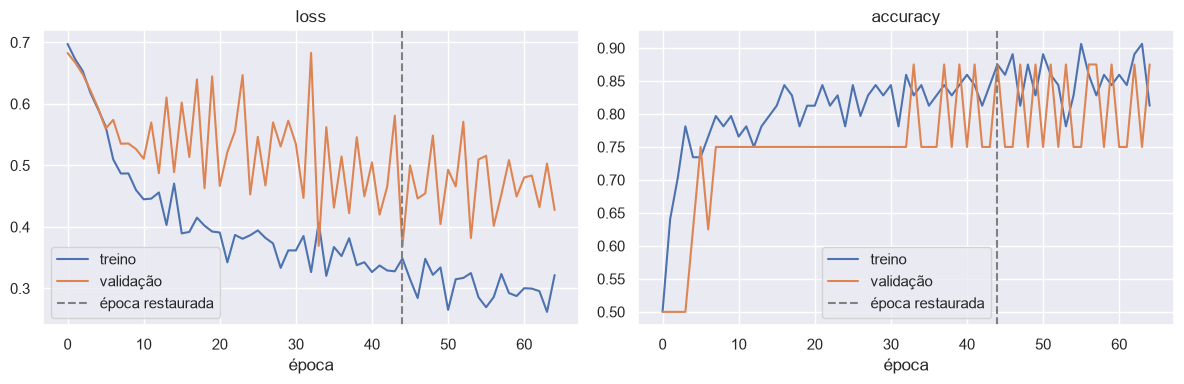

In [47]:
HISTORY_PANEL = (12, 4)


def plot_cnn_history(run: dict[str, object]) -> plt.Figure:
    fig, axes = plt.subplots(1, 2, figsize=HISTORY_PANEL)
    for ax, metric in zip(axes, ("loss", "accuracy")):
        ax.plot(run["history"][metric], label="treino")
        ax.plot(run["history"][f"val_{metric}"], label="validação")
        ax.axvline(run["best_epoch"] - 1, color="gray", linestyle="--", label="época restaurada")
        ax.set_title(metric)
        ax.set_xlabel("época")
        ax.legend()
    fig.tight_layout()
    return fig


render(plot_cnn_history(main_run))

### 11.5 Avaliação da CNN (semente principal)
Mesma tabela de classificação por imagem usada para os YOLO. O modelo é salvo em disco no formato `.keras`; o benchmark de tempo (12.5) o recarrega de lá, como faria um sistema em produção.

In [48]:
CNN_MAIN_NAME = f"CNN do zero (semente {SEED})"
CNN_MODEL_FILE = E2_DIR / f"cnn_seed{SEED}.keras"


def cnn_probabilities(model: tf.keras.Model, x: np.ndarray) -> np.ndarray:
    return model(x, training=False).numpy()[:, 0]


def to_labels(probabilities: np.ndarray) -> list[str]:
    return [CLASS_NAMES[int(p >= DECISION_THRESHOLD)] for p in probabilities]


def cnn_predict_label(model: tf.keras.Model, path: Path) -> str:
    return to_labels(cnn_probabilities(model, load_image_array(path)[None]))[0]


def cnn_predictions(model: tf.keras.Model) -> dict[str, list[str]]:
    return {set_name: to_labels(cnn_probabilities(model, x)) for set_name, x in X_SETS.items()}


def cnn_decisions(model: tf.keras.Model) -> dict[str, tuple[str, float]]:
    probabilities = cnn_probabilities(model, X_SETS[VAL_TEST_SET])
    return {path.name: (label, float(max(p, 1 - p))) for path, p, label in zip(VAL_TEST_PATHS, probabilities, to_labels(probabilities))}


cnn_main_predictions = cnn_predictions(cnn)
cnn_main_decisions = cnn_decisions(cnn)
cnn.save(CNN_MODEL_FILE)
print(f"Modelo salvo em {CNN_MODEL_FILE}")
classification_table(classification_rows(CNN_MAIN_NAME, cnn_main_predictions))

Modelo salvo em C:\Users\leelt\fiap-fase6\yolov5\runs\e2\cnn_seed42.keras


,,acertos,n,acurácia,IC95% Wilson,F1 macro,...,P trator,R vaca,R trator,F1 vaca,F1 trator
conjunto,abordagem,,,,,,,,,,,
teste,CNN do zero (semente 42),7,8,0.875,"[0,53; 0,98]",0.873,...,0.8,0.75,1.0,0.857,0.889
val+teste,CNN do zero (semente 42),14,16,0.875,"[0,64; 0,97]",0.873,...,0.8,0.75,1.0,0.857,0.889


### 11.6 Robustez da CNN: várias sementes
Com uma validação tão pequena, a época escolhida pelo *early stopping* depende muito do acaso. Retreinamos a **mesma arquitetura, com os mesmos splits**, usando as sementes de `CNN_SEEDS`, e resumimos com média, desvio-padrão (dp), mínimo e máximo. A média entre sementes é a estimativa mais honesta do desempenho **esperado** da receita de treino; a semente principal é um sorteio dessa distribuição.

In [49]:
def val_accuracy(model: tf.keras.Model) -> float:
    truth = [class_from_name(path) for path in SPLIT_PATHS["val"]]
    return float(np.mean([pred == true for pred, true in zip(to_labels(cnn_probabilities(model, x_val)), truth)]))


def seed_summary(seed: int, run: dict[str, object], predictions: dict[str, list[str]]) -> dict[str, object]:
    return {"semente": seed, "épocas": run["epochs"], "melhor época": run["best_epoch"], "treino (s)": run["seconds"],
            "acurácia val": val_accuracy(run["model"]),
            **{f"acurácia {set_name}": image_metrics(Y_TRUE[set_name], predictions[set_name])["acurácia"] for set_name in X_SETS}}


cnn_runs = {SEED: main_run, **{seed: train_cnn(seed) for seed in CNN_SEEDS if seed != SEED}}
CNN_SEED_PREDICTIONS = {seed: cnn_predictions(run["model"]) for seed, run in cnn_runs.items()}
CNN_SEED_TABLE = pd.DataFrame([seed_summary(seed, run, CNN_SEED_PREDICTIONS[seed]) for seed, run in cnn_runs.items()]).set_index("semente")
SEED_METRICS = ["acurácia val", *(f"acurácia {set_name}" for set_name in X_SETS), "treino (s)"]
CNN_SEED_STATS = CNN_SEED_TABLE[SEED_METRICS].agg(["mean", "std", "min", "max"]).rename(
    index={"mean": "média", "std": "dp", "min": "mín", "max": "máx"})
display(CNN_SEED_TABLE.round(3))
CNN_SEED_STATS.round(3)

,épocas,melhor época,treino (s),acurácia val,acurácia teste,acurácia val+teste
semente,,,,,,
42,65,45,20.046,0.875,0.875,0.875
7,122,102,35.943,1.000,1.000,1.000
123,150,149,43.558,0.875,1.000,0.938
2024,107,87,31.577,0.875,1.000,0.938
31337,139,119,41.010,1.000,1.000,1.000


,acurácia val,acurácia teste,acurácia val+teste,treino (s)
média,0.925,0.975,0.950,34.427
dp,0.068,0.056,0.052,9.273
mín,0.875,0.875,0.875,20.046
máx,1.000,1.000,1.000,43.558


### 11.7 Curvas de validação de todas as sementes
Perda e acurácia de validação de cada semente, com um ponto na época restaurada. Curvas muito diferentes entre sementes, e épocas restauradas espalhadas, mostram que o treino é instável com tão poucos dados: o resultado depende do sorteio da inicialização e do *augmentation*.

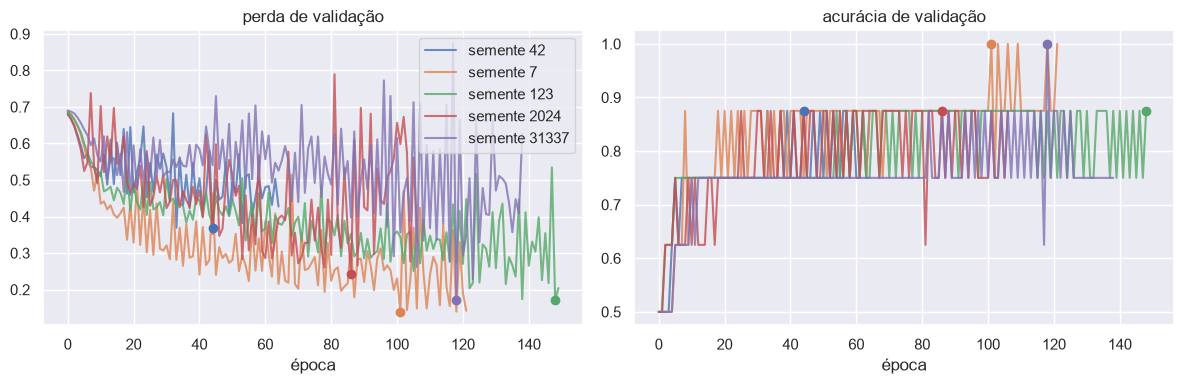

In [50]:
def plot_seed_curves(runs: dict[int, dict[str, object]]) -> plt.Figure:
    fig, axes = plt.subplots(1, 2, figsize=HISTORY_PANEL)
    for seed, run in runs.items():
        best = run["best_epoch"] - 1
        for ax, metric in zip(axes, ("val_loss", "val_accuracy")):
            (line,) = ax.plot(run["history"][metric], label=f"semente {seed}", alpha=0.8)
            ax.scatter([best], [run["history"][metric][best]], color=line.get_color(), zorder=3)
    for ax, title in zip(axes, ("perda de validação", "acurácia de validação")):
        ax.set_title(title)
        ax.set_xlabel("época")
    axes[0].legend()
    fig.tight_layout()
    return fig


render(plot_seed_curves(cnn_runs))

### 11.8 Onde a CNN olha: Grad-CAM
Uma CNN que acerta pode estar acertando pelo motivo errado, por exemplo pelo fundo (pasto verde × lavoura ou estrada) em vez do objeto. O **Grad-CAM** pondera os mapas de ativação da última convolução pelo gradiente da classe prevista e mostra as regiões que mais pesaram na decisão. Mapa quente sobre o animal ou a máquina indica que a rede usa o objeto; mapa quente no fundo indica um **atalho**, que tende a falhar fora deste dataset.

O título mostra a probabilidade de `trator` dada pela CNN e fica vermelho, com a marca `ERRO`, quando a predição está errada.

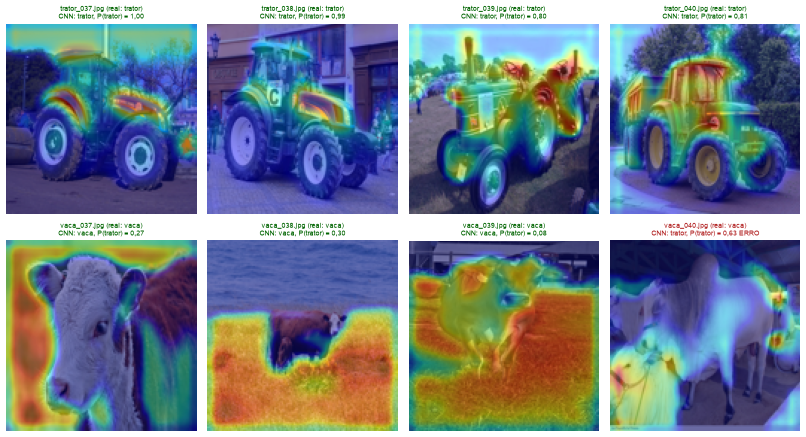

In [51]:
GRADCAM_ALPHA = 0.45
GRADCAM_CMAP = "jet"
GALLERY_COLUMNS = 4
GALLERY_CELL = (3.4, 3.8)
GALLERY_FONT_SIZE = 8
GALLERY_DPI = 60
OK_COLOR, ERROR_COLOR = "darkgreen", "firebrick"
ERROR_MARK = " ERRO"


def last_conv_name(model: tf.keras.Model) -> str:
    return [layer.name for layer in model.layers if isinstance(layer, tf.keras.layers.Conv2D)][-1]


def grad_cam(model: tf.keras.Model, image: np.ndarray) -> tuple[np.ndarray, float]:
    target = last_conv_name(model)
    with tf.GradientTape() as tape:
        x = tf.convert_to_tensor(image[None])
        for layer in model.layers:
            x = layer(x, training=False)
            if layer.name == target:
                features = x
                tape.watch(features)
        probability = x[0, 0]
        score = probability if float(probability) >= DECISION_THRESHOLD else 1 - probability
    weights = tf.reduce_mean(tape.gradient(score, features), axis=(1, 2))
    cam = tf.nn.relu(tf.reduce_sum(features * weights[:, None, None, :], axis=-1))[0]
    cam = cam / (tf.reduce_max(cam) + 1e-9)
    return tf.image.resize(cam[..., None], image.shape[:2]).numpy()[..., 0], float(probability)


def gallery_axes(count: int) -> tuple[plt.Figure, np.ndarray]:
    rows = -(-count // GALLERY_COLUMNS)
    fig, axes = plt.subplots(rows, GALLERY_COLUMNS, figsize=(GALLERY_CELL[0] * GALLERY_COLUMNS, GALLERY_CELL[1] * rows),
                             dpi=GALLERY_DPI, squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    return fig, axes.ravel()


def plot_grad_cam(model: tf.keras.Model, paths: list[Path], images: np.ndarray) -> plt.Figure:
    fig, axes = gallery_axes(len(paths))
    for ax, path, image in zip(axes, paths, images):
        heatmap, probability = grad_cam(model, image)
        predicted, truth = to_labels([probability])[0], class_from_name(path)
        ax.imshow(image.astype(np.uint8))
        ax.imshow(heatmap, cmap=GRADCAM_CMAP, alpha=GRADCAM_ALPHA)
        ax.set_title(f"{path.name} (real: {truth})\nCNN: {predicted}, P({TRACTOR_CLASS}) = {fmt_num(probability, CONF_DIGITS)}"
                     + ("" if predicted == truth else ERROR_MARK),
                     fontsize=GALLERY_FONT_SIZE, color=OK_COLOR if predicted == truth else ERROR_COLOR)
    fig.tight_layout()
    return fig


render(plot_grad_cam(cnn, TEST_PATHS, x_test))

## 12. Comparação lado a lado e análise crítica
### 12.1 Classificação por imagem: tabela unificada
As **mesmas imagens e as mesmas métricas** para todas as abordagens, em teste e val+teste. Além das três abordagens, a tabela traz duas linhas de referência:
- **CNN, média das sementes**: a coluna de intervalo mostra a faixa (mín–máx) entre sementes, não um intervalo de Wilson;
- **referência constante**: um "modelo" que sempre responde a mesma classe. É o piso do problema e mostra até onde vai o intervalo de confiança de uma acurácia trivial.

In [52]:
BASELINE_NAME = f"referência: sempre {CLASS_NAMES[0]}"
CNN_MEAN_NAME = f"CNN do zero (média de {len(CNN_SEEDS)} sementes)"
YOLO_RESULTS = {**custom_results, COCO_NAME: coco_result}
CLASSIFIERS = {**{name: result["predictions"] for name, result in YOLO_RESULTS.items()},
               CNN_MAIN_NAME: cnn_main_predictions,
               BASELINE_NAME: {set_name: [CLASS_NAMES[0]] * len(y_true) for set_name, y_true in Y_TRUE.items()}}


def seed_mean_rows() -> list[dict[str, object]]:
    rows = []
    for set_name, y_true in Y_TRUE.items():
        per_seed = pd.DataFrame([image_metrics(y_true, predictions[set_name]) for predictions in CNN_SEED_PREDICTIONS.values()])
        accuracy = per_seed["acurácia"]
        rows.append({"conjunto": set_name, "abordagem": CNN_MEAN_NAME, **per_seed.mean(numeric_only=True).to_dict(),
                     CI_COLUMN: f"faixa {fmt_num(accuracy.min(), 2)}–{fmt_num(accuracy.max(), 2)}"})
    return rows


IMAGE_TABLE = classification_table([row for name, predictions in CLASSIFIERS.items()
                                    for row in classification_rows(name, predictions)] + seed_mean_rows()).sort_index(level=0, sort_remaining=False)
IMAGE_TABLE

acertos     n  acurácia  \
conjunto  abordagem                                                    
teste     YOLO customizado (e30)                 8.0   8.0     1.000   
          YOLO customizado (e60)                 8.0   8.0     1.000   
          YOLO tradicional (COCO)                8.0   8.0     1.000   
          CNN do zero (semente 42)               7.0   8.0     0.875   
          referência: sempre vaca                4.0   8.0     0.500   
          CNN do zero (média de 5 sementes)      7.8   8.0     0.975   
val+teste YOLO customizado (e30)                16.0  16.0     1.000   
          YOLO customizado (e60)                16.0  16.0     1.000   
          YOLO tradicional (COCO)               15.0  16.0     0.938   
          CNN do zero (semente 42)              14.0  16.0     0.875   
          referência: sempre vaca                8.0  16.0     0.500   
          CNN do zero (média de 5 sementes)     15.2  16.0     0.950   

                                                IC95% Wilson  F1 macro  ...  \
conjunto  abordagem                                                     ...   
teste     YOLO customizado (e30)                [0,68; 1,00]     1.000  ...   
          YOLO customizado (e60)                [0,68; 1,00]     1.000  ...   
          YOLO tradicional (COCO)               [0,68; 1,00]     1.000  ...   
          CNN do zero (semente 42)              [0,53; 0,98]     0.873  ...   
          referência: sempre vaca               [0,22; 0,78]     0.333  ...   
          CNN do zero (média de 5 sementes)  faixa 0,88–1,00     0.975  ...   
val+teste YOLO customizado (e30)                [0,81; 1,00]     1.000  ...   
          YOLO customizado (e60)                [0,81; 1,00]     1.000  ...   
          YOLO tradicional (COCO)               [0,72; 0,99]     0.967  ...   
          CNN do zero (semente 42)              [0,64; 0,97]     0.873  ...   
          referência: sempre vaca               [0,28; 0,72]     0.333  ...   
          CNN do zero (média de 5 sementes)  faixa 0,88–1,00     0.950  ...   

                                             P trator  R vaca  R trator  \
conjunto  abordagem                                                       
teste     YOLO customizado (e30)                1.000    1.00     1.000   
          YOLO customizado (e60)                1.000    1.00     1.000   
          YOLO tradicional (COCO)               1.000    1.00     1.000   
          CNN do zero (semente 42)              0.800    0.75     1.000   
          referência: sempre vaca               0.000    1.00     0.000   
          CNN do zero (média de 5 sementes)     0.960    0.95     1.000   
val+teste YOLO customizado (e30)                1.000    1.00     1.000   
          YOLO customizado (e60)                1.000    1.00     1.000   
          YOLO tradicional (COCO)               1.000    1.00     0.875   
          CNN do zero (semente 42)              0.800    0.75     1.000   
          referência: sempre vaca               0.000    1.00     0.000   
          CNN do zero (média de 5 sementes)     0.916    0.90     1.000   

                                             F1 vaca  F1 trator  
conjunto  abordagem                                              
teste     YOLO customizado (e30)               1.000      1.000  
          YOLO customizado (e60)               1.000      1.000  
          YOLO tradicional (COCO)              1.000      1.000  
          CNN do zero (semente 42)             0.857      0.889  
          referência: sempre vaca              0.667      0.000  
          CNN do zero (média de 5 sementes)    0.971      0.978  
val+teste YOLO customizado (e30)               1.000      1.000  
          YOLO customizado (e60)               1.000      1.000  
          YOLO tradicional (COCO)              1.000      0.933  
          CNN do zero (semente 42)             0.857      0.889  
          referência: sempre vaca              0.667      0.000  
          CNN do zer

### 12.2 Detecção: YOLO customizado × YOLO tradicional
Só os YOLO localizam objetos, então esta é a única comparação em que eles podem se diferenciar. Compare o mAP50 daqui com o da Entrega 1 com cautela (ver a nota da seção 8.4). A primeira tabela traz VP, FP, FN, precisão, revocação e F1 no limiar de uso e o AP50 por classe; a linha `todas` soma as contagens e traz o mAP50. A segunda tabela traz os intervalos de confiança por *bootstrap* (reamostrando imagens) da precisão e da revocação totais. A terceira detalha imagem por imagem.

No YOLO tradicional, a classe `trator` só existe por causa do mapeamento `truck/car/bus → trator`: o AP dessa classe mede quanto o atalho funciona neste dataset, não um conhecimento do modelo sobre tratores.

In [53]:
DETECTION_TABLE = pd.concat({name: result["report"] for name, result in YOLO_RESULTS.items()}, names=["modelo", "classe"])


def detection_interval_row(name: str, result: dict[str, object]) -> dict[str, str]:
    per_image = result["per_image"]
    return {"modelo": name,
            f"precisão {BOOT_LABEL}": format_interval(*bootstrap_interval(per_image, precision_of)),
            f"revocação {BOOT_LABEL}": format_interval(*bootstrap_interval(per_image, recall_of))}


def per_image_cell(counts: np.ndarray) -> str:
    tp, fp, fn = counts
    return f"VP={tp} FP={fp} FN={fn}"


DETECTION_CI = pd.DataFrame([detection_interval_row(name, result) for name, result in YOLO_RESULTS.items()]).set_index("modelo")
PER_IMAGE_DETECTION = pd.DataFrame({name: [per_image_cell(counts) for counts in result["per_image"]] for name, result in YOLO_RESULTS.items()},
                                   index=[path.name for path in TEST_PATHS])
PER_IMAGE_DETECTION.insert(0, "caixas reais", [len(GT_TEST[path.name]) for path in TEST_PATHS])
display(DETECTION_TABLE.round(3))
display(DETECTION_CI)
PER_IMAGE_DETECTION

VP  FP  FN  precisão  revocação     F1   AP50
modelo                  classe                                               
YOLO customizado (e30)  vaca     7   0   4     1.000      0.636  0.778  0.819
                        trator   4   0   1     1.000      0.800  0.889  0.800
                        todas   11   0   5     1.000      0.688  0.815  0.810
YOLO customizado (e60)  vaca     7   1   4     0.875      0.636  0.737  0.669
                        trator   4   0   1     1.000      0.800  0.889  0.800
                        todas   11   1   5     0.917      0.688  0.786  0.734
YOLO tradicional (COCO) vaca     7   0   4     1.000      0.636  0.778  0.929
                        trator   4   1   1     0.800      0.800  0.800  0.885
                        todas   11   1   5     0.917      0.688  0.786  0.907

,precisão IC95% bootstrap,revocação IC95% bootstrap
modelo,,
YOLO customizado (e30),"[1,00; 1,00]","[0,57; 0,86]"
YOLO customizado (e60),"[0,82; 1,00]","[0,57; 0,86]"
YOLO tradicional (COCO),"[0,75; 1,00]","[0,57; 0,86]"


,caixas reais,YOLO customizado (e30),YOLO customizado (e60),YOLO tradicional (COCO)
trator_037.jpg,1,VP=1 FP=0 FN=0,VP=1 FP=0 FN=0,VP=1 FP=0 FN=0
trator_038.jpg,1,VP=1 FP=0 FN=0,VP=1 FP=0 FN=0,VP=1 FP=0 FN=0
trator_039.jpg,2,VP=1 FP=0 FN=1,VP=1 FP=0 FN=1,VP=1 FP=1 FN=1
trator_040.jpg,1,VP=1 FP=0 FN=0,VP=1 FP=0 FN=0,VP=1 FP=0 FN=0
vaca_037.jpg,2,VP=1 FP=0 FN=1,VP=1 FP=0 FN=1,VP=1 FP=0 FN=1
vaca_038.jpg,2,VP=1 FP=0 FN=1,VP=1 FP=0 FN=1,VP=1 FP=0 FN=1
vaca_039.jpg,2,VP=2 FP=0 FN=0,VP=2 FP=0 FN=0,VP=2 FP=0 FN=0
vaca_040.jpg,5,VP=3 FP=0 FN=2,VP=3 FP=1 FN=2,VP=3 FP=0 FN=2


### 12.3 Análise de erros de detecção: quais caixas os YOLO perdem
Para cada caixa real do teste, registramos o tamanho relativo (área da caixa / área da imagem), o número de objetos na mesma imagem e se cada modelo a encontrou. A hipótese a testar: as perdas se concentram em **objetos pequenos e em cenas com vários objetos** (rebanhos), onde caixas pequenas ou sobrepostas ficam abaixo do limiar ou são suprimidas pelo NMS. O gráfico mostra cada caixa real, com escala logarítmica de área.

,caixas perdidas,área mediana das encontradas (%),área mediana das perdidas (%),perdidas em imagens com 2+ objetos
YOLO customizado (e30),5.0,58.47,3.64,1.0
YOLO customizado (e60),5.0,58.47,3.31,1.0
YOLO tradicional (COCO),5.0,58.47,3.31,1.0


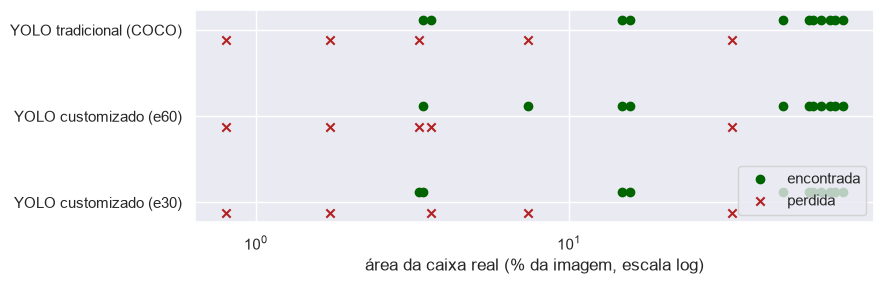

In [54]:
CROWDED_MIN_OBJECTS = 2
BOX_PLOT_SIZE = (9, 3)
FOUND_OFFSET = 0.12


def gt_box_records(name: str, result: dict[str, object]) -> list[dict[str, object]]:
    records = []
    for path in TEST_PATHS:
        width, height = Image.open(path).size
        gt_boxes = GT_TEST[path.name]
        _, taken = match_detections(confident(result["detections"][path.name]), gt_boxes)
        records += [{"modelo": name, "imagem": path.name, "classe": label, "área relativa": box_area(box) / (width * height),
                     "objetos na imagem": len(gt_boxes), "encontrada": found} for (label, box), found in zip(gt_boxes, taken)]
    return records


def miss_summary(records: pd.DataFrame) -> pd.Series:
    missed, found = records[~records["encontrada"]], records[records["encontrada"]]
    return pd.Series({"caixas perdidas": len(missed),
                      "área mediana das encontradas (%)": PERCENT * found["área relativa"].median(),
                      "área mediana das perdidas (%)": PERCENT * missed["área relativa"].median(),
                      f"perdidas em imagens com {CROWDED_MIN_OBJECTS}+ objetos": (missed["objetos na imagem"] >= CROWDED_MIN_OBJECTS).mean()})


def plot_box_recall(records: pd.DataFrame) -> plt.Figure:
    fig, ax = plt.subplots(figsize=BOX_PLOT_SIZE)
    for row, name in enumerate(YOLO_RESULTS):
        subset = records[records["modelo"] == name]
        for found, offset, color, label in ((True, FOUND_OFFSET, OK_COLOR, "encontrada"), (False, -FOUND_OFFSET, ERROR_COLOR, "perdida")):
            points = subset[subset["encontrada"] == found]
            ax.scatter(PERCENT * points["área relativa"], np.full(len(points), row + offset), color=color,
                       marker="o" if found else "x", label=label if row == 0 else None)
    ax.set_xscale("log")
    ax.set_yticks(range(len(YOLO_RESULTS)), list(YOLO_RESULTS))
    ax.set_xlabel("área da caixa real (% da imagem, escala log)")
    ax.legend(loc="lower right")
    fig.tight_layout()
    return fig


BOX_RECORDS = pd.DataFrame([record for name, result in YOLO_RESULTS.items() for record in gt_box_records(name, result)])
MISS_SUMMARY = pd.DataFrame({name: miss_summary(group) for name, group in BOX_RECORDS.groupby("modelo", sort=False)}).T
display(MISS_SUMMARY.round(2))
render(plot_box_recall(BOX_RECORDS))

### 12.4 As diferenças são estatisticamente significativas?
Teste de McNemar exato para cada par de abordagens, nas mesmas imagens. `só A acerta` e `só B acerta` são as imagens discordantes, as únicas que informam qual é melhor. Um p-valor abaixo de `SIGNIFICANCE_LEVEL` indicaria diferença real; acima dele, a diferença observada é compatível com o acaso. Não aplicamos correção para múltiplas comparações: com ela, seria ainda mais difícil declarar diferença.

A linha gerada abaixo da tabela mostra a **resolução** do teste: quantas imagens discordantes seriam necessárias para alguma diferença ser detectável.

In [55]:
P_COLUMN = "p (McNemar exato)"


def mcnemar_rows(set_name: str) -> list[dict[str, object]]:
    rows = []
    for (name_a, preds_a), (name_b, preds_b) in combinations(CLASSIFIERS.items(), 2):
        only_a, only_b, p_value = mcnemar_exact(Y_TRUE[set_name], preds_a[set_name], preds_b[set_name])
        rows.append({"conjunto": set_name, "A": name_a, "B": name_b, "só A acerta": only_a, "só B acerta": only_b,
                     P_COLUMN: p_value, "significativo": p_value < SIGNIFICANCE_LEVEL})
    return rows


def min_discordant(total: int) -> int | None:
    return next((k for k in range(1, total + 1) if binomtest(k, k).pvalue < SIGNIFICANCE_LEVEL), None)


def resolution_line(set_name: str) -> str:
    total = len(Y_TRUE[set_name])
    low, _ = wilson_interval(total, total)
    needed = min_discordant(total)
    needed_text = (f"uma abordagem precisaria acertar ao menos **{needed}** imagens que a outra erra, sem errar nenhuma que a outra acerta"
                   if needed else "nenhum resultado possível atingiria significância")
    return (f"{set_name} (n={total}): cada imagem vale {fmt_num(PERCENT / total, 1)} pontos percentuais; mesmo um acerto total "
            f"({total}/{total}) tem {CI_COLUMN} de {fmt_num(low, 2)} a 1; para p < {fmt_num(SIGNIFICANCE_LEVEL, 2)}, {needed_text}")


MCNEMAR_TABLE = pd.DataFrame([row for set_name in Y_TRUE for row in mcnemar_rows(set_name)]).set_index(["conjunto", "A", "B"])
display(MCNEMAR_TABLE.round(3))
show_markdown([resolution_line(set_name) for set_name in Y_TRUE], "Resolução estatística")

só A acerta  \
conjunto  A                        B                                       
teste     YOLO customizado (e30)   YOLO customizado (e60)              0   
                                   YOLO tradicional (COCO)             0   
                                   CNN do zero (semente 42)            1   
                                   referência: sempre vaca             4   
          YOLO customizado (e60)   YOLO tradicional (COCO)             0   
                                   CNN do zero (semente 42)            1   
                                   referência: sempre vaca             4   
          YOLO tradicional (COCO)  CNN do zero (semente 42)            1   
                                   referência: sempre vaca             4   
          CNN do zero (semente 42) referência: sempre vaca             4   
val+teste YOLO customizado (e30)   YOLO customizado (e60)              0   
                                   YOLO tradicional (COCO)             1   
                                   CNN do zero (semente 42)            2   
                                   referência: sempre vaca             8   
          YOLO customizado (e60)   YOLO tradicional (COCO)             1   
                                   CNN do zero (semente 42)            2   
                                   referência: sempre vaca             8   
          YOLO tradicional (COCO)  CNN do zero (semente 42)            2   
                                   referência: sempre vaca             7   
          CNN do zero (semente 42) referência: sempre vaca             8   

                                                             só B acerta  \
conjunto  A                        B                                       
teste     YOLO customizado (e30)   YOLO customizado (e60)              0   
                                   YOLO tradicional (COCO)             0   
                                   CNN do zero (semente 42)            0   
                                   referência: sempre vaca             0   
          YOLO customizado (e60)   YOLO tradicional (COCO)             0   
                                   CNN do zero (semente 42)            0   
                                   referência: sempre vaca             0   
          YOLO tradicional (COCO)  CNN do zero (semente 42)            0   
                                   referência: sempre vaca             0   
          CNN do zero (semente 42) referência: sempre vaca             1   
val+teste YOLO customizado (e30)   YOLO customizado (e60)              0   
                                   YOLO tradicional (COCO)             0   
                                   CNN do zero (semente 42)            0   
                                   referência: sempre vaca             0   
          YOLO customizado (e60)   YOLO tradicional (COCO)             0   
                                   CNN do zero (semente 42)            0   
                                   referência: sempre vaca             0   
          YOLO tradicional (COCO)  CNN do zero (semente 42)            1   
                                   referência: sempre vaca             0   
          CNN do zero (semente 42) referência: sempre vaca             2   

                                                             p (McNemar exato)  \
conjunto  A                        B                                             
teste     YOLO customizado (e30)   YOLO customizado (e60)                1.000   
                                   YOLO tradicional (COCO)               1.000   
                                   CNN do zero (semente 42)              1.000   
                                   referência: sempre vaca               0.125   
          YOLO customizado (e60)   YOLO tradicional (COCO)               1.000   
                                   CNN do zero (semente 42)              1.000   
                                   referência: sempre vaca 

#### Resolução estatística
- teste (n=8): cada imagem vale 12,5 pontos percentuais; mesmo um acerto total (8/8) tem IC95% Wilson de 0,68 a 1; para p < 0,05, uma abordagem precisaria acertar ao menos **6** imagens que a outra erra, sem errar nenhuma que a outra acerta
- val+teste (n=16): cada imagem vale 6,2 pontos percentuais; mesmo um acerto total (16/16) tem IC95% Wilson de 0,81 a 1; para p < 0,05, uma abordagem precisaria acertar ao menos **6** imagens que a outra erra, sem errar nenhuma que a outra acerta

### 12.5 Benchmark de tempo de inferência
Aplicamos o protocolo da seção 8.5 a cada modelo **em cada dispositivo disponível**. Os YOLO sempre rodam também na CPU, para que exista uma comparação no **mesmo hardware** da CNN quando o TensorFlow não tem GPU (caso do Windows nativo, sem suporte a GPU desde o TensorFlow 2.11). Todos os YOLO usam a mesma arquitetura (YOLOv5s), então diferenças de latência entre eles são ruído de medição.

A carga do modelo é medida com o arquivo já no cache do sistema operacional (os modelos foram carregados nas seções anteriores). A primeira carga de um processo novo é mais lenta, sobretudo no `torch.hub`, que também importa o código do YOLOv5.

carga do modelo (s)  mediana (ms/img)  \
abordagem                dispositivo                                          
YOLO customizado (e30)   CPU                         0.33             56.71   
                         GPU                         0.45             25.24   
YOLO customizado (e60)   CPU                         0.33             57.33   
                         GPU                         0.36             25.23   
YOLO tradicional (COCO)  CPU                         0.33             58.25   
                         GPU                         0.41             25.82   
CNN do zero (semente 42) CPU                         0.14             28.65   

                                      p90 (ms/img)  imagens/s (mediana)  \
abordagem                dispositivo                                      
YOLO customizado (e30)   CPU                 65.63                17.63   
                         GPU                 32.39                39.62   
YOLO customizado (e60)   CPU                 65.02                17.44   
                         GPU                 30.35                39.64   
YOLO tradicional (COCO)  CPU                 65.45                17.17   
                         GPU                 29.49                38.73   
CNN do zero (semente 42) CPU                 32.55                34.91   

                                      medições  
abordagem                dispositivo            
YOLO customizado (e30)   CPU                80  
                         GPU                80  
YOLO customizado (e60)   CPU                80  
                         GPU                80  
YOLO tradicional (COCO)  CPU                80  
                         GPU                80  
CNN do zero (semente 42) CPU                80

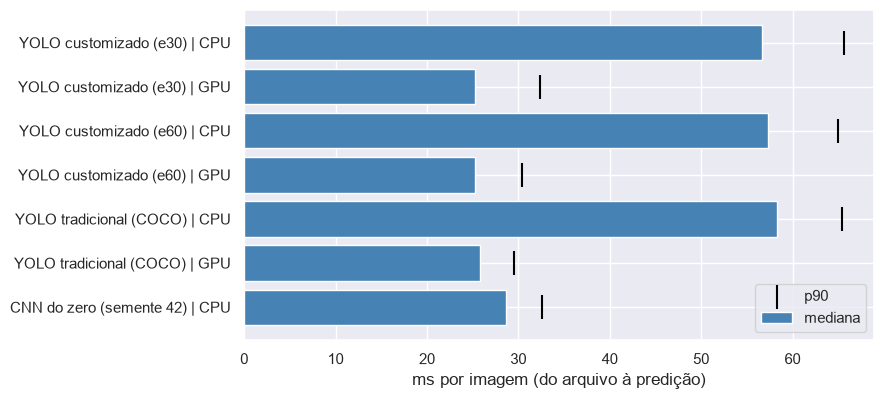

In [56]:
LATENCY_ROW_HEIGHT = 0.45
LATENCY_WIDTH = 9
TIMING_DEVICES_TORCH = ["cpu", *(["cuda"] if torch.cuda.is_available() else [])]
TIMING_DEVICES_TF = ["CPU", *(["GPU"] if TF_DEVICE == "GPU" else [])]
YOLO_WEIGHTS = {**{name: best_weights(run) for name, run in CUSTOM_RUNS.items()}, COCO_NAME: COCO_WEIGHTS}


def benchmark_yolo(name: str, weights: Path, device: str) -> TimingResult:
    model, load_s = timed(lambda: load_yolo(weights, device, CONF_THRES), device)
    samples = latency_samples_ms(lambda path: raw_detections(model, path), TEST_PATHS, device)
    del model
    free_gpu()
    return TimingResult(name, device_label(device), load_s, samples)


def benchmark_cnn(device: str) -> TimingResult:
    with tf.device(f"/{device}:0"):
        model, load_s = timed(lambda: tf.keras.models.load_model(CNN_MODEL_FILE), device)
        samples = latency_samples_ms(lambda path: cnn_predict_label(model, path), TEST_PATHS, device)
    return TimingResult(CNN_MAIN_NAME, device, load_s, samples)


def plot_latency(results: list[TimingResult]) -> plt.Figure:
    fig, ax = plt.subplots(figsize=(LATENCY_WIDTH, LATENCY_ROW_HEIGHT * len(results) + 1))
    positions = np.arange(len(results))
    medians = [np.median(r.samples) for r in results]
    tails = [np.percentile(r.samples, TIMING_PERCENTILE) for r in results]
    ax.barh(positions, medians, color="steelblue", label="mediana")
    ax.scatter(tails, positions, marker="|", s=300, color="black", label=f"p{TIMING_PERCENTILE}")
    ax.set_yticks(positions, [f"{r.approach} | {r.device}" for r in results])
    ax.invert_yaxis()
    ax.set_xlabel("ms por imagem (do arquivo à predição)")
    ax.legend(loc="best")
    fig.tight_layout()
    return fig


TIMING_RESULTS = [*(benchmark_yolo(name, weights, device) for name, weights in YOLO_WEIGHTS.items() for device in TIMING_DEVICES_TORCH),
                  *(benchmark_cnn(device) for device in TIMING_DEVICES_TF)]
TIMING_TABLE = pd.DataFrame([result.row() for result in TIMING_RESULTS]).set_index(["abordagem", "dispositivo"])
display(TIMING_TABLE.round(2))
render(plot_latency(TIMING_RESULTS))

### 12.6 Matrizes de confusão
Primeira linha: teste; segunda linha: val+teste. Nos YOLO aparece a coluna `nenhum` quando alguma imagem fica sem detecção válida.

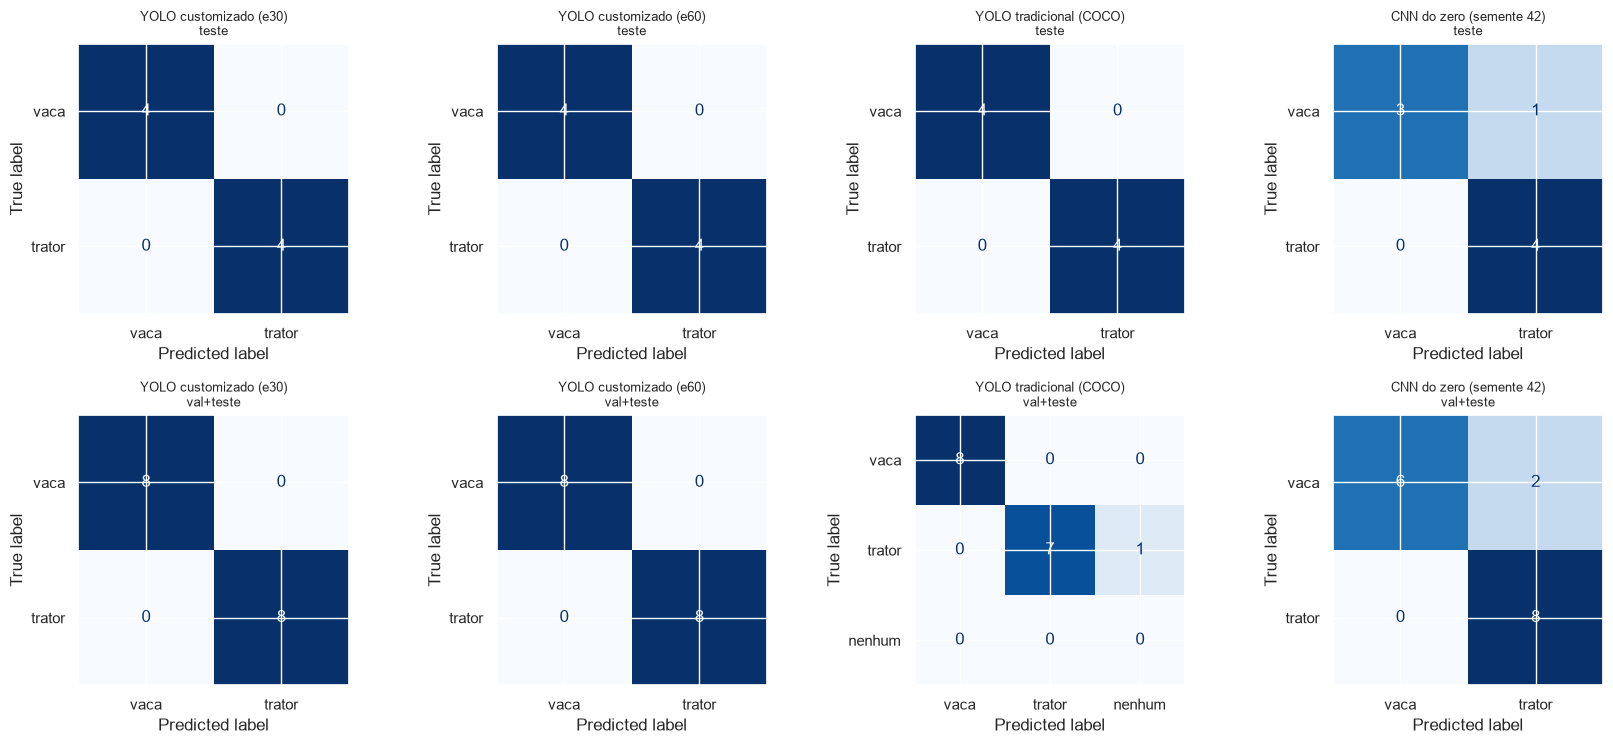

In [57]:
CONFUSION_PANEL = (4.2, 3.8)
CONFUSION_MODELS = {name: predictions for name, predictions in CLASSIFIERS.items() if name != BASELINE_NAME}


def show_confusion(y_true: list[str], y_pred: list[str], title: str, ax: plt.Axes) -> None:
    labels = CLASS_NAMES + ([NO_DETECTION] if NO_DETECTION in y_pred else [])
    matrix = confusion_matrix(y_true, y_pred, labels=labels)
    ConfusionMatrixDisplay(matrix, display_labels=labels).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(title, fontsize=GALLERY_FONT_SIZE + 1)


def plot_confusions(models: dict[str, dict[str, list[str]]]) -> plt.Figure:
    fig, axes = plt.subplots(len(Y_TRUE), len(models), squeeze=False,
                             figsize=(CONFUSION_PANEL[0] * len(models), CONFUSION_PANEL[1] * len(Y_TRUE)))
    for row, (set_name, y_true) in enumerate(Y_TRUE.items()):
        for ax, (name, predictions) in zip(axes[row], models.items()):
            show_confusion(y_true, predictions[set_name], f"{name}\n{set_name}", ax)
    fig.tight_layout()
    return fig


render(plot_confusions(CONFUSION_MODELS))

### 12.7 Análise de erros por imagem
Para cada imagem de val+teste, a decisão de cada abordagem e a confiança dessa decisão: confiança da detecção mais forte nos YOLO e probabilidade da classe escolhida na CNN. As duas escalas **não são diretamente comparáveis** (não estão calibradas da mesma forma), mas dentro de cada abordagem uma confiança baixa num acerto indica uma decisão frágil. Erros recebem a marca `ERRO`.

In [58]:
DECISIONS = {**{name: result["decisions"] for name, result in YOLO_RESULTS.items()}, CNN_MAIN_NAME: cnn_main_decisions}


def decision_cell(decision: tuple[str, float], truth: str) -> str:
    label, conf = decision
    return f"{label} ({fmt_num(conf, CONF_DIGITS)})" + ("" if label == truth else ERROR_MARK)


ERROR_IMAGES = [path for path in VAL_TEST_PATHS
                if any(decisions[path.name][0] != class_from_name(path) for decisions in DECISIONS.values())]
ERROR_TABLE = pd.DataFrame({"split": [path.parent.name for path in VAL_TEST_PATHS], "real": Y_TRUE[VAL_TEST_SET],
                            **{name: [decision_cell(decisions[path.name], class_from_name(path)) for path in VAL_TEST_PATHS]
                               for name, decisions in DECISIONS.items()}},
                           index=[path.name for path in VAL_TEST_PATHS])
ERROR_TABLE

,split,real,YOLO customizado (e30),YOLO customizado (e60),YOLO tradicional (COCO),CNN do zero (semente 42)
trator_033.jpg,val,trator,"trator (0,33)","trator (0,35)","nenhum (0,00) ERRO","trator (0,93)"
trator_034.jpg,val,trator,"trator (0,56)","trator (0,50)","trator (0,40)","trator (0,94)"
trator_035.jpg,val,trator,"trator (0,51)","trator (0,61)","trator (0,35)","trator (0,89)"
trator_036.jpg,val,trator,"trator (0,55)","trator (0,48)","trator (0,56)","trator (0,99)"
vaca_033.jpg,val,vaca,"vaca (0,66)","vaca (0,67)","vaca (0,83)","vaca (0,84)"
vaca_034.jpg,val,vaca,"vaca (0,73)","vaca (0,80)","vaca (0,86)","vaca (0,54)"
vaca_035.jpg,val,vaca,"vaca (0,82)","vaca (0,89)","vaca (0,92)","vaca (0,80)"
vaca_036.jpg,val,vaca,"vaca (0,65)","vaca (0,80)","vaca (0,81)","trator (0,81) ERRO"
trator_037.jpg,test,trator,"trator (0,55)","trator (0,44)","trator (0,69)","trator (1,00)"
trator_038.jpg,test,trator,"trator (0,60)","trator (0,65)","trator (0,76)","trator (0,99)"


O resumo abaixo é gerado da tabela anterior e das detecções brutas: os erros de cada abordagem, o acerto menos confiante (o mais próximo de virar erro), as classes COCO que responderam pelas imagens de cada classe e as classes COCO fora do problema que o mapeamento descartou.

In [59]:
def error_line(name: str, decisions: dict[str, tuple[str, float]]) -> str:
    errors = [f"`{path.name}` → {decisions[path.name][0]}" for path in VAL_TEST_PATHS if decisions[path.name][0] != class_from_name(path)]
    correct = {path.name: decisions[path.name][1] for path in VAL_TEST_PATHS if decisions[path.name][0] == class_from_name(path)}
    weakest = min(correct, key=correct.get) if correct else None
    weakest_text = f"; acerto menos confiante: `{weakest}` ({fmt_num(correct[weakest], CONF_DIGITS)})" if weakest else ""
    return f"**{name}**: {len(errors)} erro(s) em val+teste ({', '.join(errors) or 'nenhum'}){weakest_text}"


def coco_mapping_line(our_class: str) -> str:
    hits = [(label, conf) for path in VAL_TEST_PATHS if class_from_name(path) == our_class
            for label, conf, _ in confident(coco_result["raw"][path.name]) if COCO_TO_OURS.get(label) == our_class]
    labels = pd.Series([label for label, _ in hits], dtype=object).value_counts()
    listing = ", ".join(f"`{label}` ×{count}" for label, count in labels.items()) or "nenhuma detecção"
    return f"YOLO tradicional, imagens de `{our_class}` em val+teste: classes COCO mapeadas que responderam: {listing}"


def coco_unmapped_line() -> str:
    labels = pd.Series([label for dets in coco_result["raw"].values() for label, _, _ in confident(dets)
                        if label not in COCO_TO_OURS], dtype=object).value_counts()
    listing = ", ".join(f"`{label}` ×{count}" for label, count in labels.items()) or "nenhuma"
    return f"YOLO tradicional, classes COCO fora do problema detectadas em val+teste e descartadas pelo mapeamento: {listing}"


show_markdown([*(error_line(name, decisions) for name, decisions in DECISIONS.items()),
               *(coco_mapping_line(cls) for cls in CLASS_NAMES), coco_unmapped_line()], "Erros por abordagem")

#### Erros por abordagem
- **YOLO customizado (e30)**: 0 erro(s) em val+teste (nenhum); acerto menos confiante: `trator_033.jpg` (0,33)
- **YOLO customizado (e60)**: 0 erro(s) em val+teste (nenhum); acerto menos confiante: `trator_033.jpg` (0,35)
- **YOLO tradicional (COCO)**: 1 erro(s) em val+teste (`trator_033.jpg` → nenhum); acerto menos confiante: `trator_035.jpg` (0,35)
- **CNN do zero (semente 42)**: 2 erro(s) em val+teste (`vaca_036.jpg` → trator, `vaca_040.jpg` → trator); acerto menos confiante: `vaca_034.jpg` (0,54)
- YOLO tradicional, imagens de `vaca` em val+teste: classes COCO mapeadas que responderam: `cow` ×17
- YOLO tradicional, imagens de `trator` em val+teste: classes COCO mapeadas que responderam: `truck` ×8
- YOLO tradicional, classes COCO fora do problema detectadas em val+teste e descartadas pelo mapeamento: `person` ×14, `bird` ×1

Galeria das imagens de val+teste em que **pelo menos uma** abordagem erra, com a decisão de cada uma. Olhar as imagens é o que permite explicar o erro: enquadramento, objeto pequeno ou parcial, fundo atípico, objeto parecido com outra classe do COCO.

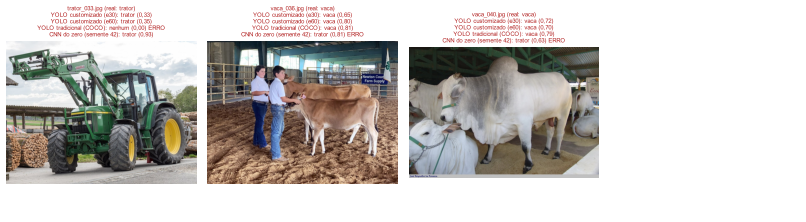

In [60]:
def plot_error_gallery(paths: list[Path]) -> plt.Figure:
    fig, axes = gallery_axes(len(paths))
    for ax, path in zip(axes, paths):
        truth = class_from_name(path)
        ax.imshow(Image.open(path))
        lines = [f"{name}: {decision_cell(decisions[path.name], truth)}" for name, decisions in DECISIONS.items()]
        ax.set_title("\n".join([f"{path.name} (real: {truth})", *lines]), fontsize=GALLERY_FONT_SIZE - 1, color=ERROR_COLOR)
    fig.tight_layout()
    return fig


if ERROR_IMAGES:
    render(plot_error_gallery(ERROR_IMAGES))
else:
    print("Nenhuma abordagem errou alguma imagem de val+teste.")

*Imagens: Wikimedia Commons, créditos em `dataset/CREDITS.md`.*

### 12.8 Facilidade de uso e integração, em números
"Facilidade" tem uma parte qualitativa, mas boa parte dela pode ser medida:
- **anotação manual** necessária para treinar (caixas de treino e validação no YOLO customizado; na CNN o rótulo sai do nome do arquivo; no COCO, nada);
- **tamanho do arquivo** do modelo, que pesa em *deploy* embarcado e na distribuição;
- **carga do modelo** na CPU (seção 12.5), o custo de partida de um serviço;
- **o que o modelo devolve** e de que pilha de software depende.

In [61]:
ANNOTATION_SPLITS = ("train", "val")
BOXES_TO_ANNOTATE = sum(len(read_gt_boxes(path)) for split in ANNOTATION_SPLITS for path in SPLIT_PATHS[split])
IMAGES_TO_LABEL = sum(len(SPLIT_PATHS[split]) for split in ANNOTATION_SPLITS)
FAMILY_TRAITS = {
    "custom": {"anotação manual": f"{BOXES_TO_ANNOTATE} caixas em {IMAGES_TO_LABEL} imagens",
               "saída": "caixas, classes do problema, confiança", "pilha": "PyTorch + repositório YOLOv5",
               "facilidade": "média: anotar caixas e treinar com GPU; depois, API idêntica à do COCO"},
    "coco": {"anotação manual": "nenhuma", "saída": "caixas, classes do COCO (exige mapeamento)",
             "pilha": "PyTorch + repositório YOLOv5", "facilidade": "alta: uma chamada ao torch.hub; preso ao vocabulário do COCO"},
    "cnn": {"anotação manual": f"nenhuma ({IMAGES_TO_LABEL} rótulos por imagem, vindos do nome do arquivo)",
            "saída": "uma classe e uma probabilidade por imagem", "pilha": "TensorFlow/Keras",
            "facilidade": "média: rótulo trivial, mas arquitetura, augmentation e early stopping são decisões manuais"},
}
APPROACH_FAMILY = {**{name: "custom" for name in CUSTOM_RUNS}, COCO_NAME: "coco", CNN_MAIN_NAME: "cnn"}
MODEL_FILES = {**YOLO_WEIGHTS, CNN_MAIN_NAME: CNN_MODEL_FILE}
MODEL_PARAMS = {**{name: result["params"] for name, result in YOLO_RESULTS.items()}, CNN_MAIN_NAME: CNN_PARAMS}


def integration_row(name: str) -> dict[str, object]:
    return {"abordagem": name, "parâmetros": MODEL_PARAMS[name], "arquivo (MB)": MODEL_FILES[name].stat().st_size / BYTES_PER_MB,
            "carga na CPU (s)": TIMING_TABLE.loc[(name, "CPU"), "carga do modelo (s)"], **FAMILY_TRAITS[APPROACH_FAMILY[name]]}


INTEGRATION_TABLE = pd.DataFrame(map(integration_row, APPROACH_FAMILY)).set_index("abordagem")
INTEGRATION_TABLE.round(2)

,parâmetros,arquivo (MB),carga na CPU (s),anotação manual,saída,pilha,facilidade
abordagem,,,,,,,
YOLO customizado (e30),7015519,13.73,0.33,152 caixas em 72 imagens,"caixas, classes do problema, confiança",PyTorch + repositório YOLOv5,média: anotar caixas e treinar com GPU; depois...
YOLO customizado (e60),7015519,13.73,0.33,152 caixas em 72 imagens,"caixas, classes do problema, confiança",PyTorch + repositório YOLOv5,média: anotar caixas e treinar com GPU; depois...
YOLO tradicional (COCO),7225885,14.12,0.33,nenhuma,"caixas, classes do COCO (exige mapeamento)",PyTorch + repositório YOLOv5,alta: uma chamada ao torch.hub; preso ao vocab...
CNN do zero (semente 42),93377,1.12,0.14,"nenhuma (72 rótulos por imagem, vindos do nome...",uma classe e uma probabilidade por imagem,TensorFlow/Keras,"média: rótulo trivial, mas arquitetura, augmen..."


### 12.9 Tabela comparativa final
Uma linha por abordagem, com os quatro critérios do enunciado:
- **precisão**: acurácia por imagem com intervalo, F1 macro e, nos YOLO, mAP50 e revocação de detecção;
- **treino/customização**: tempo de treino e dispositivo;
- **inferência**: mediana por imagem na CPU (comparação no mesmo hardware) e na GPU, quando houver;
- **facilidade**: anotação necessária e avaliação qualitativa (detalhes em 12.8).

In [62]:
def image_value(name: str, set_name: str, column: str) -> object:
    return IMAGE_TABLE.loc[(set_name, name), column]


def latency_value(name: str, device: str) -> object:
    key = (name, device)
    return round(TIMING_TABLE.loc[key, "mediana (ms/img)"], 1) if key in TIMING_TABLE.index else "—"


def detection_value(name: str, column: str) -> object:
    return round(DETECTION_TABLE.loc[(name, ALL_CLASSES), column], 3) if name in YOLO_RESULTS else "—"


def train_text(name: str) -> str:
    if name in CUSTOM_RUNS:
        return f"{format_minutes(custom_train_seconds(CUSTOM_RUNS[name]))} ({device_label(TORCH_DEVICE)})"
    if name == COCO_NAME:
        return "0 (pré-treinado)"
    return f"{format_minutes(CNN_SEED_STATS.loc['média', 'treino (s)'])} por semente ({TF_DEVICE})"


def final_row(name: str, timing_name: str, family: str) -> dict[str, object]:
    return {"abordagem": name,
            f"acurácia {TEST_SET}": image_value(name, TEST_SET, "acurácia"), f"{CI_COLUMN} {TEST_SET}": image_value(name, TEST_SET, CI_COLUMN),
            f"acurácia {VAL_TEST_SET}": image_value(name, VAL_TEST_SET, "acurácia"),
            f"F1 macro {TEST_SET}": image_value(name, TEST_SET, "F1 macro"),
            f"m{AP_COLUMN} detecção": detection_value(name, AP_COLUMN), "revocação detecção": detection_value(name, "revocação"),
            "treino/customização": train_text(name),
            "inferência CPU (ms/img)": latency_value(timing_name, "CPU"), "inferência GPU (ms/img)": latency_value(timing_name, "GPU"),
            "anotação manual": FAMILY_TRAITS[family]["anotação manual"], "facilidade": FAMILY_TRAITS[family]["facilidade"]}


E2_COMPARISON = pd.DataFrame([*(final_row(name, name, APPROACH_FAMILY[name]) for name in APPROACH_FAMILY),
                              final_row(CNN_MEAN_NAME, CNN_MAIN_NAME, "cnn")]).set_index("abordagem").round(3)
E2_COMPARISON

,acurácia teste,IC95% Wilson teste,acurácia val+teste,F1 macro teste,mAP50 detecção,...,treino/customização,inferência CPU (ms/img),inferência GPU (ms/img),anotação manual,facilidade
abordagem,,,,,,,,,,,
YOLO customizado (e30),1.000,"[0,68; 1,00]",1.000,1.000,0.81,...,"2,7 min (GPU)",56.7,25.2,152 caixas em 72 imagens,média: anotar caixas e treinar com GPU; depois...
YOLO customizado (e60),1.000,"[0,68; 1,00]",1.000,1.000,0.734,...,"3,0 min (GPU)",57.3,25.2,152 caixas em 72 imagens,média: anotar caixas e treinar com GPU; depois...
YOLO tradicional (COCO),1.000,"[0,68; 1,00]",0.938,1.000,0.907,...,0 (pré-treinado),58.2,25.8,nenhuma,alta: uma chamada ao torch.hub; preso ao vocab...
CNN do zero (semente 42),0.875,"[0,53; 0,98]",0.875,0.873,—,...,"0,6 min por semente (CPU)",28.6,—,"nenhuma (72 rótulos por imagem, vindos do nome...","média: rótulo trivial, mas arquitetura, augmen..."
CNN do zero (média de 5 sementes),0.975,"faixa 0,88–1,00",0.950,0.975,—,...,"0,6 min por semente (CPU)",28.6,—,"nenhuma (72 rótulos por imagem, vindos do nome...","média: rótulo trivial, mas arquitetura, augmen..."


### 12.10 Resumo numérico desta execução
Texto gerado a partir das tabelas acima. Números, empates, ordenações e veredictos de significância refletem sempre a execução atual do notebook.

In [63]:
APPROACH_NAMES = [name for name in IMAGE_TABLE.loc[TEST_SET].index if name != BASELINE_NAME]


def bold_names(names) -> str:
    return ", ".join(f"**{name}**" for name in names)


def accuracy_line(set_name: str) -> str:
    table = IMAGE_TABLE.loc[set_name].loc[APPROACH_NAMES]
    leaders = table.index[table["acurácia"] == table["acurácia"].max()]
    listing = "; ".join(f"{name} {fmt_num(row['acurácia'], 3)} {row[CI_COLUMN]}" for name, row in table.iterrows())
    return f"Acurácia por imagem em {set_name}: maior valor em {bold_names(leaders)} ({listing})"


def significance_line(set_name: str) -> str:
    table = MCNEMAR_TABLE.loc[set_name].reset_index()
    real_pairs = table[(table["A"] != BASELINE_NAME) & (table["B"] != BASELINE_NAME)]
    significant = real_pairs[real_pairs["significativo"]]
    beats_baseline = table[(table["B"] == BASELINE_NAME) & table["significativo"]]["A"].tolist()
    pairs_text = ("; ".join(f"{a} × {b} (p = {fmt_num(p, 3)})" for a, b, p in significant[["A", "B", P_COLUMN]].itertuples(index=False))
                  if len(significant) else "**nenhuma**")
    return (f"McNemar em {set_name}: diferenças significativas entre abordagens: {pairs_text} "
            f"(menor p entre abordagens: {fmt_num(real_pairs[P_COLUMN].min(), 3)}). "
            f"Superam a referência constante com significância: {bold_names(beats_baseline) or '**nenhuma**'}")


def detection_line_e2() -> str:
    overall = DETECTION_TABLE.xs(ALL_CLASSES, level="classe")
    parts = "; ".join(f"{name}: m{AP_COLUMN} {fmt_num(row[AP_COLUMN], 3)}, precisão {fmt_num(row['precisão'], 3)}, "
                      f"revocação {fmt_num(row['revocação'], 3)} {DETECTION_CI.loc[name, f'revocação {BOOT_LABEL}']}"
                      for name, row in overall.iterrows())
    total_boxes = sum(len(boxes) for boxes in GT_TEST.values())
    return (f"Detecção no teste ({total_boxes} caixas reais, IoU ≥ {fmt_num(IOU_MATCH, 2)}, limiar {fmt_num(CONF_THRES, 2)}): {parts}. "
            f"Maior m{AP_COLUMN}: **{overall[AP_COLUMN].idxmax()}**")


def class_ap_line() -> str:
    per_class = DETECTION_TABLE[AP_COLUMN].unstack("classe")[CLASS_NAMES]
    return f"{AP_COLUMN} por classe: " + "; ".join(
        f"{name}: " + ", ".join(f"{cls} {fmt_num(row[cls], 3)}" for cls in CLASS_NAMES) for name, row in per_class.iterrows())


def miss_line() -> str:
    crowded = f"perdidas em imagens com {CROWDED_MIN_OBJECTS}+ objetos"
    parts = "; ".join(
        f"{name}: {row['caixas perdidas']:.0f}, área mediana {fmt_num(row['área mediana das perdidas (%)'], 1)}% da imagem "
        f"(encontradas: {fmt_num(row['área mediana das encontradas (%)'], 1)}%), {fmt_num(PERCENT * row[crowded], 0)}% em cenas com vários objetos"
        for name, row in MISS_SUMMARY.iterrows() if row["caixas perdidas"])
    return f"Caixas perdidas no limiar de uso: {parts or 'nenhuma'}"


def cnn_line() -> str:
    stats = CNN_SEED_STATS
    summary = {column: f"{fmt_num(stats.loc['média', column], 3)} ± {fmt_num(stats.loc['dp', column], 3)} "
                       f"(mín {fmt_num(stats.loc['mín', column], 3)}, máx {fmt_num(stats.loc['máx', column], 3)})"
               for column in (f"acurácia {TEST_SET}", f"acurácia {VAL_TEST_SET}")}
    return (f"CNN em {len(CNN_SEEDS)} sementes (média ± dp): {TEST_SET} {summary[f'acurácia {TEST_SET}']}; "
            f"{VAL_TEST_SET} {summary[f'acurácia {VAL_TEST_SET}']}. A semente principal ({SEED}) teve "
            f"{fmt_num(image_value(CNN_MAIN_NAME, TEST_SET, 'acurácia'), 3)} no {TEST_SET}")


def parameters_line() -> str:
    yolo_params = coco_result["params"]
    cnn_text, yolo_text = (f"{count:,}".replace(",", ".") for count in (CNN_PARAMS, yolo_params))
    return f"Tamanho: CNN com {cnn_text} parâmetros contra {yolo_text} do YOLOv5s (cerca de {fmt_num(yolo_params / CNN_PARAMS, 0)}× menos)"


def timing_lines() -> list[str]:
    lines = []
    for device in TIMING_TABLE.index.get_level_values("dispositivo").unique():
        medians = TIMING_TABLE.xs(device, level="dispositivo")["mediana (ms/img)"]
        listing = "; ".join(f"{name} {fmt_num(value, 1)}" for name, value in medians.items())
        lines.append(f"Inferência na {device} (mediana, ms/img, do arquivo à predição): {listing}. "
                     f"Mais rápida: **{medians.idxmin()}** ({fmt_num(medians.max() / medians.min(), 1)}× mais rápida que a mais lenta)")
    loads = TIMING_TABLE.xs("CPU", level="dispositivo")["carga do modelo (s)"]
    lines.append("Carga do modelo na CPU: " + "; ".join(f"{name} {fmt_num(value, 2)} s" for name, value in loads.items()))
    return lines


def training_line() -> str:
    listing = "; ".join(f"{name}: {train_text(name)}" for name in APPROACH_FAMILY)
    total_cnn = CNN_SEED_TABLE["treino (s)"].sum()
    return (f"Treino/customização: {listing}; as {len(CNN_SEEDS)} sementes da CNN somaram {format_minutes(total_cnn)}. "
            f"Custo humano do YOLO customizado: {FAMILY_TRAITS['custom']['anotação manual']}")


show_markdown([accuracy_line(TEST_SET), accuracy_line(VAL_TEST_SET), significance_line(TEST_SET), significance_line(VAL_TEST_SET),
               detection_line_e2(), class_ap_line(), miss_line(), cnn_line(), parameters_line(), *timing_lines(), training_line()],
              "Resumo da Entrega 2")

#### Resumo da Entrega 2
- Acurácia por imagem em teste: maior valor em **YOLO customizado (e30)**, **YOLO customizado (e60)**, **YOLO tradicional (COCO)** (YOLO customizado (e30) 1,000 [0,68; 1,00]; YOLO customizado (e60) 1,000 [0,68; 1,00]; YOLO tradicional (COCO) 1,000 [0,68; 1,00]; CNN do zero (semente 42) 0,875 [0,53; 0,98]; CNN do zero (média de 5 sementes) 0,975 faixa 0,88–1,00)
- Acurácia por imagem em val+teste: maior valor em **YOLO customizado (e30)**, **YOLO customizado (e60)** (YOLO customizado (e30) 1,000 [0,81; 1,00]; YOLO customizado (e60) 1,000 [0,81; 1,00]; YOLO tradicional (COCO) 0,938 [0,72; 0,99]; CNN do zero (semente 42) 0,875 [0,64; 0,97]; CNN do zero (média de 5 sementes) 0,950 faixa 0,88–1,00)
- McNemar em teste: diferenças significativas entre abordagens: **nenhuma** (menor p entre abordagens: 1,000). Superam a referência constante com significância: **nenhuma**
- McNemar em val+teste: diferenças significativas entre abordagens: **nenhuma** (menor p entre abordagens: 0,500). Superam a referência constante com significância: **YOLO customizado (e30)**, **YOLO customizado (e60)**, **YOLO tradicional (COCO)**
- Detecção no teste (16 caixas reais, IoU ≥ 0,50, limiar 0,25): YOLO customizado (e30): mAP50 0,810, precisão 1,000, revocação 0,688 [0,57; 0,86]; YOLO customizado (e60): mAP50 0,734, precisão 0,917, revocação 0,688 [0,57; 0,86]; YOLO tradicional (COCO): mAP50 0,907, precisão 0,917, revocação 0,688 [0,57; 0,86]. Maior mAP50: **YOLO tradicional (COCO)**
- AP50 por classe: YOLO customizado (e30): vaca 0,819, trator 0,800; YOLO customizado (e60): vaca 0,669, trator 0,800; YOLO tradicional (COCO): vaca 0,929, trator 0,885
- Caixas perdidas no limiar de uso: YOLO customizado (e30): 5, área mediana 3,6% da imagem (encontradas: 58,5%), 100% em cenas com vários objetos; YOLO customizado (e60): 5, área mediana 3,3% da imagem (encontradas: 58,5%), 100% em cenas com vários objetos; YOLO tradicional (COCO): 5, área mediana 3,3% da imagem (encontradas: 58,5%), 100% em cenas com vários objetos
- CNN em 5 sementes (média ± dp): teste 0,975 ± 0,056 (mín 0,875, máx 1,000); val+teste 0,950 ± 0,052 (mín 0,875, máx 1,000). A semente principal (42) teve 0,875 no teste
- Tamanho: CNN com 93.377 parâmetros contra 7.225.885 do YOLOv5s (cerca de 77× menos)
- Inferência na CPU (mediana, ms/img, do arquivo à predição): YOLO customizado (e30) 56,7; YOLO customizado (e60) 57,3; YOLO tradicional (COCO) 58,2; CNN do zero (semente 42) 28,6. Mais rápida: **CNN do zero (semente 42)** (2,0× mais rápida que a mais lenta)
- Inferência na GPU (mediana, ms/img, do arquivo à predição): YOLO customizado (e30) 25,2; YOLO customizado (e60) 25,2; YOLO tradicional (COCO) 25,8. Mais rápida: **YOLO customizado (e60)** (1,0× mais rápida que a mais lenta)
- Carga do modelo na CPU: YOLO customizado (e30) 0,33 s; YOLO customizado (e60) 0,33 s; YOLO tradicional (COCO) 0,33 s; CNN do zero (semente 42) 0,14 s
- Treino/customização: YOLO customizado (e30): 2,7 min (GPU); YOLO customizado (e60): 3,0 min (GPU); YOLO tradicional (COCO): 0 (pré-treinado); CNN do zero (semente 42): 0,6 min por semente (CPU); as 5 sementes da CNN somaram 2,9 min. Custo humano do YOLO customizado: 152 caixas em 72 imagens

### 12.11 Análise crítica

> Os números estão nas tabelas 12.1 a 12.9 e no resumo gerado (12.10), todos recalculados a cada execução. Este texto explica os **mecanismos** por trás dos resultados e o que tende a valer independentemente de pequenas variações entre execuções. Onde o veredicto depende dos números, apontamos a tabela que o decide.

#### Precisão do modelo

- **Na classificação por imagem, o teste satura e não separa as abordagens.** São duas classes visualmente bem distintas, e as três abordagens acertam todas ou quase todas as imagens. A tabela 12.4 mostra que, com este tamanho de teste, nenhuma diferença de uma ou duas imagens é estatisticamente significativa; a linha de resolução diz quantas imagens discordantes seriam necessárias. Daí a regra de leitura: **empate técnico em acurácia por imagem**, mesmo quando a acurácia pontual difere.
- **Na detecção, customizado e tradicional também não se separam com clareza nesta amostra.** Só os YOLO localizam e contam objetos, e a comparação justa entre eles está em 12.2. Nesta execução, ambos têm a mesma revocação no limiar de uso, com intervalos de *bootstrap* sobrepostos, e o mAP50 até favorece o YOLO tradicional (resumo 12.10). Isso diz mais sobre o teste do que sobre a robustez em campo: `cow` é classe nativa do COCO, treinada com muito mais exemplos do que as nossas imagens de treino; os tratores do teste se parecem com caminhões; e não há veículos reais que gerariam falsos `trator`. Os intervalos são largos porque poucas imagens concentram a maioria das caixas.
- **As perdas de detecção têm padrão.** A seção 12.3 testa se as caixas perdidas são menores e se concentram em cenas com vários objetos. Quando isso se confirma, a causa é conhecida: objetos pequenos, sobrepostos ou parcialmente ocultos geram confiança baixa ou são suprimidos pelo NMS. Mais épocas não resolvem isso; resolvem mais exemplos de rebanhos no treino, resolução de entrada maior ou um limiar de confiança ajustado.
- **YOLO tradicional e *trator*: acerto por atalho.** O COCO não tem a classe *trator*. O resumo de 12.7 mostra que classes COCO responderam pelas imagens de trator (tipicamente `truck`). O mapeamento `truck/car/bus → trator` é uma premissa nossa, não algo aprendido. Funciona aqui porque o teste não tem caminhões, carros ou ônibus de verdade; em campo, esses veículos seriam rotulados como trator. A vaca é classe nativa do COCO (`cow`), por isso o modelo sem treino a detecta bem. O resumo também lista as classes COCO irrelevantes (por exemplo, `person`) que o mapeamento precisou descartar: um custo de integração escondido.
- **CNN do zero: acerta, mas por quais motivos?** O Grad-CAM (11.8) mostra se a rede olha para o objeto ou para o fundo. Nesta execução, nos tratores o mapa cobre a máquina, mas em várias vacas ele se concentra no pasto ou no chão ao redor do animal: a rede parece ter aprendido "fundo de pasto = vaca". Com poucas imagens, uma CNN binária aprende facilmente correlações de cenário (pasto × lavoura ou estrada), que não se sustentam fora deste dataset. A dispersão entre sementes (11.6 e 11.7) mede quanto o resultado depende do sorteio da inicialização; a média entre sementes é a estimativa honesta, e a semente principal é só um sorteio dessa distribuição.
- **Variantes do YOLO customizado:** na classificação por imagem o teste não tem resolução para separá-las. Se o treino mais longo compensou, quem responde é o mAP de validação da Entrega 1. O mAP50 de 12.2, calculado com outro pré-processamento sobre poucas caixas, não serve para desempatar (ver 8.4).

#### Tempo de treinamento / customização

- **YOLO tradicional:** custo zero; basta baixar os pesos.
- **CNN do zero:** treino curto por semente, mesmo em CPU, e rótulos gratuitos (vêm do nome do arquivo). O custo real é o **ciclo de experimentação**: arquitetura, *augmentation* e *early stopping* exigiram tentativas, inclusive a variante com BatchNorm que colapsou.
- **YOLO customizado:** com *transfer learning* a partir do COCO, o treino é curto (`TRAIN_TIMES`). O custo dominante é **humano**: desenhar as caixas delimitadoras (12.8 mostra quantas). Cada nova classe exige anotar e treinar de novo.
- **Atenção à comparação de tempos de treino:** o YOLO treinou no dispositivo do PyTorch e a CNN no do TensorFlow (tabela 8.1). Se forem diferentes, a razão entre os tempos mistura hardware e algoritmo.

#### Tempo de inferência

- **A comparação justa é a da mesma linha de dispositivo** em 12.5. Por isso medimos os YOLO também na CPU: num ambiente em que o TensorFlow não enxerga a GPU, comparar "YOLO na GPU × CNN na CPU" mediria o hardware, não o modelo.
- A CNN tem muito menos parâmetros que o YOLOv5s (proporção no resumo 12.10). Na CPU, isso costuma se traduzir em latência menor. A diferença encolhe porque parte do tempo é fixa: leitura do JPEG e redimensionamento, que medimos de propósito por fazerem parte do custo real por imagem.
- As variantes YOLO têm a mesma arquitetura; diferenças de latência entre elas são ruído e servem como **estimativa do erro de medição**.
- A mediana descreve o caso típico e o p90, a cauda, que define o dimensionamento de um sistema com prazo de resposta (por exemplo, câmeras em tempo real).

#### Facilidade de uso e integração

| Abordagem | Para colocar em produção | Ponto de atrito principal |
|---|---|---|
| YOLO tradicional | Uma chamada ao `torch.hub`, sem dados nem treino | Vocabulário fixo do COCO: exige mapear classes e descartar as irrelevantes; não aprende classes novas |
| YOLO customizado | Anotar caixas, montar o `data.yaml`, treinar com GPU; depois, a mesma API do tradicional | Custo de anotação, que cresce com cada nova classe ou cenário |
| CNN do zero | Rótulo por imagem trivial; modelo pequeno, `.keras` leve e carga rápida | Decisões manuais e sensíveis de arquitetura e treino; só devolve **uma classe por imagem** |

A tabela 12.8 quantifica a anotação, o tamanho do arquivo, a carga do modelo e a saída de cada abordagem.

#### Limitações estatísticas e vieses

- **Teste pequeno:** cada imagem é um degrau grande de acurácia, e mesmo um acerto total tem intervalo de confiança largo (linha de resolução em 12.4). Empates e diferenças de uma imagem **não permitem declarar um vencedor**.
- **Viés de seleção em val+teste:** a validação escolheu o `best.pt` do YOLO customizado e guiou o *early stopping* e a arquitetura da CNN. Nessas duas abordagens a métrica em val+teste é otimista. Só o YOLO tradicional é avaliado de forma totalmente independente em val+teste, o que, nesse conjunto, joga contra ele.
- **Viés de curadoria do dataset:** as imagens foram escolhidas para mostrar claramente uma das duas classes. Não há imagens vazias, sem nenhum dos objetos, nem distratores (caminhões, cavalos, máquinas que não são tratores). São justamente os casos em que o mapeamento do COCO e uma CNN binária, que sempre responde "vaca" ou "trator", falhariam. As métricas aqui são, portanto, um **teto otimista** do desempenho em campo.
- **Detecção com poucas caixas e correlacionadas:** por isso usamos *bootstrap* por imagem, e não um intervalo binomial por caixa, que seria estreito demais.
- **Confianças não calibradas:** a confiança do YOLO e a probabilidade da CNN não estão na mesma escala; comparamos confianças só dentro de cada abordagem.
- Para conclusões robustas seriam necessárias centenas de imagens por classe, validação cruzada (*k-fold*) para usar todos os dados na avaliação, e um conjunto de teste com imagens negativas e distratores.

### 12.12 Conclusão e recomendação para a FarmTech

#### Qual abordagem usar, por cenário

| Cenário do cliente | Abordagem recomendada | Por quê |
|---|---|---|
| Contar vacas e tratores, localizar onde estão (monitoramento de pasto, inventário de máquinas) | **YOLO customizado** | Única abordagem que aprende *trator* de verdade e devolve caixas; custo de treino pequeno com *transfer learning* |
| Prova de conceito em horas, sem dados anotados, só para animais do COCO | **YOLO tradicional** | Zero treino e integração imediata; bom *baseline* para `cow`. Não usar para tratores em produção: o atalho por `truck` gera falsos positivos com veículos reais |
| Triagem de fotos inteiras (a foto tem vaca ou trator?) em dispositivo fraco, sem GPU | **CNN do zero**, com ressalvas | Modelo pequeno e rótulo barato; mas não localiza nem conta, varia entre sementes e precisa de mais dados e de uma classe "nenhum" para ser confiável |
| Novas classes (cavalo, colheitadeira, pessoa na lavoura) | **YOLO customizado**, partindo dos mesmos pesos COCO | O mesmo pipeline da Entrega 1 escala para novas classes; o custo é anotar |

#### Pontos fortes e limitações

- **YOLO customizado**
  - *Fortes:* localiza e conta objetos; aprende exatamente as classes do problema; treina rápido com *transfer learning*; mesma API e mesma latência do YOLO tradicional.
  - *Limitações:* exige anotar caixas; perde objetos pequenos em cenas cheias quando há poucos exemplos de rebanho; com treino pequeno, o ganho de mais épocas é incerto; neste teste, não superou o YOLO tradicional em revocação nem em mAP50.
- **YOLO tradicional (COCO)**
  - *Fortes:* custo zero de treino e integração imediata; detecta bem as classes nativas (`cow`).
  - *Limitações:* não conhece *trator*; o mapeamento por classes vizinhas é frágil; detecta classes irrelevantes que precisam ser filtradas.
- **CNN do zero**
  - *Fortes:* modelo pequeno, arquivo leve, rótulos baratos, treino rápido mesmo sem GPU.
  - *Limitações:* só classifica a imagem inteira; supõe que toda imagem contém exatamente uma das classes; resultado instável entre sementes; risco de aprender o fundo em vez do objeto (ver Grad-CAM).

**Veredicto:** para o problema da fazenda (encontrar e contar vacas e tratores), o **YOLO customizado** é a abordagem a adotar. Na classificação por imagem, a tabela 12.4 diz se alguma diferença é significativa; com um teste deste tamanho, o esperado é empate técnico. Na detecção, o YOLO tradicional empatou em revocação e teve mAP50 maior nesta amostra, graças à classe nativa `cow` e a um teste sem veículos que confundiriam o atalho `truck → trator`. Ainda assim, o customizado é o único que aprende *trator* de verdade, sem depender de um mapeamento que falharia com caminhões reais. Ele entrega localização com custo de treino pequeno e a mesma latência do tradicional, e é o que melhora com mais dados anotados do cliente. O YOLO tradicional fica como *baseline* instantâneo, e a CNN, como opção para triagem leve quando localizar não importa.

#### Próximos passos recomendados

1. Ampliar o dataset, priorizando cenas com vários animais, objetos pequenos e imagens negativas (sem vaca nem trator) e com distratores.
2. Avaliar com validação cruzada (*k-fold*) e um teste maior, para estreitar os intervalos de confiança.
3. Ajustar o limiar de confiança do YOLO customizado pela curva precisão × revocação, conforme o custo de cada erro para o cliente.
4. Para a CNN, se o cenário de triagem for confirmado, testar *transfer learning* (por exemplo, MobileNet pré-treinada), que costuma ser mais estável que treinar do zero com poucos dados.

#### Teste da principal limitação: o Extra vaca × cavalo

Vaca e trator são muito diferentes, então a ausência de trocas entre as duas classes prova pouco. O notebook [`extra/extra_vaca_cavalo.ipynb`](extra/extra_vaca_cavalo.ipynb) repete as mesmas abordagens num par parecido (vaca × cavalo, no mesmo tipo de pasto) e mostra o que muda quando a tarefa fica difícil.